In [ ]:
!pip -q install kaggle

In [ ]:
import os
from google.colab import userdata

# Retrieve Kaggle token securely
os.environ["KAGGLE_API_TOKEN"] = userdata.get(
    "KAGGLE_API_TOKEN"
)

print("Kaggle authentication configured!")


Kaggle authentication configured!


In [ ]:
from pathlib import Path

RAW_DIR = PROJECT_DIR / "data" / "raw"

RAW_DIR.mkdir(parents=True, exist_ok=True)

print("Raw data folder created:", RAW_DIR)

Raw data folder created: /content/drive/MyDrive/PlantCare_ML_Cycle/data/raw


In [ ]:
!kaggle datasets download \
    -d mgmitesh/plant-disease-detection-dataset \
    -p "/content/drive/MyDrive/PlantCare_ML_Cycle/data/raw"

Dataset URL: https://www.kaggle.com/datasets/mgmitesh/plant-disease-detection-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 959M/959M [00:53<00:00, 18.7MB/s]



In [ ]:
import zipfile

ZIP_PATH = RAW_DIR / "plant-disease-detection-dataset.zip"

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(RAW_DIR)

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [ ]:
from pathlib import Path
from collections import defaultdict

# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp"
}

def count_images_by_class(directory):
    counts = defaultdict(int)

    for image_path in Path(directory).rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            # Disease class is the parent folder
            class_name = image_path.parent.name
            counts[class_name] += 1

    return counts

# Count training images
train_counts = count_images_by_class(RAW_DIR / "train")

# Count validation images
valid_counts = count_images_by_class(RAW_DIR / "valid")

print("TRAINING DATASET")
print("=" * 45)

for class_name, count in sorted(train_counts.items()):
    print(f"{class_name}: {count}")

print("\nTotal training images:", sum(train_counts.values()))

print("\nVALIDATION DATASET")
print("=" * 45)

for class_name, count in sorted(valid_counts.items()):
    print(f"{class_name}: {count}")

print("\nTotal validation images:", sum(valid_counts.values()))


TRAINING DATASET
Apple Scab: 2016
Bacterial Spot: 5453
Black Rot: 3875
Cedar Apple Rust: 1760
Common Rust: 1907
Early Blight: 3859
Esca: 1920
Gray Leaf Spot: 1642
Healthy: 16675
Late Blight: 3790
Leaf Blight: 1722
Leaf Scorch: 1774
Northern Leaf Blight: 1908
Powdery Mildew: 1683

Total training images: 49984

VALIDATION DATASET
Apple Scab: 504
Bacterial Spot: 1362
Black Rot: 969
Cedar Apple Rust: 440
Common Rust: 477
Early Blight: 965
Esca: 480
Gray Leaf Spot: 410
Healthy: 4168
Late Blight: 948
Leaf Blight: 430
Leaf Scorch: 444
Northern Leaf Blight: 477
Powdery Mildew: 420

Total validation images: 12494


In [ ]:
TEST_DIR = RAW_DIR / "test"

test_images = [
    f for f in TEST_DIR.iterdir()
    if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
]

print("Number of test images:", len(test_images))

print("\nSample test image filenames:")

for image in test_images[:15]:
    print(image.name)


Number of test images: 39

Sample test image filenames:
AppleCedarRust1.JPG
AppleCedarRust2.JPG
AppleCedarRust3.JPG
AppleCedarRust4.JPG
AppleScab1.JPG
AppleScab2.JPG
AppleScab3.JPG
CherryHealthy.JPG
CherryPowderyMildew.JPG
CornCommonRust1.JPG
CornCommonRust2.JPG
CornCommonRust3.JPG
CornHealthy.jpg
GrapeBlackRot.JPG
GrapeEsca.JPG


In [ ]:
from pathlib import Path
from collections import Counter

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def count_classes(split_dir):
    counts = Counter()

    for image_path in Path(split_dir).rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            relative_path = image_path.relative_to(split_dir)

            if len(relative_path.parts) >= 3:
                class_name = f"{relative_path.parts[0]}/{relative_path.parts[1]}"
                counts[class_name] += 1

    return counts

train_counts = count_classes(RAW_DIR / "train")
valid_counts = count_classes(RAW_DIR / "valid")

print("NUMBER OF TRAINING CLASSES:", len(train_counts))
print("\nTRAINING CLASS DISTRIBUTION")
print("=" * 50)

for class_name, count in sorted(train_counts.items()):
    print(f"{class_name}: {count}")

print("\nTOTAL TRAINING IMAGES:", sum(train_counts.values()))

print("\nNUMBER OF VALIDATION CLASSES:", len(valid_counts))
print("TOTAL VALIDATION IMAGES:", sum(valid_counts.values()))


NUMBER OF TRAINING CLASSES: 27

TRAINING CLASS DISTRIBUTION
Apple/Apple Scab: 2016
Apple/Black Rot: 1987
Apple/Cedar Apple Rust: 1760
Apple/Healthy: 2008
Cherry/Healthy: 1826
Cherry/Powdery Mildew: 1683
Corn/Common Rust: 1907
Corn/Gray Leaf Spot: 1642
Corn/Healthy: 1859
Corn/Northern Leaf Blight: 1908
Grape/Black Rot: 1888
Grape/Esca: 1920
Grape/Healthy: 1692
Grape/Leaf Blight: 1722
Peach/Bacterial Spot: 1838
Peach/Healthy: 1728
Pepper/Bacterial Spot: 1913
Pepper/Healthy: 1988
Potato/Early Blight: 1939
Potato/Healthy: 1824
Potato/Late Blight: 1939
Strawberry/Healthy: 1824
Strawberry/Leaf Scorch: 1774
Tomato/Bacterial Spot: 1702
Tomato/Early Blight: 1920
Tomato/Healthy: 1926
Tomato/Late Blight: 1851

TOTAL TRAINING IMAGES: 49984

NUMBER OF VALIDATION CLASSES: 27
TOTAL VALIDATION IMAGES: 12494


In [ ]:
TEST_DIR = RAW_DIR / "test"

test_files = sorted(
    p for p in TEST_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

print("Total test images:", len(test_files))
print("\nTEST IMAGE FILENAMES")
print("=" * 50)

for image_path in test_files:
    print(image_path.name)


Total test images: 39

TEST IMAGE FILENAMES
AppleCedarRust1.JPG
AppleCedarRust2.JPG
AppleCedarRust3.JPG
AppleCedarRust4.JPG
AppleScab1.JPG
AppleScab2.JPG
AppleScab3.JPG
CherryHealthy.JPG
CherryPowderyMildew.JPG
CornCommonRust1.JPG
CornCommonRust2.JPG
CornCommonRust3.JPG
CornHealthy.jpg
GrapeBlackRot.JPG
GrapeEsca.JPG
GrapeHealthy.JPG
PeaceHealthy.JPG
PeachBacterialSpot.JPG
PepperBacterialSpot.JPG
PepperHealthy.JPG
PotatoEarlyBlight1.JPG
PotatoEarlyBlight2.JPG
PotatoEarlyBlight3.JPG
PotatoEarlyBlight4.JPG
PotatoEarlyBlight5.JPG
PotatoHealthy1.JPG
PotatoHealthy2.JPG
StrawberryHealthy.JPG
StrawberryLeafScorch.JPG
TomatoEarlyBlight1.JPG
TomatoEarlyBlight2.JPG
TomatoEarlyBlight3.JPG
TomatoEarlyBlight4.JPG
TomatoEarlyBlight5.JPG
TomatoEarlyBlight6.JPG
TomatoHealthy1.JPG
TomatoHealthy2.JPG
TomatoHealthy3.JPG
TomatoHealthy4.JPG


IMAGE DIMENSIONS (width, height)
(256, 256): 500 images

IMAGE COLOUR MODES
RGB: 500 images


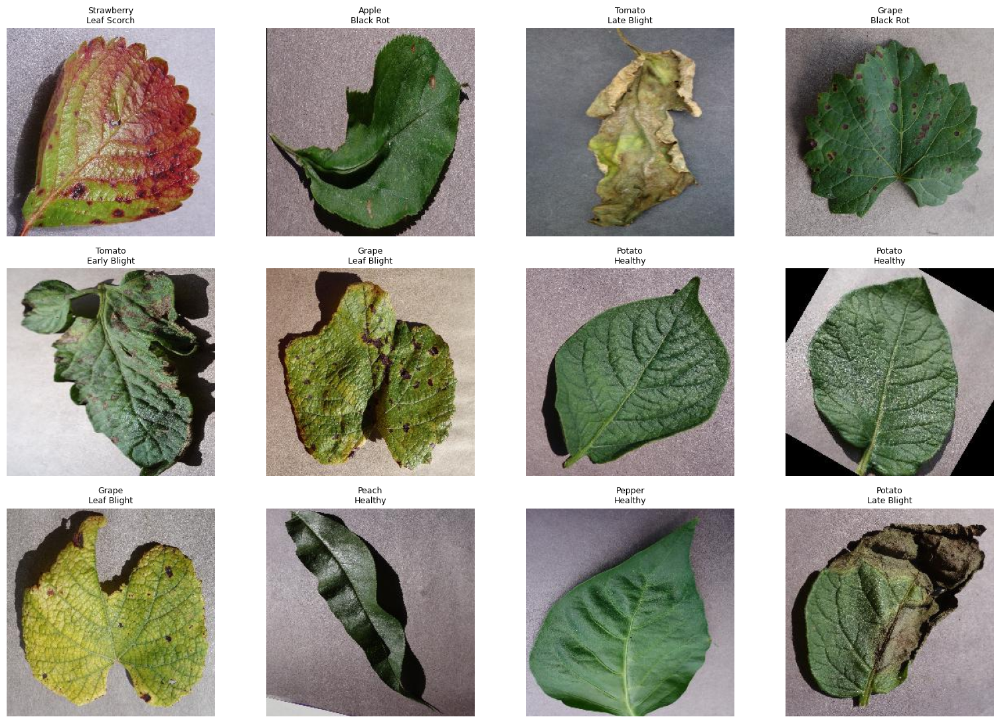

In [ ]:

from PIL import Image
import matplotlib.pyplot as plt
import random
from collections import Counter

# Collect training image paths
train_image_paths = [
    p for p in (RAW_DIR / "train").rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

# Use a fixed seed so we can reproduce the sample
random.seed(42)
sample_paths = random.sample(train_image_paths, 500)

# Inspect image dimensions and colour modes
dimensions = Counter()
colour_modes = Counter()

for image_path in sample_paths:
    with Image.open(image_path) as img:
        dimensions[img.size] += 1
        colour_modes[img.mode] += 1

print("IMAGE DIMENSIONS (width, height)")
for dimension, count in dimensions.most_common(10):
    print(f"{dimension}: {count} images")

print("\nIMAGE COLOUR MODES")
for mode, count in colour_modes.items():
    print(f"{mode}: {count} images")

# Display 12 sample images
display_paths = random.sample(train_image_paths, 12)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for ax, image_path in zip(axes, display_paths):
    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    relative_path = image_path.relative_to(RAW_DIR / "train")
    label = f"{relative_path.parts[0]}\n{relative_path.parts[1]}"

    ax.set_title(label, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()



## Dataset Exploration and Initial Findings

The Plant Disease Detection dataset was obtained from Kaggle:
https://www.kaggle.com/datasets/mgmitesh/plant-disease-detection-dataset

The dataset is licensed under Creative Commons Attribution 4.0 International (CC BY 4.0).

### Dataset Summary

- Training images: 49,984
- Validation images: 12,494
- Test images: 39
- Number of plant-disease classes: 27
- Total images: 62,517

### Image Properties

A random sample of 500 training images was inspected.

- Image dimensions: 256 × 256 pixels
- Colour mode: RGB
- All 500 sampled images had consistent dimensions and colour modes.

### Initial Observations

1. The dataset contains images from nine plant species.
2. Each class represents a specific plant and its disease condition.
3. The training and validation datasets contain all 27 classes.
4. Most training classes contain approximately 1,600–2,000 images.
5. The test dataset contains 39 images with labels apparently encoded in their filenames. These labels will be verified before evaluation.

### Preprocessing Considerations

Images will be converted into numerical tensors, pixel values will be normalised, and batches will be prepared for model training. The original training and validation splits will be preserved to avoid data leakage.


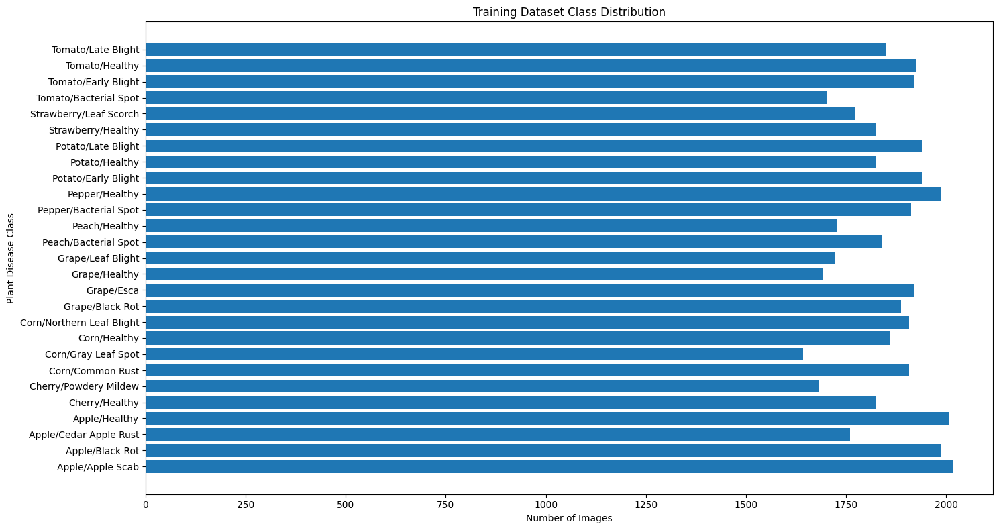

Largest class: Apple/Apple Scab
Smallest class: Corn/Gray Leaf Spot


In [ ]:
import matplotlib.pyplot as plt

classes = list(sorted(train_counts.keys()))
image_counts = [train_counts[c] for c in classes]

plt.figure(figsize=(15, 8))
plt.barh(classes, image_counts)

plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Class")
plt.title("Training Dataset Class Distribution")
plt.tight_layout()
plt.show()

print("Largest class:", max(train_counts, key=train_counts.get))
print("Smallest class:", min(train_counts, key=train_counts.get))



### Class Distribution Analysis

The training dataset contains 27 plant-disease classes.

The class distribution was visualised using a horizontal bar chart.

Key findings:

- Largest class: Apple/Apple Scab (2,016 images).
- Smallest class: Corn/Gray Leaf Spot (1,642 images).
- The difference between the largest and smallest classes is 374 images.
- The average number of images per class is approximately 1,851.

The dataset is reasonably balanced, with no severe class imbalance observed. Therefore, class balancing techniques such as oversampling and undersampling will not be applied initially.

Image augmentation may still be used to improve the model's ability to generalise to unseen images.


In [ ]:

import tensorflow as tf
import numpy as np
import json
from pathlib import Path

print("TensorFlow version:", tf.__version__)
print("Available GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
Available GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

TRAIN_DIR = RAW_DIR / "train"
VALID_DIR = RAW_DIR / "valid"

# Preserve both plant and disease names
class_names = sorted(train_counts.keys())

# Assign each class a unique integer
class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

print("Number of classes:", len(class_names))
print("\nClass-to-index mapping:")

for name, index in class_to_index.items():
    print(f"{index}: {name}")

# Verify training and validation have identical classes
assert set(train_counts.keys()) == set(valid_counts.keys())

# Save the mapping for future predictions and deployment
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

with open(MODELS_DIR / "class_names.json", "w") as file:
    json.dump(class_names, file, indent=4)

print("\nClass mapping saved successfully!")


Number of classes: 27

Class-to-index mapping:
0: Apple/Apple Scab
1: Apple/Black Rot
2: Apple/Cedar Apple Rust
3: Apple/Healthy
4: Cherry/Healthy
5: Cherry/Powdery Mildew
6: Corn/Common Rust
7: Corn/Gray Leaf Spot
8: Corn/Healthy
9: Corn/Northern Leaf Blight
10: Grape/Black Rot
11: Grape/Esca
12: Grape/Healthy
13: Grape/Leaf Blight
14: Peach/Bacterial Spot
15: Peach/Healthy
16: Pepper/Bacterial Spot
17: Pepper/Healthy
18: Potato/Early Blight
19: Potato/Healthy
20: Potato/Late Blight
21: Strawberry/Healthy
22: Strawberry/Leaf Scorch
23: Tomato/Bacterial Spot
24: Tomato/Early Blight
25: Tomato/Healthy
26: Tomato/Late Blight

Class mapping saved successfully!


In [ ]:

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def collect_image_data(directory):
    paths = []
    labels = []

    for image_path in Path(directory).rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            relative_path = image_path.relative_to(directory)

            if len(relative_path.parts) < 3:
                continue

            class_name = f"{relative_path.parts[0]}/{relative_path.parts[1]}"

            if class_name not in class_to_index:
                continue

            paths.append(str(image_path))
            labels.append(class_to_index[class_name])

    return paths, labels


# Collect training and validation images
train_paths, train_labels = collect_image_data(TRAIN_DIR)
valid_paths, valid_labels = collect_image_data(VALID_DIR)

print("Training images:", len(train_paths))
print("Validation images:", len(valid_paths))


# Load, decode and resize images
def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


# Create training pipeline
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = (
    train_ds
    .shuffle(1000, seed=42)
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# Create validation pipeline
valid_ds = tf.data.Dataset.from_tensor_slices(
    (valid_paths, valid_labels)
)

valid_ds = (
    valid_ds
    .map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("\nTensorFlow datasets created successfully!")


Training images: 49984
Validation images: 12494

TensorFlow datasets created successfully!


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 251.63785


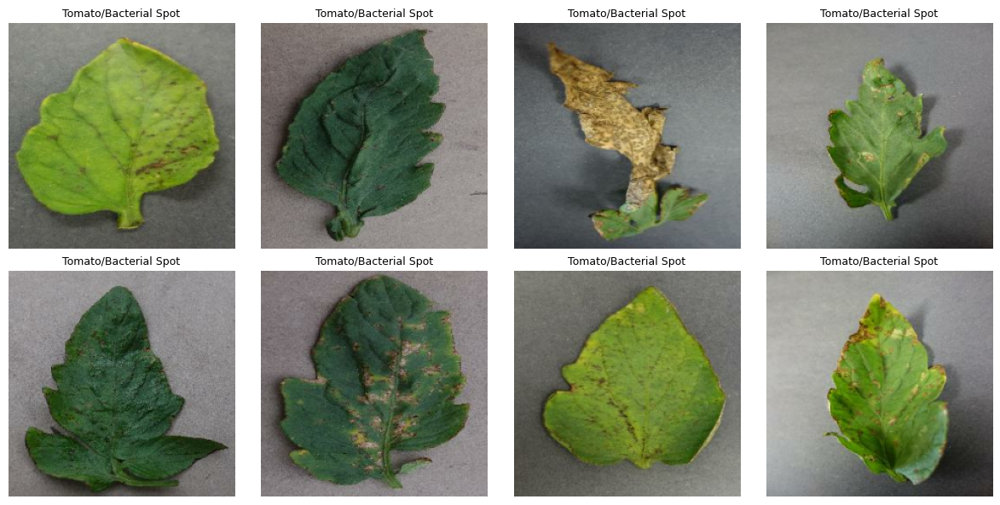

In [ ]:

# Get one batch of training images
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

# Display a few processed images
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(tf.cast(images[i], tf.uint8))

    label_index = int(labels[i].numpy())
    plt.title(class_names[label_index], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, Model

NUM_CLASSES = len(class_names)

# Load MobileNetV2 with ImageNet weights
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Number of classes:", NUM_CLASSES)
print("Base model trainable:", base_model.trainable)
print("Base model output shape:", base_model.output_shape)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully!
Number of classes: 27
Base model trainable: False
Base model output shape: (None, 7, 7, 1280)


In [ ]:
# Input images have pixel values between 0 and 255
inputs = layers.Input(shape=(224, 224, 3))

# Apply MobileNetV2-specific preprocessing
x = layers.Lambda(preprocess_input)(inputs)

# Extract image features
x = base_model(x, training=False)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Predict probabilities for the 27 classes
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# Create complete model
model = Model(inputs, outputs, name="PlantCare_MobileNetV2")

print("PlantCare model created successfully!")


PlantCare model created successfully!


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "PlantCare_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 27)             │        34,587 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,292,571 (8.75 MB)

 Trainable params: 34,587 (135.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Create a directory for model checkpoints
CHECKPOINT_DIR = PROJECT_DIR / "models" / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = CHECKPOINT_DIR / "best_model_phase1.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]

print("Training callbacks configured successfully!")


Training callbacks configured successfully!


IMAGE QUALITY REPORT
Images inspected: 500
Image dimensions: [((256, 256), 500)]
Colour modes: Counter({'RGB': 500})
Corrupted images: 0


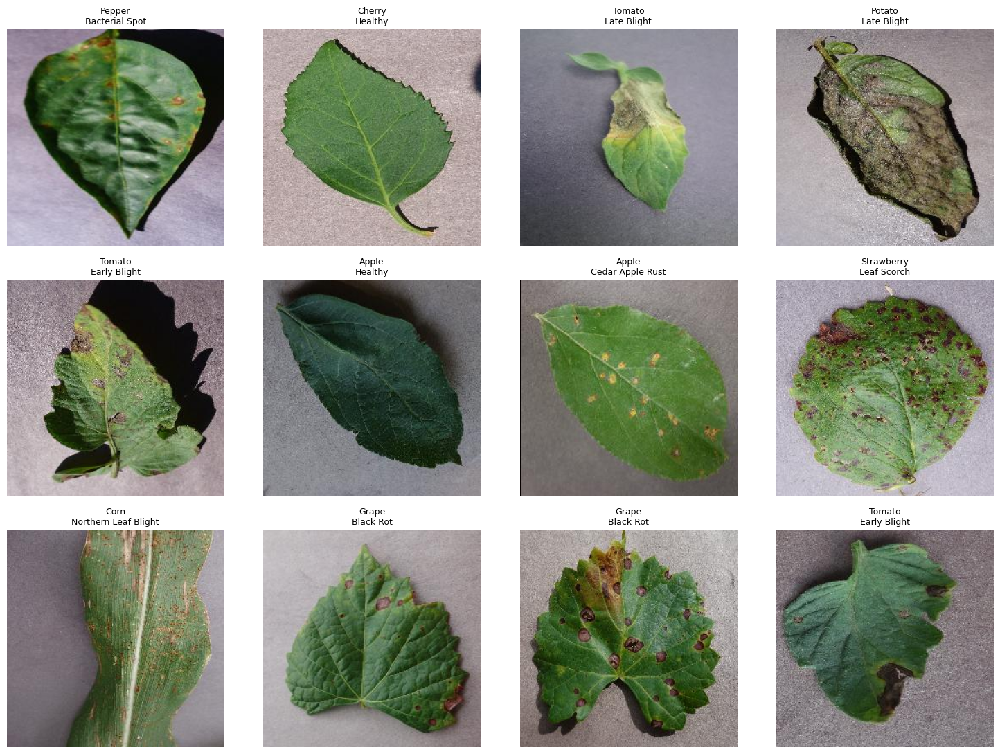

In [ ]:

import os
import random
from PIL import Image
import matplotlib.pyplot as plt
from collections import Counter

TRAIN_DIR = os.path.join(RAW_DIR, "train")

# Collect all training image paths
image_paths = []

for root, dirs, files in os.walk(TRAIN_DIR):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(root, file))

# Randomly inspect 500 images
sample_paths = random.sample(
    image_paths,
    min(500, len(image_paths))
)

dimensions = Counter()
color_modes = Counter()
corrupted = []

for path in sample_paths:
    try:
        with Image.open(path) as img:
            dimensions[img.size] += 1
            color_modes[img.mode] += 1
            img.verify()
    except Exception:
        corrupted.append(path)

print("IMAGE QUALITY REPORT")
print("=" * 45)
print("Images inspected:", len(sample_paths))
print("Image dimensions:", dimensions.most_common(10))
print("Colour modes:", color_modes)
print("Corrupted images:", len(corrupted))

# Display 12 random images
display_paths = random.sample(sample_paths, 12)

fig, axes = plt.subplots(3, 4, figsize=(15, 11))

for ax, path in zip(axes.flat, display_paths):
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))

    plant = os.path.basename(
        os.path.dirname(os.path.dirname(path))
    )

    disease = os.path.basename(os.path.dirname(path))

    ax.set_title(f"{plant}\n{disease}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os
import json
import pandas as pd
from pathlib import Path

# Project directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/PlantCare_ML_Cycle"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Supported image formats
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def build_manifest(split):
    split_dir = RAW_DIR / split
    records = []

    for plant_dir in sorted(split_dir.iterdir()):
        if not plant_dir.is_dir():
            continue

        plant = plant_dir.name

        for disease_dir in sorted(plant_dir.iterdir()):
            if not disease_dir.is_dir():
                continue

            disease = disease_dir.name

            # Combine plant and disease into one class
            class_name = f"{plant}___{disease}"

            for image_path in disease_dir.iterdir():
                if image_path.suffix.lower() in IMAGE_EXTENSIONS:
                    records.append({
                        "image_path": str(image_path),
                        "plant": plant,
                        "disease": disease,
                        "class_name": class_name
                    })

    return pd.DataFrame(records)


# Create manifests
train_df = build_manifest("train")
valid_df = build_manifest("valid")

# Generate consistent class mapping
class_names = sorted(train_df["class_name"].unique())

class_to_idx = {
    name: index
    for index, name in enumerate(class_names)
}

# Apply numerical labels
train_df["label"] = train_df["class_name"].map(class_to_idx)
valid_df["label"] = valid_df["class_name"].map(class_to_idx)

# Verify class consistency
assert set(train_df["class_name"]) == set(valid_df["class_name"])

# Save manifests
train_df.to_csv(
    PROCESSED_DIR / "train_manifest.csv",
    index=False
)

valid_df.to_csv(
    PROCESSED_DIR / "valid_manifest.csv",
    index=False
)

# Save class mapping
with open(PROCESSED_DIR / "class_to_idx.json", "w") as f:
    json.dump(class_to_idx, f, indent=4)

# Save project checkpoint
checkpoint = {
    "project": "PlantCare ML Cycle",
    "dataset_verified": True,
    "image_quality_inspection": "passed_on_500_sampled_images",
    "image_size": [256, 256],
    "color_mode": "RGB",
    "num_classes": len(class_names),
    "train_images": len(train_df),
    "validation_images": len(valid_df),
    "class_mapping_saved": True,
    "manifests_saved": True
}

with open(PROCESSED_DIR / "project_checkpoint.json", "w") as f:
    json.dump(checkpoint, f, indent=4)

# Display results
print("DATASET MANIFEST CREATION COMPLETE")
print("=" * 45)
print("Training images:", len(train_df))
print("Validation images:", len(valid_df))
print("Number of classes:", len(class_names))

print("\nCLASS MAPPING:")
for name, index in class_to_idx.items():
    print(f"{index}: {name}")

print("\nSAVED FILES:")
for file in PROCESSED_DIR.iterdir():
    print(file.name)

assert len(train_df) == 49984
assert len(valid_df) == 12494
assert len(class_names) == 27

print("\nALL CHECKS PASSED!")


DATASET MANIFEST CREATION COMPLETE
Training images: 49984
Validation images: 12494
Number of classes: 27

CLASS MAPPING:
0: Apple___Apple Scab
1: Apple___Black Rot
2: Apple___Cedar Apple Rust
3: Apple___Healthy
4: Cherry___Healthy
5: Cherry___Powdery Mildew
6: Corn___Common Rust
7: Corn___Gray Leaf Spot
8: Corn___Healthy
9: Corn___Northern Leaf Blight
10: Grape___Black Rot
11: Grape___Esca
12: Grape___Healthy
13: Grape___Leaf Blight
14: Peach___Bacterial Spot
15: Peach___Healthy
16: Pepper___Bacterial Spot
17: Pepper___Healthy
18: Potato___Early Blight
19: Potato___Healthy
20: Potato___Late Blight
21: Strawberry___Healthy
22: Strawberry___Leaf Scorch
23: Tomato___Bacterial Spot
24: Tomato___Early Blight
25: Tomato___Healthy
26: Tomato___Late Blight

SAVED FILES:
train_manifest.csv
valid_manifest.csv
class_to_idx.json
project_checkpoint.json

ALL CHECKS PASSED!


In [ ]:

import os
import json
import pandas as pd
import tensorflow as tf
from pathlib import Path

# Project directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/PlantCare_ML_Cycle"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Load saved manifests
train_df = pd.read_csv(
    PROCESSED_DIR / "train_manifest.csv"
)

valid_df = pd.read_csv(
    PROCESSED_DIR / "valid_manifest.csv"
)

with open(PROCESSED_DIR / "class_to_idx.json") as f:
    class_to_idx = json.load(f)

# Configuration
IMG_SIZE = (256, 256)
BATCH_SIZE = 32
NUM_CLASSES = len(class_to_idx)
SEED = 42

AUTOTUNE = tf.data.AUTOTUNE

# Image loading function
def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    # Normalize pixel values
    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.int32)

    return image, label


# Build dataset function
def create_dataset(df, training=False):

    paths = df["image_path"].values
    labels = df["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=5000,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Create datasets
train_ds = create_dataset(
    train_df,
    training=True
)

valid_ds = create_dataset(
    valid_df,
    training=False
)

print("TENSORFLOW DATA PIPELINE CREATED")
print("=" * 45)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(valid_ds).numpy())

print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Image size:", IMG_SIZE)


TENSORFLOW DATA PIPELINE CREATED
Training batches: 1562
Validation batches: 391
Number of classes: 27
Batch size: 32
Image size: (256, 256)


In [ ]:

# Get one batch
images, labels = next(iter(train_ds))

print("IMAGE BATCH TEST")
print("=" * 40)

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("Labels in batch:", labels.numpy())

assert images.shape[1:] == (256, 256, 3)
assert images.shape[0] == BATCH_SIZE
assert tf.reduce_min(images).numpy() >= 0
assert tf.reduce_max(images).numpy() <= 1

print("\nALL PIPELINE CHECKS PASSED!")


IMAGE BATCH TEST
Image shape: (32, 256, 256, 3)
Label shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Labels in batch: [0 1 1 0 1 1 0 2 0 0 1 0 1 2 0 1 0 1 2 1 0 1 0 0 0 0 2 0 2 2 1 0]

ALL PIPELINE CHECKS PASSED!


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Data augmentation
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10)
], name="data_augmentation")

print("DATA AUGMENTATION CREATED")
print(data_augmentation.summary())


DATA AUGMENTATION CREATED


Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


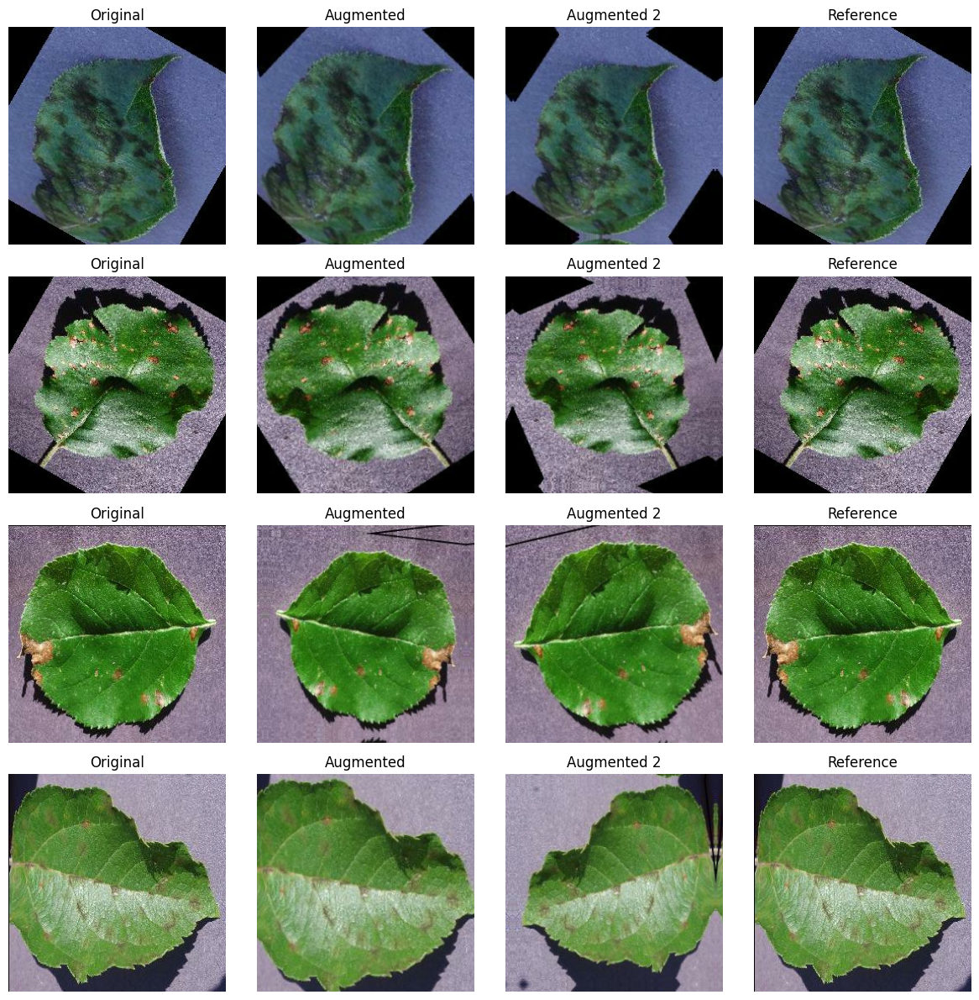

Original shape: (32, 256, 256, 3)
Augmented shape: (32, 256, 256, 3)
Augmentation inspection complete!


In [ ]:

import matplotlib.pyplot as plt

# Get a batch of training images
images, labels = next(iter(train_ds))

# Apply augmentation
augmented_images = data_augmentation(
    images,
    training=True
)

# Display original and augmented images
fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i in range(4):
    # Original
    axes[i, 0].imshow(images[i].numpy())
    axes[i, 0].set_title("Original")

    # Augmented
    axes[i, 1].imshow(augmented_images[i].numpy())
    axes[i, 1].set_title("Augmented")

    # Another augmented version
    second_aug = data_augmentation(
        images[i:i+1],
        training=True
    )[0]

    axes[i, 2].imshow(second_aug.numpy())
    axes[i, 2].set_title("Augmented 2")

    # Original again for reference
    axes[i, 3].imshow(images[i].numpy())
    axes[i, 3].set_title("Reference")

    for j in range(4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

print("Original shape:", images.shape)
print("Augmented shape:", augmented_images.shape)
print("Augmentation inspection complete!")


In [ ]:

# Get a batch of images
images, labels = next(iter(train_ds))

# Apply augmentation
augmented_images = data_augmentation(
    images,
    training=True
)

print("AUGMENTATION TEST")
print("==========================")
print("Original shape:", images.shape)
print("Augmented shape:", augmented_images.shape)
print("Number of layers:", len(data_augmentation.layers))

print("\nAUGMENTATION LAYER SUMMARY")
data_augmentation.summary()

print("\nAugmentation test completed!")


AUGMENTATION TEST
Original shape: (32, 256, 256, 3)
Augmented shape: (32, 256, 256, 3)
Number of layers: 3

AUGMENTATION LAYER SUMMARY


Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (32, 256, 256, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (32, 256, 256, 3)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Augmentation test completed!


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    # Input
    layers.Input(shape=(256, 256, 3)),

    # Data augmentation
    data_augmentation,

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="plant_disease_cnn")

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "plant_disease_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 27)             │         3,483 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,139 (445.86 KB)

 Trainable params: 113,691 (444.11 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
from pathlib import Path
import json

# Create checkpoint directories
MODEL_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR = MODEL_DIR / "checkpoints"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Save current project progress
checkpoint = {
    "project": "PlantCare ML Cycle",
    "stage": "CNN architecture completed",
    "image_size": [256, 256],
    "batch_size": BATCH_SIZE,
    "num_classes": NUM_CLASSES,
    "architecture": "plant_disease_cnn",
    "total_parameters": int(model.count_params()),
    "dataset": {
        "train_images": 49984,
        "validation_images": 12494,
        "classes": 27
    }
}

checkpoint_path = PROJECT_DIR / "data" / "processed" / "project_checkpoint.json"

with open(checkpoint_path, "w") as f:
    json.dump(checkpoint, f, indent=4)

print("Checkpoint information saved!")
print("Location:", checkpoint_path)
print("Model parameters:", model.count_params())

Checkpoint information saved!
Location: /content/drive/MyDrive/PlantCare_ML_Cycle/data/processed/project_checkpoint.json
Model parameters: 114139


In [ ]:
from tensorflow import keras

# 1. Save the best model during training
model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(CHECKPOINT_DIR / "best_plant_disease_model.keras"),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

# 2. Stop training when validation performance stops improving
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# 3. Reduce learning rate when validation loss stops improving
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    model_checkpoint,
    early_stopping,
    reduce_lr
]

print("TRAINING CALLBACKS CONFIGURED")
print("================================")
print("ModelCheckpoint: Ready")
print("EarlyStopping: Ready")
print("ReduceLROnPlateau: Ready")
print("Best model will be saved in:", CHECKPOINT_DIR)

TRAINING CALLBACKS CONFIGURED
ModelCheckpoint: Ready
EarlyStopping: Ready
ReduceLROnPlateau: Ready
Best model will be saved in: /content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints


In [ ]:
from pathlib import Path

# Original dataset locations
ORIGINAL_TRAIN_DIR = RAW_DIR / "train"
ORIGINAL_VALID_DIR = RAW_DIR / "valid"

# Convert original paths to local paths
def update_image_paths(df, original_root, local_root):
    df = df.copy()

    df["image_path"] = df["image_path"].apply(
        lambda path: str(
            local_root / Path(path).relative_to(original_root)
        )
    )

    return df

train_df = update_image_paths(
    train_df, ORIGINAL_TRAIN_DIR, LOCAL_TRAIN_DIR
)

valid_df = update_image_paths(
    valid_df, ORIGINAL_VALID_DIR, LOCAL_VALID_DIR
)

# Verify every image exists
missing_train = sum(
    not Path(p).is_file() for p in train_df["image_path"]
)

missing_valid = sum(
    not Path(p).is_file() for p in valid_df["image_path"]
)

print("LOCAL PATH VERIFICATION")
print("==============================")
print("Training images:", len(train_df))
print("Validation images:", len(valid_df))
print("Missing training images:", missing_train)
print("Missing validation images:", missing_valid)

print("\nUPDATED SAMPLE PATH")
print(train_df["image_path"].iloc[0])

assert missing_train == 0, "Some training images are missing!"
assert missing_valid == 0, "Some validation images are missing!"

print("\nSUCCESS: All manifest paths point to existing local images!")

LOCAL PATH VERIFICATION
Training images: 49984
Validation images: 12494
Missing training images: 0
Missing validation images: 0

UPDATED SAMPLE PATH
/content/plantcare_local/train/Apple/Apple Scab/82f4f2fc-b28e-4834-95b8-3d7b144f8b15___FREC_Scab 3063_90deg.JPG

SUCCESS: All manifest paths point to existing local images!


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Configure GPU memory growth
gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# Enable mixed precision
keras.mixed_precision.set_global_policy("mixed_float16")

print("MIXED PRECISION CONFIGURATION")
print("================================")
print("Policy:", keras.mixed_precision.global_policy())
print("GPU:", gpus)

MIXED PRECISION CONFIGURATION
Policy: <DTypePolicy "mixed_float16">
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = 27

# Data augmentation
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10)
], name="data_augmentation")

# CNN architecture
model = keras.Sequential([
    layers.Input(shape=(256, 256, 3)),

    data_augmentation,

    # Block 1
    layers.Conv2D(32, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    # Block 2
    layers.Conv2D(64, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    # Block 3
    layers.Conv2D(128, 3, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # Float32 output for numerical stability
    layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        dtype="float32"
    )
], name="plant_disease_cnn")

# Compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "plant_disease_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 27)             │         3,483 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,139 (445.86 KB)

 Trainable params: 113,691 (444.11 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
import time
import numpy as np
from tensorflow import keras

# Save initial model weights
initial_weights = model.get_weights()

# Measure individual batch durations
class BatchTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.batch_times = []

    def on_train_batch_begin(self, batch, logs=None):
        self.batch_start = time.perf_counter()

    def on_train_batch_end(self, batch, logs=None):
        elapsed = time.perf_counter() - self.batch_start
        self.batch_times.append(elapsed)


timer = BatchTimer()

print("STARTING 35-BATCH BENCHMARK")
print("==============================")

start_time = time.perf_counter()

model.fit(
    train_ds.take(35),
    epochs=1,
    callbacks=[timer],
    verbose=1
)

total_time = time.perf_counter() - start_time

# Exclude the first 5 batches for GPU warm-up
measured_times = timer.batch_times[5:]

average_batch_time = np.mean(measured_times)
estimated_epoch_time = average_batch_time * len(train_ds)

# Restore original weights
model.set_weights(initial_weights)

print("\nBENCHMARK RESULTS")
print("==============================")
print(f"Total benchmark time: {total_time:.2f} seconds")
print(f"Measured batches: {len(measured_times)}")
print(f"Average batch time: {average_batch_time:.3f} seconds")
print(f"Estimated epoch time: {estimated_epoch_time / 60:.2f} minutes")
print("Original model weights restored.")

STARTING 35-BATCH BENCHMARK
35/35 ━━━━━━━━━━━━━━━━━━━━ 16s 154ms/step - accuracy: 0.7045 - loss: 1.0186

BENCHMARK RESULTS
Total benchmark time: 16.10 seconds
Measured batches: 30
Average batch time: 0.152 seconds
Estimated epoch time: 3.95 minutes
Original model weights restored.


In [ ]:
from pathlib import Path
import json
import time
from tensorflow import keras

MODEL_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(CHECKPOINT_DIR / "best_plant_disease_model.keras"),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

csv_logger = keras.callbacks.CSVLogger(
    str(MODEL_DIR / "training_history.csv"),
    append=False
)

callbacks = [
    model_checkpoint,
    early_stopping,
    reduce_lr,
    csv_logger
]

print("ALL CALLBACKS READY")
print("Checkpoint:", CHECKPOINT_DIR)
print("Training history:", MODEL_DIR / "training_history.csv")

ALL CALLBACKS READY
Checkpoint: /content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints
Training history: /content/drive/MyDrive/PlantCare_ML_Cycle/models/training_history.csv


In [ ]:
start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

training_time = time.time() - start_time

print("\nTRAINING COMPLETED")
print("==============================")
print(f"Training time: {training_time / 60:.2f} minutes")
print(f"Epochs completed: {len(history.history['loss'])}")
print(f"Best training accuracy: {max(history.history['accuracy']):.4f}")
print(f"Best validation accuracy: {max(history.history['val_accuracy']):.4f}")
print(f"Best validation loss: {min(history.history['val_loss']):.4f}")

Epoch 1/20
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.7440 - loss: 0.8807
Epoch 1: val_accuracy improved from None to 0.20914, saving model to /content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints/best_plant_disease_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints/best_plant_disease_model.keras
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 241s 154ms/step - accuracy: 0.7391 - loss: 0.9127 - val_accuracy: 0.2091 - val_loss: 4.3441 - learning_rate: 0.0010
Epoch 2/20
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.7947 - loss: 0.6988
Epoch 2: val_accuracy improved from 0.20914 to 0.23291, saving model to /content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints/best_plant_disease_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints/best_plant_disease_model.keras
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 238s 152ms/step - accuracy: 0.8164 - loss: 0.5857 - val_accurac

In [ ]:

import os
import json
import zipfile
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. DEFINE PROJECT PATHS
# --------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/PlantCare_ML_Cycle"
)

ZIP_PATH = PROJECT_DIR / "data/raw/plant-disease-detection-dataset.zip"

LOCAL_DIR = Path("/content/plantcare_local")

PROCESSED_DIR = PROJECT_DIR / "data/processed"

print("=" * 65)
print("STEP 1: RESTORING DATASET")
print("=" * 65)

# --------------------------------------------------
# 2. EXTRACT DATASET
# --------------------------------------------------

if not LOCAL_DIR.exists():
    LOCAL_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(LOCAL_DIR)

    print("Dataset extraction completed!")
else:
    print("Local dataset folder already exists. Skipping extraction.")

# --------------------------------------------------
# 3. LOAD EXISTING MANIFESTS
# --------------------------------------------------

print("\n" + "=" * 65)
print("STEP 2: RESTORING MANIFEST PATHS")
print("=" * 65)

train_df = pd.read_csv(
    PROCESSED_DIR / "train_manifest.csv"
)

valid_df = pd.read_csv(
    PROCESSED_DIR / "valid_manifest.csv"
)

# Convert original Drive paths to local paths
def restore_local_path(original_path):
    marker = "/data/raw/"

    if marker not in original_path:
        raise ValueError(
            f"Unexpected manifest path: {original_path}"
        )

    relative_path = original_path.split(marker, 1)[1]

    return str(LOCAL_DIR / relative_path)

train_df["image_path"] = train_df["image_path"].apply(
    restore_local_path
)

valid_df["image_path"] = valid_df["image_path"].apply(
    restore_local_path
)

# --------------------------------------------------
# 4. VERIFY CLASS MAPPING
# --------------------------------------------------

print("\n" + "=" * 65)
print("STEP 3: RECONSTRUCTING CLASS MAPPING")
print("=" * 65)

class_pairs = pd.concat([
    train_df[["class_name", "label"]],
    valid_df[["class_name", "label"]]
]).drop_duplicates()

if class_pairs["class_name"].duplicated().any():
    raise ValueError("A class has multiple label assignments.")

if class_pairs["label"].duplicated().any():
    raise ValueError("A label is assigned to multiple classes.")

class_pairs = class_pairs.sort_values("label")

assert len(class_pairs) == 27, "Expected 27 classes."
assert class_pairs["label"].tolist() == list(range(27))

class_mapping = {
    row["class_name"]: int(row["label"])
    for _, row in class_pairs.iterrows()
}

mapping_path = PROCESSED_DIR / "class_mapping.json"

with open(mapping_path, "w") as f:
    json.dump(class_mapping, f, indent=4)

print("Class mapping restored:", len(class_mapping), "classes")
print("Saved to:", mapping_path)

# --------------------------------------------------
# 5. SAVE UPDATED MANIFESTS
# --------------------------------------------------

train_df.to_csv(
    PROCESSED_DIR / "train_manifest.csv",
    index=False
)

valid_df.to_csv(
    PROCESSED_DIR / "valid_manifest.csv",
    index=False
)

print("\nUpdated manifests saved.")

# --------------------------------------------------
# 6. VERIFY ALL IMAGE PATHS
# --------------------------------------------------

print("\n" + "=" * 65)
print("STEP 4: VERIFYING IMAGE FILES")
print("=" * 65)

train_exists = train_df["image_path"].apply(
    lambda p: Path(p).is_file()
)

valid_exists = valid_df["image_path"].apply(
    lambda p: Path(p).is_file()
)

print("Training images:", len(train_df))
print("Training images found:", train_exists.sum())
print("Missing training images:", (~train_exists).sum())

print("\nValidation images:", len(valid_df))
print("Validation images found:", valid_exists.sum())
print("Missing validation images:", (~valid_exists).sum())

# --------------------------------------------------
# 7. VERIFY DATASET SPLITS
# --------------------------------------------------

print("\n" + "=" * 65)
print("STEP 5: DATASET SPLIT VERIFICATION")
print("=" * 65)

for split in ["train", "valid", "test"]:
    folder = LOCAL_DIR / split

    if folder.exists():
        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file()
        )
        print(f"{split}: {count} files")
    else:
        print(f"{split}: MISSING")

print("\n" + "=" * 65)
print("DATASET RECOVERY COMPLETE")
print("=" * 65)

if train_exists.all() and valid_exists.all():
    print("SUCCESS: All training and validation paths verified.")
else:
    print("WARNING: Some image paths are missing.")


STEP 1: RESTORING DATASET
Dataset extraction completed!

STEP 2: RESTORING MANIFEST PATHS

STEP 3: RECONSTRUCTING CLASS MAPPING
Class mapping restored: 27 classes
Saved to: /content/drive/MyDrive/PlantCare_ML_Cycle/data/processed/class_mapping.json

Updated manifests saved.

STEP 4: VERIFYING IMAGE FILES
Training images: 49984
Training images found: 49984
Missing training images: 0

Validation images: 12494
Validation images found: 12494
Missing validation images: 0

STEP 5: DATASET SPLIT VERIFICATION
train: 49984 files
valid: 12494 files
test: 39 files

DATASET RECOVERY COMPLETE
SUCCESS: All training and validation paths verified.


In [ ]:

import tensorflow as tf
import pandas as pd
import numpy as np
from pathlib import Path

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

IMAGE_SIZE = (256, 256)
BATCH_SIZE = 32
NUM_CLASSES = 27
AUTOTUNE = tf.data.AUTOTUNE

PROJECT_DIR = Path(
    "/content/drive/MyDrive/PlantCare_ML_Cycle"
)

PROCESSED_DIR = PROJECT_DIR / "data/processed"

train_df = pd.read_csv(PROCESSED_DIR / "train_manifest.csv")
valid_df = pd.read_csv(PROCESSED_DIR / "valid_manifest.csv")

print("=" * 65)
print("REBUILDING TENSORFLOW DATASETS")
print("=" * 65)

# --------------------------------------------------
# 2. IMAGE LOADING AND PREPROCESSING
# --------------------------------------------------

def load_and_preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.int32)

    return image, label

# --------------------------------------------------
# 3. CREATE DATASETS
# --------------------------------------------------

def create_dataset(dataframe, training=False):

    paths = dataframe["image_path"].values
    labels = dataframe["label"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=10000,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, training=True)
valid_ds = create_dataset(valid_df, training=False)

# --------------------------------------------------
# 4. VERIFY DATASETS
# --------------------------------------------------

print("\nDATASET SUMMARY")
print("-" * 50)

print("Training images:", len(train_df))
print("Validation images:", len(valid_df))

print("Training batches:",
      tf.data.experimental.cardinality(train_ds).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(valid_ds).numpy())

print("\nCHECKING FIRST TRAINING BATCH")

images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))
print("Label range:",
      int(tf.reduce_min(labels)),
      "to",
      int(tf.reduce_max(labels)))

print("\nCHECKING FIRST VALIDATION BATCH")

val_images, val_labels = next(iter(valid_ds))

print("Validation image shape:", val_images.shape)
print("Validation label shape:", val_labels.shape)

print("\n" + "=" * 65)
print("TENSORFLOW DATASET REBUILD COMPLETE")
print("=" * 65)


REBUILDING TENSORFLOW DATASETS

DATASET SUMMARY
--------------------------------------------------
Training images: 49984
Validation images: 12494
Training batches: 1562
Validation batches: 391

CHECKING FIRST TRAINING BATCH
Image batch shape: (32, 256, 256, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Label range: 0 to 4

CHECKING FIRST VALIDATION BATCH
Validation image shape: (32, 256, 256, 3)
Validation label shape: (32,)

TENSORFLOW DATASET REBUILD COMPLETE


In [ ]:

import tensorflow as tf
import numpy as np
from pathlib import Path

# --------------------------------------------------
# 1. LOAD ORIGINAL SAVED MODEL
# --------------------------------------------------

MODEL_PATH = (
    "/content/drive/MyDrive/PlantCare_ML_Cycle/"
    "models/checkpoints/best_plant_disease_model.keras"
)

print("=" * 65)
print("PLANTCARE BASELINE MODEL EVALUATION")
print("=" * 65)

baseline_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

# --------------------------------------------------
# 2. CONFIGURE EVALUATION METRICS
# --------------------------------------------------

output_activation = baseline_model.layers[-1].activation.__name__

print("Output activation:", output_activation)

loss_function = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=(output_activation == "linear")
)

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00025
    ),
    loss=loss_function,
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# --------------------------------------------------
# 3. EVALUATE ON VALIDATION DATA
# --------------------------------------------------

print("\nEvaluating on all validation images...")
print("Please allow the evaluation to finish.")

results = baseline_model.evaluate(
    valid_ds,
    verbose=1
)

# --------------------------------------------------
# 4. DISPLAY RESULTS
# --------------------------------------------------

baseline_loss = results[0]
baseline_accuracy = results[1]

print("\n" + "=" * 65)
print("BASELINE EVALUATION RESULTS")
print("=" * 65)

print(f"Validation Loss: {baseline_loss:.4f}")
print(f"Validation Accuracy: {baseline_accuracy * 100:.2f}%")

print("\nModel parameters:", baseline_model.count_params())
print("Validation images evaluated:", len(valid_df))

print("\n" + "=" * 65)
print("BASELINE EVALUATION COMPLETE")
print("=" * 65)


PLANTCARE BASELINE MODEL EVALUATION
Output activation: softmax

Evaluating on all validation images...
Please allow the evaluation to finish.
391/391 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.5919 - loss: 1.7061

BASELINE EVALUATION RESULTS
Validation Loss: 1.7061
Validation Accuracy: 59.19%

Model parameters: 114139
Validation images evaluated: 12494

BASELINE EVALUATION COMPLETE


In [ ]:

# ============================================================
# PLANTCARE: MOBILENETV2 TRANSFER LEARNING MODEL
# ============================================================

import tensorflow as tf
import os

print("=" * 65)
print("BUILDING PLANTCARE MOBILENETV2 MODEL")
print("=" * 65)

# 1. Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(256, 256, 3),
    include_top=False,
    weights="imagenet"
)

# 2. Freeze pretrained layers for the first training stage
base_model.trainable = False

# 3. Define the new model
inputs = tf.keras.Input(shape=(256, 256, 3))

# Data augmentation
x = tf.keras.layers.RandomFlip("horizontal")(inputs)
x = tf.keras.layers.RandomRotation(0.05)(x)
x = tf.keras.layers.RandomZoom(0.1)(x)

# Convert [0, 1] pixels to [-1, 1]
x = tf.keras.layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(x)

# Extract pretrained visual features
x = base_model(x, training=False)

# Classification head
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    dtype="float32"
)(x)

# 4. Assemble model
mobilenet_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="plantcare_mobilenetv2"
)

# 5. Compile model
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Display architecture information
print("\nMODEL CREATED SUCCESSFULLY")
print("-" * 50)

print("Model name:", mobilenet_model.name)
print("Input shape:", mobilenet_model.input_shape)
print("Output shape:", mobilenet_model.output_shape)
print("Number of classes:", NUM_CLASSES)
print("Pretrained base:", base_model.name)
print("Base model trainable:", base_model.trainable)
print("Total parameters:", mobilenet_model.count_params())

print("\nTRAINABLE PARAMETERS:",
      sum(tf.size(v).numpy() for v in mobilenet_model.trainable_variables))

print("\nMODEL SUMMARY")
mobilenet_model.summary()


BUILDING PLANTCARE MOBILENETV2 MODEL


/tmp/ipykernel_2568/3703800270.py:13: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

MODEL CREATED SUCCESSFULLY
--------------------------------------------------
Model name: plantcare_mobilenetv2
Input shape: (None, 256, 256, 3)
Output shape: (None, 27)
Number of classes: 27
Pretrained base: mobilenetv2_1.00_224
Base model trainable: False
Total parameters: 2292571

TRAINABLE PARAMETERS: 34587

MODEL SUMMARY


Model: "plantcare_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 8, 8, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 27)             │        34,587 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,292,571 (8.75 MB)

 Trainable params: 34,587 (135.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# ============================================================
# PLANTCARE MOBILENETV2 - STAGE 1 TRAINING
# ============================================================

import os
import tensorflow as tf

print("=" * 65)
print("STARTING MOBILENETV2 FEATURE EXTRACTION")
print("=" * 65)

# Create separate output paths
checkpoint_dir = os.path.join(
    PROJECT_DIR, "models", "checkpoints"
)

os.makedirs(checkpoint_dir, exist_ok=True)

mobilenet_checkpoint = os.path.join(
    checkpoint_dir,
    "best_plantcare_mobilenetv2.keras"
)

mobilenet_history_path = os.path.join(
    PROJECT_DIR,
    "models",
    "mobilenetv2_training_history.csv"
)

# Training callbacks
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=mobilenet_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        mobilenet_history_path
    )
]

print("\nTraining images:", len(train_df))
print("Validation images:", len(valid_df))
print("Epochs planned: 8")
print("Batch size:", BATCH_SIZE)
print("Trainable parameters:",
      sum(tf.size(v).numpy()
          for v in mobilenet_model.trainable_variables))

print("\nStarting training...\n")

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)

print("\n" + "=" * 65)
print("STAGE 1 TRAINING COMPLETE")
print("=" * 65)

print("Best model saved:", mobilenet_checkpoint)
print("Training history saved:", mobilenet_history_path)


STARTING MOBILENETV2 FEATURE EXTRACTION

Training images: 49984
Validation images: 12494
Epochs planned: 8
Batch size: 32
Trainable parameters: 34587

Starting training...

Epoch 1/8
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8582 - loss: 0.4884
Epoch 1: val_loss improved from None to 0.26350, saving model to /content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints/best_plantcare_mobilenetv2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints/best_plantcare_mobilenetv2.keras
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 150s 91ms/step - accuracy: 0.9080 - loss: 0.3221 - val_accuracy: 0.9196 - val_loss: 0.2635 - learning_rate: 0.0010
Epoch 2/8
1562/1562 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.9630 - loss: 0.1174
Epoch 2: val_loss improved from 0.26350 to 0.18037, saving model to /content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints/best_plantcare_mobilenetv2.keras

Epoch 2: finished saving model to /content/drive/MyDri

In [ ]:

# ============================================================
# PLANTCARE MOBILENETV2 - SAVED MODEL EVALUATION
# ============================================================

import tensorflow as tf
import os

print("=" * 65)
print("VERIFYING SAVED MOBILENETV2 MODEL")
print("=" * 65)

# Load the best saved checkpoint
verified_model = tf.keras.models.load_model(
    mobilenet_checkpoint,
    compile=False
)

# Compile for evaluation
verified_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nSaved model loaded successfully.")
print("Model:", verified_model.name)
print("Parameters:", verified_model.count_params())

print("\nEvaluating on all validation images...\n")

evaluation = verified_model.evaluate(
    valid_ds,
    verbose=1
)

print("\n" + "=" * 65)
print("VERIFIED MOBILENETV2 RESULTS")
print("=" * 65)

print(f"Validation Loss: {evaluation[0]:.4f}")
print(f"Validation Accuracy: {evaluation[1] * 100:.2f}%")
print("Validation Images:", len(valid_df))

print("\nORIGINAL CNN BASELINE: 59.19%")
print(
    f"MOBILENETV2 IMPROVEMENT: "
    f"+{(evaluation[1] * 100) - 59.19:.2f} percentage points"
)

print("\nCheckpoint exists:", os.path.exists(mobilenet_checkpoint))
print(
    "Checkpoint size:",
    round(os.path.getsize(mobilenet_checkpoint) / (1024 * 1024), 2),
    "MB"
)


VERIFYING SAVED MOBILENETV2 MODEL

Saved model loaded successfully.
Model: plantcare_mobilenetv2
Parameters: 2292571

Evaluating on all validation images...

391/391 ━━━━━━━━━━━━━━━━━━━━ 28s 65ms/step - accuracy: 0.9612 - loss: 0.1184

VERIFIED MOBILENETV2 RESULTS
Validation Loss: 0.1184
Validation Accuracy: 96.12%
Validation Images: 12494

ORIGINAL CNN BASELINE: 59.19%
MOBILENETV2 IMPROVEMENT: +36.93 percentage points

Checkpoint exists: True
Checkpoint size: 9.58 MB


In [ ]:

from sklearn.metrics import classification_report
import numpy as np

print("=" * 65)
print("MOBILENETV2: CLASS-LEVEL EVALUATION")
print("=" * 65)

# Get the actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in valid_ds
])

# Generate predictions
y_prob = verified_model.predict(valid_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Generate classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print("=" * 65)
print(report)


MOBILENETV2: CLASS-LEVEL EVALUATION
391/391 ━━━━━━━━━━━━━━━━━━━━ 29s 68ms/step

CLASSIFICATION REPORT
                             precision    recall  f1-score   support

         Apple___Apple Scab     0.9912    0.8929    0.9395       504
          Apple___Black Rot     0.9858    0.9759    0.9808       497
   Apple___Cedar Apple Rust     0.9952    0.9364    0.9649       440
            Apple___Healthy     0.9877    0.9562    0.9717       502
           Cherry___Healthy     1.0000    0.9518    0.9753       456
    Cherry___Powdery Mildew     0.9951    0.9619    0.9782       420
         Corn___Common Rust     0.9855    0.9979    0.9917       477
      Corn___Gray Leaf Spot     0.9320    0.9024    0.9170       410
             Corn___Healthy     1.0000    0.9935    0.9968       465
Corn___Northern Leaf Blight     0.9162    0.9392    0.9275       477
          Grape___Black Rot     0.9564    0.9767    0.9665       472
               Grape___Esca     0.9769    0.9688    0.9728       480


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Generate predictions on the validation dataset
y_true = np.concatenate([
    labels.numpy() for _, labels in valid_ds
])

y_prob = verified_model.predict(valid_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Build confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Find the most frequent incorrect predictions
errors = []

for actual_idx in range(len(class_names)):
    for predicted_idx in range(len(class_names)):
        if actual_idx != predicted_idx and cm[actual_idx, predicted_idx] > 0:
            errors.append({
                "Actual Class": class_names[actual_idx],
                "Predicted As": class_names[predicted_idx],
                "Incorrect Predictions": cm[actual_idx, predicted_idx]
            })

errors_df = pd.DataFrame(errors)
errors_df = errors_df.sort_values(
    "Incorrect Predictions", ascending=False
)

print("=" * 70)
print("TOP 15 MOST COMMON MISCLASSIFICATIONS")
print("=" * 70)
display(errors_df.head(15))

# Examine Tomato Early Blight specifically
tomato_idx = class_names.index("Tomato___Early Blight")

print("\n" + "=" * 70)
print("TOMATO EARLY BLIGHT ERROR ANALYSIS")
print("=" * 70)

tomato_errors = errors_df[
    errors_df["Actual Class"] == "Tomato___Early Blight"
]

display(tomato_errors)

print("Total Tomato Early Blight images:", cm[tomato_idx].sum())
print("Correctly classified:", cm[tomato_idx, tomato_idx])
print("Misclassified:", cm[tomato_idx].sum() - cm[tomato_idx, tomato_idx])


391/391 ━━━━━━━━━━━━━━━━━━━━ 26s 65ms/step
TOP 15 MOST COMMON MISCLASSIFICATIONS


,Actual Class,Predicted As,Incorrect Predictions
112,Tomato___Early Blight,Tomato___Late Blight,56
58,Corn___Gray Leaf Spot,Corn___Northern Leaf Blight,38
62,Corn___Northern Leaf Blight,Corn___Gray Leaf Spot,26
111,Tomato___Early Blight,Tomato___Healthy,20
110,Tomato___Early Blight,Tomato___Bacterial Spot,19
64,Grape___Esca,Grape___Black Rot,15
40,Apple___Healthy,Tomato___Healthy,12
76,Pepper___Bacterial Spot,Pepper___Healthy,12
63,Grape___Black Rot,Grape___Esca,11
45,Cherry___Healthy,Tomato___Healthy,10



TOMATO EARLY BLIGHT ERROR ANALYSIS


,Actual Class,Predicted As,Incorrect Predictions
112,Tomato___Early Blight,Tomato___Late Blight,56
111,Tomato___Early Blight,Tomato___Healthy,20
110,Tomato___Early Blight,Tomato___Bacterial Spot,19
109,Tomato___Early Blight,Potato___Late Blight,7
108,Tomato___Early Blight,Pepper___Bacterial Spot,2
106,Tomato___Early Blight,Corn___Northern Leaf Blight,1
107,Tomato___Early Blight,Grape___Leaf Blight,1


Total Tomato Early Blight images: 480
Correctly classified: 374
Misclassified: 106


In [ ]:

import os
import json
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create evaluation reports directory
reports_dir = Path(PROJECT_DIR) / "reports" / "mobilenetv2"
reports_dir.mkdir(parents=True, exist_ok=True)

# Generate evaluation artifacts
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(y_true, y_pred)

# Overall metrics
metrics = {
    "model_name": "plantcare_mobilenetv2",
    "validation_accuracy": float(accuracy_score(y_true, y_pred)),
    "validation_loss": 0.1184,
    "macro_f1": float(report["macro avg"]["f1-score"]),
    "weighted_f1": float(report["weighted avg"]["f1-score"]),
    "validation_images": int(len(y_true)),
    "number_of_classes": int(len(class_names)),
    "baseline_accuracy": 0.5919,
    "improvement_percentage_points": round(
        (accuracy_score(y_true, y_pred) - 0.5919) * 100, 2
    )
}

# Save metrics
with open(reports_dir / "evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# Save classification report
pd.DataFrame(report).transpose().to_csv(
    reports_dir / "classification_report.csv"
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(reports_dir / "confusion_matrix.csv")

# Save misclassification analysis
errors_df.to_csv(
    reports_dir / "misclassification_analysis.csv",
    index=False
)

# Save model metadata
metadata = {
    "model_name": "plantcare_mobilenetv2",
    "architecture": "MobileNetV2 transfer learning",
    "input_shape": [256, 256, 3],
    "number_of_classes": 27,
    "pretrained_weights": "ImageNet",
    "checkpoint": str(mobilenet_checkpoint),
    "checkpoint_size_mb": round(
        os.path.getsize(mobilenet_checkpoint) / (1024 * 1024), 2
    ),
    "validation_metrics_file": "evaluation_metrics.json"
}

with open(reports_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("=" * 65)
print("EVALUATION ARTIFACTS SAVED SUCCESSFULLY")
print("=" * 65)

for file in sorted(reports_dir.iterdir()):
    print(f"{file.name} | {file.stat().st_size / 1024:.2f} KB")

print("\nEvaluation metrics:")
print(json.dumps(metrics, indent=4))


EVALUATION ARTIFACTS SAVED SUCCESSFULLY
classification_report.csv | 2.39 KB
confusion_matrix.csv | 2.54 KB
evaluation_metrics.json | 0.33 KB
misclassification_analysis.csv | 4.99 KB
model_metadata.json | 0.42 KB

Evaluation metrics:
{
    "model_name": "plantcare_mobilenetv2",
    "validation_accuracy": 0.961181367056187,
    "validation_loss": 0.1184,
    "macro_f1": 0.9614365797411525,
    "weighted_f1": 0.9611151583483388,
    "validation_images": 12494,
    "number_of_classes": 27,
    "baseline_accuracy": 0.5919,
    "improvement_percentage_points": 36.93
}


In [ ]:

print("VALIDATION DATAFRAME COLUMNS:")
print(valid_df.columns.tolist())

print("\nFIRST VALIDATION RECORD:")
print(valid_df.iloc[0].to_dict())

print("\nMODEL CHECKPOINT:")
print(mobilenet_checkpoint)
print("Exists:", os.path.exists(mobilenet_checkpoint))

print("\nCLASS NAMES:")
print("Number of classes:", len(class_names))
print(class_names[:5])


VALIDATION DATAFRAME COLUMNS:
['image_path', 'plant', 'disease', 'class_name', 'label']

FIRST VALIDATION RECORD:
{'image_path': '/content/plantcare_local/valid/Apple/Apple Scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335_270deg.JPG', 'plant': 'Apple', 'disease': 'Apple Scab', 'class_name': 'Apple___Apple Scab', 'label': 0}

MODEL CHECKPOINT:
/content/drive/MyDrive/PlantCare_ML_Cycle/models/checkpoints/best_plantcare_mobilenetv2.keras
Exists: True

CLASS NAMES:
Number of classes: 27
['Apple___Apple Scab', 'Apple___Black Rot', 'Apple___Cedar Apple Rust', 'Apple___Healthy', 'Cherry___Healthy']


In [ ]:

import numpy as np
from PIL import Image

def predict_plant_disease(image_path, model=verified_model, top_k=3):
    """
    Predict the plant disease from an uploaded leaf image.
    Returns the top predictions and confidence scores.
    """

    # Load image and convert to RGB
    image = Image.open(image_path).convert("RGB")

    # Resize to match model input
    image = image.resize((256, 256), Image.Resampling.BILINEAR)

    # Normalize to the same range used during training
    image_array = np.array(image, dtype=np.float32) / 255.0

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Generate predictions
    probabilities = model.predict(image_array, verbose=0)[0]

    # Get top predictions
    top_indices = np.argsort(probabilities)[::-1][:top_k]

    predictions = []

    for index in top_indices:
        class_name = class_names[index]
        plant, disease = class_name.split("___", 1)

        predictions.append({
            "plant": plant,
            "disease": disease,
            "class_name": class_name,
            "confidence": float(probabilities[index])
        })

    return {
        "model": "plantcare_mobilenetv2",
        "predicted_class": predictions[0]["class_name"],
        "confidence": predictions[0]["confidence"],
        "top_predictions": predictions
    }


# Test using a real validation image
sample_image_path = valid_df.iloc[0]["image_path"]

result = predict_plant_disease(sample_image_path)

print("=" * 60)
print("PLANTCARE PREDICTION TEST")
print("=" * 60)
print("Image:", sample_image_path)
print("Actual class:", valid_df.iloc[0]["class_name"])
print("\nPrediction result:")

import json
print(json.dumps(result, indent=4))

print("\nPrediction correct:",
      result["predicted_class"] == valid_df.iloc[0]["class_name"])


PLANTCARE PREDICTION TEST
Image: /content/plantcare_local/valid/Apple/Apple Scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335_270deg.JPG
Actual class: Apple___Apple Scab

Prediction result:
{
    "model": "plantcare_mobilenetv2",
    "predicted_class": "Apple___Apple Scab",
    "confidence": 0.9994919300079346,
    "top_predictions": [
        {
            "plant": "Apple",
            "disease": "Apple Scab",
            "class_name": "Apple___Apple Scab",
            "confidence": 0.9994919300079346
        },
        {
            "plant": "Apple",
            "disease": "Cedar Apple Rust",
            "class_name": "Apple___Cedar Apple Rust",
            "confidence": 0.0003702050889842212
        },
        {
            "plant": "Apple",
            "disease": "Healthy",
            "class_name": "Apple___Healthy",
            "confidence": 5.613521352643147e-05
        }
    ]
}

Prediction correct: True


In [ ]:

!pip -q install fastapi uvicorn python-multipart httpx


In [ ]:

import fastapi
import uvicorn
import multipart
import httpx

print("FastAPI:", fastapi.__version__)
print("Uvicorn:", uvicorn.__version__)
print("HTTPX:", httpx.__version__)
print("API dependencies installed successfully.")


FastAPI: 0.141.1
Uvicorn: 0.54.0
HTTPX: 0.28.1
API dependencies installed successfully.


In [ ]:

import json
from pathlib import Path

mapping_path = Path(PROJECT_DIR) / "data" / "processed" / "class_mapping.json"

print("Mapping file exists:", mapping_path.exists())

with open(mapping_path, "r") as f:
    saved_mapping = json.load(f)

print("\nCLASS MAPPING STRUCTURE:")
print(json.dumps(saved_mapping, indent=4)[:3000])


Mapping file exists: True

CLASS MAPPING STRUCTURE:
{
    "Apple___Apple Scab": 0,
    "Apple___Black Rot": 1,
    "Apple___Cedar Apple Rust": 2,
    "Apple___Healthy": 3,
    "Cherry___Healthy": 4,
    "Cherry___Powdery Mildew": 5,
    "Corn___Common Rust": 6,
    "Corn___Gray Leaf Spot": 7,
    "Corn___Healthy": 8,
    "Corn___Northern Leaf Blight": 9,
    "Grape___Black Rot": 10,
    "Grape___Esca": 11,
    "Grape___Healthy": 12,
    "Grape___Leaf Blight": 13,
    "Peach___Bacterial Spot": 14,
    "Peach___Healthy": 15,
    "Pepper___Bacterial Spot": 16,
    "Pepper___Healthy": 17,
    "Potato___Early Blight": 18,
    "Potato___Healthy": 19,
    "Potato___Late Blight": 20,
    "Strawberry___Healthy": 21,
    "Strawberry___Leaf Scorch": 22,
    "Tomato___Bacterial Spot": 23,
    "Tomato___Early Blight": 24,
    "Tomato___Healthy": 25,
    "Tomato___Late Blight": 26
}


In [ ]:

from pathlib import Path

api_dir = Path(PROJECT_DIR) / "api"
api_dir.mkdir(parents=True, exist_ok=True)

api_code = r'''
import io
import json
import os

import numpy as np
import tensorflow as tf

from PIL import Image, UnidentifiedImageError
from fastapi import FastAPI, File, HTTPException, UploadFile


# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "checkpoints",
    "best_plantcare_mobilenetv2.keras"
)

MAPPING_PATH = os.path.join(
    PROJECT_DIR,
    "data",
    "processed",
    "class_mapping.json"
)

IMAGE_SIZE = (256, 256)
MODEL_NAME = "plantcare_mobilenetv2"


# --------------------------------------------------
# LOAD MODEL AND CLASS MAPPING
# --------------------------------------------------

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Model checkpoint not found: {MODEL_PATH}")

if not os.path.exists(MAPPING_PATH):
    raise FileNotFoundError(f"Class mapping not found: {MAPPING_PATH}")

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

with open(MAPPING_PATH, "r") as file:
    class_to_index = json.load(file)

index_to_class = {
    int(index): class_name
    for class_name, index in class_to_index.items()
}

if len(index_to_class) != 27 or model.output_shape[-1] != 27:
    raise ValueError("Model output and class mapping do not match.")


# --------------------------------------------------
# CREATE FASTAPI APPLICATION
# --------------------------------------------------

app = FastAPI(
    title="PlantCare API",
    description="Plant disease classification using MobileNetV2",
    version="1.0.0"
)


# --------------------------------------------------
# HEALTH CHECK ENDPOINT
# --------------------------------------------------

@app.get("/health")
def health_check():
    return {
        "status": "healthy",
        "model_loaded": model is not None,
        "model_name": MODEL_NAME,
        "number_of_classes": len(index_to_class)
    }


# --------------------------------------------------
# IMAGE PREPROCESSING
# --------------------------------------------------

def preprocess_image(image_bytes):

    try:
        image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
        image = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)

        image_array = np.asarray(image, dtype=np.float32) / 255.0
        image_array = np.expand_dims(image_array, axis=0)

        return image_array

    except (UnidentifiedImageError, OSError, ValueError):
        raise HTTPException(
            status_code=400,
            detail="Invalid or unsupported image file."
        )


# --------------------------------------------------
# PREDICTION ENDPOINT
# --------------------------------------------------

@app.post("/predict")
async def predict_disease(file: UploadFile = File(...)):

    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image file."
        )

    image_bytes = await file.read()

    if not image_bytes:
        raise HTTPException(
            status_code=400,
            detail="Uploaded image is empty."
        )

    if len(image_bytes) > 10 * 1024 * 1024:
        raise HTTPException(
            status_code=413,
            detail="Image exceeds the 10 MB upload limit."
        )

    image_array = preprocess_image(image_bytes)

    probabilities = model.predict(image_array, verbose=0)[0]

    top_indices = np.argsort(probabilities)[::-1][:3]

    predictions = []

    for index in top_indices:

        class_name = index_to_class[int(index)]
        plant, disease = class_name.split("___", 1)

        predictions.append({
            "plant": plant,
            "disease": disease,
            "class_name": class_name,
            "confidence": float(probabilities[index])
        })

    return {
        "model": MODEL_NAME,
        "predicted_class": predictions[0]["class_name"],
        "confidence": predictions[0]["confidence"],
        "top_predictions": predictions,
        "disclaimer": (
            "Predictions are model estimates and should not be treated "
            "as a guaranteed plant disease diagnosis."
        )
    }
'''

api_file = api_dir / "api.py"
api_file.write_text(api_code, encoding="utf-8")

print("API FILE CREATED SUCCESSFULLY")
print("=" * 50)
print("Location:", api_file)
print("File exists:", api_file.exists())
print("File size:", round(api_file.stat().st_size / 1024, 2), "KB")


API FILE CREATED SUCCESSFULLY
Location: /content/drive/MyDrive/PlantCare_ML_Cycle/api/api.py
File exists: True
File size: 4.19 KB


In [ ]:

import ast

with open(api_file, "r", encoding="utf-8") as f:
    source_code = f.read()

# Check Python syntax without starting the server
ast.parse(source_code)

print("API syntax: VALID")
print("API file:", api_file)
print("Total lines:", len(source_code.splitlines()))


API syntax: VALID
API file: /content/drive/MyDrive/PlantCare_ML_Cycle/api/api.py
Total lines: 164


In [ ]:

import subprocess
import sys
import time
import requests
from pathlib import Path

# Server configuration
API_HOST = "127.0.0.1"
API_PORT = 8000
API_URL = f"http://{API_HOST}:{API_PORT}"

api_log = api_dir / "server.log"

# Stop an existing server if one is already running
if "api_process" in globals() and api_process.poll() is None:
    api_process.terminate()
    api_process.wait(timeout=10)

# Start FastAPI using Uvicorn
log_handle = open(api_log, "w")

api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "api:app",
        "--host", API_HOST,
        "--port", str(API_PORT)
    ],
    cwd=str(api_dir),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

log_handle.close()

print("Starting PlantCare API...")
print("Process ID:", api_process.pid)

# Wait for the server to become available
health_response = None

for attempt in range(60):
    if api_process.poll() is not None:
        break

    try:
        health_response = requests.get(
            f"{API_URL}/health",
            timeout=3
        )
        if health_response.status_code == 200:
            break
    except requests.exceptions.RequestException:
        pass

    time.sleep(2)

# Display results
print("\n" + "=" * 55)

if health_response is not None and health_response.status_code == 200:
    print("PLANTCARE API STARTED SUCCESSFULLY")
    print("Health endpoint:", health_response.status_code)
    print("\nResponse:")
    print(health_response.json())
else:
    print("API DID NOT START SUCCESSFULLY")
    print("\nServer log:")
    print(api_log.read_text(encoding="utf-8"))

print("=" * 55)


Starting PlantCare API...
Process ID: 20652

PLANTCARE API STARTED SUCCESSFULLY
Health endpoint: 200

Response:
{'status': 'healthy', 'model_loaded': True, 'model_name': 'plantcare_mobilenetv2', 'number_of_classes': 27}


In [ ]:

import requests
import json

# Use the same validation image tested earlier
test_image_path = valid_df.iloc[0]["image_path"]

# Upload image to the FastAPI endpoint
with open(test_image_path, "rb") as image_file:
    response = requests.post(
        f"{API_URL}/predict",
        files={
            "file": (
                "test_leaf.jpg",
                image_file,
                "image/jpeg"
            )
        },
        timeout=60
    )

print("=" * 60)
print("PLANTCARE API PREDICTION TEST")
print("=" * 60)

print("HTTP Status:", response.status_code)

print("\nAPI Response:")
print(json.dumps(response.json(), indent=4))

if response.status_code == 200:
    api_result = response.json()

    print("\nActual class:", valid_df.iloc[0]["class_name"])
    print("Predicted class:", api_result["predicted_class"])

    print(
        "Prediction correct:",
        api_result["predicted_class"] == valid_df.iloc[0]["class_name"]
    )
else:
    print("\nAPI request failed. Check the response above.")


PLANTCARE API PREDICTION TEST
HTTP Status: 200

API Response:
{
    "model": "plantcare_mobilenetv2",
    "predicted_class": "Apple___Apple Scab",
    "confidence": 0.9994919300079346,
    "top_predictions": [
        {
            "plant": "Apple",
            "disease": "Apple Scab",
            "class_name": "Apple___Apple Scab",
            "confidence": 0.9994919300079346
        },
        {
            "plant": "Apple",
            "disease": "Cedar Apple Rust",
            "class_name": "Apple___Cedar Apple Rust",
            "confidence": 0.0003702050889842212
        },
        {
            "plant": "Apple",
            "disease": "Healthy",
            "class_name": "Apple___Healthy",
            "confidence": 5.613521352643147e-05
        }
    ],
    "disclaimer": "Predictions are model estimates and should not be treated as a guaranteed plant disease diagnosis."
}

Actual class: Apple___Apple Scab
Predicted class: Apple___Apple Scab
Prediction correct: True


In [ ]:

import requests

# Test 1: Upload a text file instead of an image
wrong_file = requests.post(
    f"{API_URL}/predict",
    files={
        "file": (
            "not_an_image.txt",
            b"This is not an image.",
            "text/plain"
        )
    }
)

# Test 2: Upload a corrupted image pretending to be JPEG
corrupted_file = requests.post(
    f"{API_URL}/predict",
    files={
        "file": (
            "corrupted.jpg",
            b"This is not valid image data.",
            "image/jpeg"
        )
    }
)

print("=" * 60)
print("API INPUT VALIDATION TESTS")
print("=" * 60)

print("\nTEST 1: Non-image upload")
print("Status:", wrong_file.status_code)
print("Response:", wrong_file.json())

print("\nTEST 2: Corrupted image upload")
print("Status:", corrupted_file.status_code)
print("Response:", corrupted_file.json())

print("\nExpected status for both tests: 400")
print(
    "\nAll validation tests passed:",
    wrong_file.status_code == 400
    and corrupted_file.status_code == 400
)


API INPUT VALIDATION TESTS

TEST 1: Non-image upload
Status: 400
Response: {'detail': 'Please upload a valid image file.'}

TEST 2: Corrupted image upload
Status: 400
Response: {'detail': 'Invalid or unsupported image file.'}

Expected status for both tests: 400

All validation tests passed: True


In [ ]:

api_code = r'''
import csv
import io
import json
import os
import time
import uuid
from datetime import datetime, timezone

import numpy as np
import tensorflow as tf

from PIL import Image, UnidentifiedImageError
from pydantic import BaseModel
from fastapi import FastAPI, File, HTTPException, UploadFile


# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))

MODEL_PATH = os.path.join(
    PROJECT_DIR, "models", "checkpoints",
    "best_plantcare_mobilenetv2.keras"
)

MAPPING_PATH = os.path.join(
    PROJECT_DIR, "data", "processed", "class_mapping.json"
)

MONITORING_DIR = os.path.join(
    PROJECT_DIR, "reports", "monitoring"
)

PREDICTION_LOG = os.path.join(
    MONITORING_DIR, "predictions.csv"
)

FEEDBACK_LOG = os.path.join(
    MONITORING_DIR, "feedback.csv"
)

IMAGE_SIZE = (256, 256)
MODEL_NAME = "plantcare_mobilenetv2"
START_TIME = time.time()

os.makedirs(MONITORING_DIR, exist_ok=True)


# --------------------------------------------------
# LOAD MODEL AND CLASS MAPPING
# --------------------------------------------------

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not os.path.exists(MAPPING_PATH):
    raise FileNotFoundError(f"Mapping not found: {MAPPING_PATH}")

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

with open(MAPPING_PATH, "r") as file:
    class_to_index = json.load(file)

index_to_class = {
    int(index): class_name
    for class_name, index in class_to_index.items()
}

if len(index_to_class) != 27 or model.output_shape[-1] != 27:
    raise ValueError("Model and class mapping do not match.")


# --------------------------------------------------
# INITIALIZE LOG FILES
# --------------------------------------------------

def initialize_csv(path, headers):
    if not os.path.exists(path):
        with open(path, "w", newline="", encoding="utf-8") as file:
            writer = csv.DictWriter(file, fieldnames=headers)
            writer.writeheader()


initialize_csv(
    PREDICTION_LOG,
    ["prediction_id", "timestamp", "predicted_class", "confidence"]
)

initialize_csv(
    FEEDBACK_LOG,
    ["prediction_id", "actual_class", "is_correct", "timestamp"]
)


def append_csv(path, headers, row):
    with open(path, "a", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=headers)
        writer.writerow(row)


# --------------------------------------------------
# FASTAPI APPLICATION
# --------------------------------------------------

app = FastAPI(
    title="PlantCare API",
    description="Plant disease classification and monitoring",
    version="2.0.0"
)


# --------------------------------------------------
# HEALTH ENDPOINT
# --------------------------------------------------

@app.get("/health")
def health_check():
    return {
        "status": "healthy",
        "model_loaded": model is not None,
        "model_name": MODEL_NAME,
        "number_of_classes": len(index_to_class)
    }


# --------------------------------------------------
# IMAGE PREPROCESSING
# --------------------------------------------------

def preprocess_image(image_bytes):
    try:
        image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
        image = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)

        image_array = np.asarray(image, dtype=np.float32) / 255.0

        return np.expand_dims(image_array, axis=0)

    except (UnidentifiedImageError, OSError, ValueError):
        raise HTTPException(
            status_code=400,
            detail="Invalid or unsupported image file."
        )


# --------------------------------------------------
# PREDICTION ENDPOINT
# --------------------------------------------------

@app.post("/predict")
async def predict_disease(file: UploadFile = File(...)):

    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image file."
        )

    image_bytes = await file.read()

    if not image_bytes:
        raise HTTPException(status_code=400, detail="Image is empty.")

    if len(image_bytes) > 10 * 1024 * 1024:
        raise HTTPException(status_code=413, detail="Image exceeds 10 MB.")

    image_array = preprocess_image(image_bytes)

    probabilities = model.predict(image_array, verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:3]

    predictions = []

    for index in top_indices:
        class_name = index_to_class[int(index)]
        plant, disease = class_name.split("___", 1)

        predictions.append({
            "plant": plant,
            "disease": disease,
            "class_name": class_name,
            "confidence": float(probabilities[index])
        })

    prediction_id = str(uuid.uuid4())
    timestamp = datetime.now(timezone.utc).isoformat()

    append_csv(
        PREDICTION_LOG,
        ["prediction_id", "timestamp", "predicted_class", "confidence"],
        {
            "prediction_id": prediction_id,
            "timestamp": timestamp,
            "predicted_class": predictions[0]["class_name"],
            "confidence": predictions[0]["confidence"]
        }
    )

    return {
        "prediction_id": prediction_id,
        "model": MODEL_NAME,
        "predicted_class": predictions[0]["class_name"],
        "confidence": predictions[0]["confidence"],
        "top_predictions": predictions,
        "disclaimer": (
            "Predictions are model estimates, not guaranteed diagnoses."
        )
    }


# --------------------------------------------------
# USER FEEDBACK MODEL
# --------------------------------------------------

class PredictionFeedback(BaseModel):
    prediction_id: str
    actual_class: str


# --------------------------------------------------
# FEEDBACK ENDPOINT
# --------------------------------------------------

@app.post("/feedback")
def submit_feedback(feedback: PredictionFeedback):

    if feedback.actual_class not in class_to_index:
        raise HTTPException(
            status_code=400,
            detail="Unknown class name."
        )

    with open(PREDICTION_LOG, newline="", encoding="utf-8") as file:
        predictions = list(csv.DictReader(file))

    matching = [
        row for row in predictions
        if row["prediction_id"] == feedback.prediction_id
    ]

    if not matching:
        raise HTTPException(
            status_code=404,
            detail="Prediction ID not found."
        )

    with open(FEEDBACK_LOG, newline="", encoding="utf-8") as file:
        existing_feedback = list(csv.DictReader(file))

    if any(
        row["prediction_id"] == feedback.prediction_id
        for row in existing_feedback
    ):
        raise HTTPException(
            status_code=409,
            detail="Feedback already submitted for this prediction."
        )

    predicted_class = matching[0]["predicted_class"]
    is_correct = predicted_class == feedback.actual_class

    append_csv(
        FEEDBACK_LOG,
        ["prediction_id", "actual_class", "is_correct", "timestamp"],
        {
            "prediction_id": feedback.prediction_id,
            "actual_class": feedback.actual_class,
            "is_correct": is_correct,
            "timestamp": datetime.now(timezone.utc).isoformat()
        }
    )

    return {
        "message": "Feedback recorded successfully.",
        "prediction_id": feedback.prediction_id,
        "is_correct": is_correct
    }


# --------------------------------------------------
# MONITORING METRICS ENDPOINT
# --------------------------------------------------

@app.get("/metrics")
def get_metrics():

    with open(PREDICTION_LOG, newline="", encoding="utf-8") as file:
        predictions = list(csv.DictReader(file))

    with open(FEEDBACK_LOG, newline="", encoding="utf-8") as file:
        feedback = list(csv.DictReader(file))

    total_predictions = len(predictions)
    labeled_predictions = len(feedback)

    correct_predictions = sum(
        row["is_correct"].lower() == "true"
        for row in feedback
    )

    monitored_accuracy = (
        correct_predictions / labeled_predictions
        if labeled_predictions > 0 else None
    )

    average_confidence = (
        sum(float(row["confidence"]) for row in predictions)
        / total_predictions
        if total_predictions > 0 else None
    )

    return {
        "api_status": "healthy",
        "model_name": MODEL_NAME,
        "uptime_seconds": round(time.time() - START_TIME, 2),
        "total_predictions": total_predictions,
        "labeled_predictions": labeled_predictions,
        "correct_predictions": correct_predictions,
        "monitored_accuracy": monitored_accuracy,
        "average_confidence": average_confidence
    }
'''

api_file.write_text(api_code, encoding="utf-8")

import ast
ast.parse(api_code)

print("Monitoring-enabled API saved.")
print("Syntax validation: PASSED")
print("Location:", api_file)


Monitoring-enabled API saved.
Syntax validation: PASSED
Location: /content/drive/MyDrive/PlantCare_ML_Cycle/api/api.py


In [ ]:

import subprocess
import sys
import time
import requests

# Stop the previous API process
if "api_process" in globals() and api_process.poll() is None:
    api_process.terminate()
    try:
        api_process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        api_process.kill()

# Start the updated API
log_handle = open(api_log, "w")

api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "api:app",
        "--host", API_HOST,
        "--port", str(API_PORT)
    ],
    cwd=str(api_dir),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

log_handle.close()

# Wait for startup
health_response = None

for attempt in range(60):
    if api_process.poll() is not None:
        break

    try:
        health_response = requests.get(
            f"{API_URL}/health", timeout=3
        )
        if health_response.status_code == 200:
            break
    except requests.exceptions.RequestException:
        pass

    time.sleep(2)

print("=" * 60)
print("UPDATED PLANTCARE API")
print("=" * 60)

if health_response is not None and health_response.status_code == 200:
    print("Health check:", health_response.status_code)
    print(health_response.json())

    metrics_response = requests.get(
        f"{API_URL}/metrics", timeout=10
    )

    print("\nMONITORING METRICS")
    print("Status:", metrics_response.status_code)
    print(metrics_response.json())
else:
    print("API startup failed.")
    print(api_log.read_text(encoding="utf-8"))


UPDATED PLANTCARE API
Health check: 200
{'status': 'healthy', 'model_loaded': True, 'model_name': 'plantcare_mobilenetv2', 'number_of_classes': 27}

MONITORING METRICS
Status: 200
{'api_status': 'healthy', 'model_name': 'plantcare_mobilenetv2', 'uptime_seconds': 4.56, 'total_predictions': 0, 'labeled_predictions': 0, 'correct_predictions': 0, 'monitored_accuracy': None, 'average_confidence': None}


In [ ]:

import requests
import json

# Select a known validation image
test_image_path = valid_df.iloc[0]["image_path"]
actual_class = valid_df.iloc[0]["class_name"]

# 1. Submit prediction request
with open(test_image_path, "rb") as image_file:
    prediction_response = requests.post(
        f"{API_URL}/predict",
        files={
            "file": ("monitoring_test.jpg", image_file, "image/jpeg")
        },
        timeout=60
    )

print("=" * 60)
print("STEP 1: PREDICTION")
print("=" * 60)
print("HTTP status:", prediction_response.status_code)

prediction_data = prediction_response.json()
print(json.dumps(prediction_data, indent=4))

# 2. Retrieve unique prediction ID
prediction_id = prediction_data.get("prediction_id")

# 3. Submit known ground-truth feedback
feedback_response = requests.post(
    f"{API_URL}/feedback",
    json={
        "prediction_id": prediction_id,
        "actual_class": actual_class
    },
    timeout=30
)

print("\n" + "=" * 60)
print("STEP 2: FEEDBACK")
print("=" * 60)
print("Actual class:", actual_class)
print("HTTP status:", feedback_response.status_code)
print(feedback_response.json())

# 4. Retrieve updated monitoring metrics
metrics_response = requests.get(
    f"{API_URL}/metrics",
    timeout=30
)

metrics = metrics_response.json()

print("\n" + "=" * 60)
print("STEP 3: UPDATED MONITORING METRICS")
print("=" * 60)
print(json.dumps(metrics, indent=4))

# 5. Verify the complete workflow
print("\n" + "=" * 60)
print("WORKFLOW VERIFICATION")
print("=" * 60)

print("Prediction logged:", prediction_response.status_code == 200)
print("Feedback recorded:", feedback_response.status_code == 200)
print("Prediction count:", metrics["total_predictions"])
print("Labeled predictions:", metrics["labeled_predictions"])
print("Monitored accuracy:", metrics["monitored_accuracy"])

print(
    "\nComplete monitoring workflow passed:",
    prediction_response.status_code == 200
    and feedback_response.status_code == 200
    and metrics["total_predictions"] >= 1
    and metrics["labeled_predictions"] >= 1
)


STEP 1: PREDICTION
HTTP status: 200
{
    "prediction_id": "055a8203-31fa-49c5-b763-235ba164220f",
    "model": "plantcare_mobilenetv2",
    "predicted_class": "Apple___Apple Scab",
    "confidence": 0.9994919300079346,
    "top_predictions": [
        {
            "plant": "Apple",
            "disease": "Apple Scab",
            "class_name": "Apple___Apple Scab",
            "confidence": 0.9994919300079346
        },
        {
            "plant": "Apple",
            "disease": "Cedar Apple Rust",
            "class_name": "Apple___Cedar Apple Rust",
            "confidence": 0.0003702050889842212
        },
        {
            "plant": "Apple",
            "disease": "Healthy",
            "class_name": "Apple___Healthy",
            "confidence": 5.613521352643147e-05
        }
    ],
    "disclaimer": "Predictions are model estimates, not guaranteed diagnoses."
}

STEP 2: FEEDBACK
Actual class: Apple___Apple Scab
HTTP status: 200
{'message': 'Feedback recorded successfully.'

In [ ]:

!pip -q install streamlit plotly


In [ ]:

import streamlit
import plotly

print("Streamlit:", streamlit.__version__)
print("Plotly:", plotly.__version__)
print("Dashboard dependencies installed successfully.")


Streamlit: 1.67.0
Plotly: 5.24.1
Dashboard dependencies installed successfully.


In [ ]:

from pathlib import Path

dashboard_dir = PROJECT_DIR / "dashboard"
dashboard_dir.mkdir(parents=True, exist_ok=True)

dashboard_code = r'''
import streamlit as st
import pandas as pd
import requests
import plotly.express as px
import json
from pathlib import Path
from datetime import datetime

PROJECT_DIR = Path(__file__).resolve().parent.parent
API_URL = "http://127.0.0.1:8000"

MONITORING_DIR = PROJECT_DIR / "reports" / "monitoring"
PREDICTIONS_FILE = MONITORING_DIR / "predictions.csv"
FEEDBACK_FILE = MONITORING_DIR / "feedback.csv"
CLASS_MAPPING_FILE = PROJECT_DIR / "data" / "processed" / "class_mapping.json"

st.set_page_config(
    page_title="PlantCare ML Dashboard",
    page_icon="🌿",
    layout="wide"
)

st.title("🌿 PlantCare ML Dashboard")
st.caption("Plant disease detection, model monitoring and performance tracking")

# Load class names
with open(CLASS_MAPPING_FILE, "r") as f:
    class_mapping = json.load(f)

class_names = sorted(class_mapping.keys())

# API health and metrics
st.header("System Monitoring")

try:
    health = requests.get(f"{API_URL}/health", timeout=5).json()
    metrics = requests.get(f"{API_URL}/metrics", timeout=5).json()

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("API Status", health.get("status", "Unknown"))
    col2.metric("Model", metrics.get("model_name", "Unknown"))
    col3.metric("Total Predictions", metrics.get("total_predictions", 0))

    accuracy = metrics.get("monitored_accuracy")
    col4.metric(
        "Monitored Accuracy",
        f"{accuracy * 100:.2f}%" if accuracy is not None else "Awaiting feedback"
    )

    st.caption(
        f"API uptime: {metrics.get('uptime_seconds', 0):.0f} seconds"
    )

except requests.exceptions.RequestException:
    st.error("Cannot connect to the PlantCare API. Please start the API server.")
    st.stop()

st.divider()

# Prediction interface
st.header("🔍 Test Plant Disease Detection")

uploaded_file = st.file_uploader(
    "Upload a plant leaf image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    st.image(uploaded_file, caption="Uploaded leaf image", width=300)

    if st.button("Analyze Image", type="primary"):
        with st.spinner("Analyzing image..."):
            try:
                uploaded_file.seek(0)
                response = requests.post(
                    f"{API_URL}/predict",
                    files={
                        "file": (
                            uploaded_file.name,
                            uploaded_file.getvalue(),
                            uploaded_file.type
                        )
                    },
                    timeout=60
                )

                if response.status_code == 200:
                    result = response.json()
                    st.session_state["last_prediction"] = result

                    st.success("Prediction completed successfully!")
                    st.subheader("Prediction Result")

                    st.write(
                        f"**Predicted disease:** {result['predicted_class']}"
                    )
                    st.write(
                        f"**Confidence:** {result['confidence'] * 100:.2f}%"
                    )
                    st.write(
                        f"**Prediction ID:** `{result['prediction_id']}`"
                    )

                    prediction_df = pd.DataFrame(result["top_predictions"])
                    st.dataframe(prediction_df, use_container_width=True)

                    st.caption(result.get("disclaimer", ""))

                else:
                    st.error(f"Prediction failed: {response.text}")

            except requests.exceptions.RequestException as e:
                st.error(f"API request failed: {e}")

# Feedback interface
if "last_prediction" in st.session_state:
    st.divider()
    st.header("📝 Submit Prediction Feedback")

    result = st.session_state["last_prediction"]

    actual_class = st.selectbox(
        "Select the actual plant disease",
        options=class_names,
        key="actual_class"
    )

    if st.button("Submit Feedback"):
        try:
            response = requests.post(
                f"{API_URL}/feedback",
                json={
                    "prediction_id": result["prediction_id"],
                    "actual_class": actual_class
                },
                timeout=10
            )

            if response.status_code == 200:
                feedback = response.json()

                if feedback["is_correct"]:
                    st.success("Feedback recorded. The prediction was correct.")
                else:
                    st.warning("Feedback recorded. The prediction was incorrect.")

                st.session_state.pop("last_prediction", None)
            else:
                st.error(response.text)

        except requests.exceptions.RequestException as e:
            st.error(f"Feedback submission failed: {e}")

st.divider()

# Visualizations
st.header("📊 Prediction Analytics")

if PREDICTIONS_FILE.exists():
    predictions = pd.read_csv(PREDICTIONS_FILE)

    if not predictions.empty:
        col1, col2 = st.columns(2)

        with col1:
            st.subheader("Predictions by Disease")
            counts = predictions["predicted_class"].value_counts().reset_index()
            counts.columns = ["Disease", "Count"]

            fig = px.bar(
                counts,
                x="Disease",
                y="Count",
                title="Distribution of Predicted Diseases"
            )
            fig.update_layout(xaxis_tickangle=-45)
            st.plotly_chart(fig, use_container_width=True)

        with col2:
            st.subheader("Prediction Confidence")
            fig = px.histogram(
                predictions,
                x="confidence",
                nbins=20,
                title="Distribution of Model Confidence"
            )
            st.plotly_chart(fig, use_container_width=True)

        st.subheader("Recent Predictions")
        st.dataframe(
            predictions.tail(10).iloc[::-1],
            use_container_width=True
        )

    else:
        st.info("No predictions have been recorded yet.")
else:
    st.info("Prediction monitoring data is not available yet.")

# Refresh
if st.button("🔄 Refresh Dashboard"):
    st.rerun()

st.caption("PlantCare ML Cycle | Model: MobileNetV2 | 27 plant disease classes")
'''

app_path = dashboard_dir / "app.py"
app_path.write_text(dashboard_code)

print("Dashboard file created successfully.")
print("Location:", app_path)
print("File size:", app_path.stat().st_size, "bytes")


Dashboard file created successfully.
Location: /content/drive/MyDrive/PlantCare_ML_Cycle/dashboard/app.py
File size: 6301 bytes


In [ ]:

import subprocess
import time
import requests

# Stop an older dashboard process if one exists
try:
    if "dashboard_process" in globals() and dashboard_process.poll() is None:
        dashboard_process.terminate()
        dashboard_process.wait(timeout=5)
except Exception:
    pass

# Start Streamlit
dashboard_process = subprocess.Popen(
    [
        "streamlit", "run",
        str(PROJECT_DIR / "dashboard" / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(8)

print("Dashboard process running:", dashboard_process.poll() is None)
print("Dashboard URL: http://localhost:8501")
print("API health:", requests.get("http://127.0.0.1:8000/health").status_code)


Dashboard process running: True
Dashboard URL: http://localhost:8501
API health: 200


In [ ]:

from google.colab import output

output.serve_kernel_port_as_window(8501)


Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:

from google.colab import output

output.serve_kernel_port_as_iframe(8501, height=900)


<IPython.core.display.Javascript object>

In [ ]:

%pip install -q streamlit==1.67.0 plotly==5.24.1

print("Dashboard dependencies installed successfully.")


Dashboard dependencies installed successfully.


In [ ]:

import tensorflow as tf
import fastapi
import uvicorn
import requests
import streamlit
import plotly

print("DEPENDENCY RECOVERY CHECK")
print("=" * 45)
print("TensorFlow:", tf.__version__)
print("FastAPI:", fastapi.__version__)
print("Uvicorn:", uvicorn.__version__)
print("Streamlit:", streamlit.__version__)
print("Plotly:", plotly.__version__)

model_path = PROJECT_DIR / "models/checkpoints/best_plantcare_mobilenetv2.keras"

print("\nMODEL CHECK")
print("Model size:", round(model_path.stat().st_size / (1024 * 1024), 2), "MB")
print("Model exists:", model_path.exists())

print("\nAPPLICATION FILES")
print("API:", (PROJECT_DIR / "api/api.py").exists())
print("Dashboard:", (PROJECT_DIR / "dashboard/app.py").exists())


DEPENDENCY RECOVERY CHECK
TensorFlow: 2.21.0
FastAPI: 0.141.1
Uvicorn: 0.54.0
Streamlit: 1.67.0
Plotly: 5.24.1

MODEL CHECK
Model size: 9.58 MB
Model exists: True

APPLICATION FILES
API: True
Dashboard: True


In [ ]:

import subprocess
import time
import requests

api_dir = PROJECT_DIR / "api"
api_log = PROJECT_DIR / "reports" / "monitoring" / "api_server.log"

# Start API server and save its output to a persistent log
api_log.parent.mkdir(parents=True, exist_ok=True)

api_log_handle = open(api_log, "a")

api_process = subprocess.Popen(
    [
        "python", "-m", "uvicorn",
        "api:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd=str(api_dir),
    stdout=api_log_handle,
    stderr=subprocess.STDOUT
)

# Wait for the API to initialize
for attempt in range(30):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/health",
            timeout=3
        )
        if response.status_code == 200:
            print("API started successfully!")
            print("HTTP status:", response.status_code)
            print("Health response:", response.json())
            break
    except requests.exceptions.RequestException:
        time.sleep(2)
else:
    print("API did not start. Check the server log:")
    print(api_log.read_text()[-5000:])


API started successfully!
HTTP status: 200
Health response: {'status': 'healthy', 'model_loaded': True, 'model_name': 'plantcare_mobilenetv2', 'number_of_classes': 27}


In [ ]:

import requests
import pandas as pd

# Check API monitoring metrics
response = requests.get("http://127.0.0.1:8000/metrics")
metrics = response.json()

print("CURRENT API METRICS")
print("=" * 45)

for key, value in metrics.items():
    print(f"{key}: {value}")

# Check saved monitoring files
monitoring_dir = PROJECT_DIR / "reports" / "monitoring"

predictions = pd.read_csv(monitoring_dir / "predictions.csv")
feedback = pd.read_csv(monitoring_dir / "feedback.csv")

print("\nPERSISTED MONITORING RECORDS")
print("=" * 45)
print("Prediction records:", len(predictions))
print("Feedback records:", len(feedback))

print("\nRecent predictions:")
display(predictions.tail(5))

print("\nRecent feedback:")
display(feedback.tail(5))


CURRENT API METRICS
api_status: healthy
model_name: plantcare_mobilenetv2
uptime_seconds: 53.47
total_predictions: 1
labeled_predictions: 1
correct_predictions: 1
monitored_accuracy: 1.0
average_confidence: 0.9994919300079346

PERSISTED MONITORING RECORDS
Prediction records: 1
Feedback records: 1

Recent predictions:


,prediction_id,timestamp,predicted_class,confidence
0,055a8203-31fa-49c5-b763-235ba164220f,2026-11-26T01:52:55.830346+00:00,Apple___Apple Scab,0.999492



Recent feedback:


,prediction_id,actual_class,is_correct,timestamp
0,055a8203-31fa-49c5-b763-235ba164220f,Apple___Apple Scab,True,2026-11-26T01:52:55.843231+00:00


In [ ]:

import subprocess
import time
import requests

dashboard_path = PROJECT_DIR / "dashboard" / "app.py"
dashboard_log = PROJECT_DIR / "reports" / "monitoring" / "dashboard_server.log"

# Stop any previous dashboard process
try:
    if "dashboard_process" in globals() and dashboard_process.poll() is None:
        dashboard_process.terminate()
        dashboard_process.wait(timeout=5)
except Exception:
    pass

dashboard_log_handle = open(dashboard_log, "a")

# Start Streamlit with Colab-friendly settings
dashboard_process = subprocess.Popen(
    [
        "streamlit", "run", str(dashboard_path),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
        "--browser.gatherUsageStats", "false"
    ],
    stdout=dashboard_log_handle,
    stderr=subprocess.STDOUT
)

# Verify that Streamlit is responding
dashboard_ready = False

for attempt in range(30):
    try:
        response = requests.get("http://127.0.0.1:8501", timeout=5)

        if response.status_code == 200:
            dashboard_ready = True
            print("Dashboard HTTP status:", response.status_code)
            print("Dashboard page received:", "Streamlit" in response.text)
            break

    except requests.exceptions.RequestException:
        time.sleep(2)

print("Dashboard process running:", dashboard_process.poll() is None)
print("Dashboard ready:", dashboard_ready)
print("Dashboard log:", dashboard_log)

if not dashboard_ready:
    print("\nLATEST SERVER LOG:")
    print(dashboard_log.read_text()[-5000:])


Dashboard HTTP status: 200
Dashboard page received: True
Dashboard process running: True
Dashboard ready: True
Dashboard log: /content/drive/MyDrive/PlantCare_ML_Cycle/reports/monitoring/dashboard_server.log


In [ ]:

from google.colab import output

output.serve_kernel_port_as_iframe(8501, height=1000)


<IPython.core.display.Javascript object>

In [ ]:

import zipfile
from pathlib import Path
from google.colab import files

zip_path = PROJECT_DIR / "data/raw/plant-disease-detection-dataset.zip"
sample_path = Path("/content/plantcare_sample_leaf.jpg")

with zipfile.ZipFile(zip_path, "r") as archive:
    image_member = next(
        name for name in archive.namelist()
        if name.startswith("valid/")
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    with archive.open(image_member) as source:
        sample_path.write_bytes(source.read())

parts = Path(image_member).parts
actual_class = f"{parts[1]}___{parts[2]}"

print("IMAGE EXTRACTED SUCCESSFULLY")
print("Image:", image_member)
print("Actual class:", actual_class)
print("File size:", round(sample_path.stat().st_size / 1024, 2), "KB")

files.download(str(sample_path))


IMAGE EXTRACTED SUCCESSFULLY
Image: valid/Apple/Apple Scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335_270deg.JPG
Actual class: Apple___Apple Scab
File size: 9.38 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import requests
import pandas as pd

# Check API monitoring metrics
metrics = requests.get("http://127.0.0.1:8000/metrics").json()

print("MONITORING METRICS")
print("=" * 45)
for key, value in metrics.items():
    print(f"{key}: {value}")

# Check persisted monitoring records
monitoring_dir = PROJECT_DIR / "reports" / "monitoring"

predictions = pd.read_csv(monitoring_dir / "predictions.csv")
feedback = pd.read_csv(monitoring_dir / "feedback.csv")

print("\nPREDICTION RECORDS")
print("=" * 45)
display(predictions.tail())

print("\nFEEDBACK RECORDS")
print("=" * 45)
display(feedback.tail())

MONITORING METRICS
api_status: healthy
model_name: plantcare_mobilenetv2
uptime_seconds: 1828.31
total_predictions: 3
labeled_predictions: 2
correct_predictions: 2
monitored_accuracy: 1.0
average_confidence: 0.9226094484329224

PREDICTION RECORDS


,prediction_id,timestamp,predicted_class,confidence
0,055a8203-31fa-49c5-b763-235ba164220f,2026-11-26T01:52:55.830346+00:00,Apple___Apple Scab,0.999492
1,6b8bac56-d1b6-45ad-87d0-6c71fa48f8c8,2026-11-26T09:22:49.892352+00:00,Tomato___Late Blight,0.768844
2,8289773d-c235-4ecd-8e1c-017b8968d98e,2026-11-26T09:36:53.038399+00:00,Apple___Apple Scab,0.999492



FEEDBACK RECORDS


,prediction_id,actual_class,is_correct,timestamp
0,055a8203-31fa-49c5-b763-235ba164220f,Apple___Apple Scab,True,2026-11-26T01:52:55.843231+00:00
1,8289773d-c235-4ecd-8e1c-017b8968d98e,Apple___Apple Scab,True,2026-11-26T09:40:06.329552+00:00


In [ ]:
import requests
import pandas as pd

# Retraining policy
MIN_LABELLED_SAMPLES = 20
ACCURACY_THRESHOLD = 0.90

# Get current API metrics
metrics = requests.get("http://127.0.0.1:8000/metrics").json()

labelled = metrics["labeled_predictions"]
accuracy = metrics["monitored_accuracy"]

print("=" * 55)
print("PLANTCARE RETRAINING ELIGIBILITY CHECK")
print("=" * 55)

print(f"Labelled predictions: {labelled}")
print(f"Minimum required: {MIN_LABELLED_SAMPLES}")
print(f"Monitored accuracy: {accuracy:.2%}" if accuracy is not None else "Monitored accuracy: Not available")
print(f"Accuracy threshold: {ACCURACY_THRESHOLD:.0%}")

if labelled < MIN_LABELLED_SAMPLES:
    decision = "INSUFFICIENT DATA"
    reason = "Not enough labelled predictions to evaluate model performance."

elif accuracy < ACCURACY_THRESHOLD:
    decision = "RETRAINING RECOMMENDED"
    reason = "Monitored accuracy has fallen below the configured threshold."

else:
    decision = "MODEL PERFORMANCE ACCEPTABLE"
    reason = "Monitored accuracy is at or above the configured threshold."

print("\nDECISION:", decision)
print("REASON:", reason)

PLANTCARE RETRAINING ELIGIBILITY CHECK
Labelled predictions: 2
Minimum required: 20
Monitored accuracy: 100.00%
Accuracy threshold: 90%

DECISION: INSUFFICIENT DATA
REASON: Not enough labelled predictions to evaluate model performance.


In [ ]:
api_file = PROJECT_DIR / "api" / "api.py"

print("API FILE:", api_file)
print("=" * 60)

with open(api_file, "r") as f:
    api_source = f.read()

print(api_source)

API FILE: /content/drive/MyDrive/PlantCare_ML_Cycle/api/api.py

import csv
import io
import json
import os
import time
import uuid
from datetime import datetime, timezone

import numpy as np
import tensorflow as tf

from PIL import Image, UnidentifiedImageError
from pydantic import BaseModel
from fastapi import FastAPI, File, HTTPException, UploadFile


# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))

MODEL_PATH = os.path.join(
    PROJECT_DIR, "models", "checkpoints",
    "best_plantcare_mobilenetv2.keras"
)

MAPPING_PATH = os.path.join(
    PROJECT_DIR, "data", "processed", "class_mapping.json"
)

MONITORING_DIR = os.path.join(
    PROJECT_DIR, "reports", "monitoring"
)

PREDICTION_LOG = os.path.join(
    MONITORING_DIR, "predictions.csv"
)

FEEDBACK_LOG = os.path.join(
    MONITORING_DIR, "feedback.csv"
)

IMAGE_SIZE = (256, 256)
MODEL_

In [ ]:

# Add retraining functionality to the existing FastAPI source

RETRAINING_CODE = r'''

# --------------------------------------------------
# RETRAINING CONFIGURATION
# --------------------------------------------------

MIN_LABELLED_SAMPLES = 20
ACCURACY_THRESHOLD = 0.90

RETRAINING_LOG = os.path.join(
    MONITORING_DIR, "retraining_requests.csv"
)

RETRAINING_HEADERS = [
    "request_id",
    "timestamp",
    "reason",
    "labelled_predictions",
    "monitored_accuracy",
    "status"
]

initialize_csv(RETRAINING_LOG, RETRAINING_HEADERS)


# --------------------------------------------------
# RETRAINING ELIGIBILITY
# --------------------------------------------------

def evaluate_retraining_eligibility():

    with open(FEEDBACK_LOG, newline="", encoding="utf-8") as file:
        feedback_records = list(csv.DictReader(file))

    labelled_predictions = len(feedback_records)

    correct_predictions = sum(
        row["is_correct"].lower() == "true"
        for row in feedback_records
    )

    accuracy = (
        correct_predictions / labelled_predictions
        if labelled_predictions > 0 else None
    )

    if labelled_predictions < MIN_LABELLED_SAMPLES:
        eligible = False
        decision = "INSUFFICIENT_DATA"
        reason = (
            f"Only {labelled_predictions} labelled predictions available. "
            f"At least {MIN_LABELLED_SAMPLES} are required."
        )

    elif accuracy < ACCURACY_THRESHOLD:
        eligible = True
        decision = "RETRAINING_RECOMMENDED"
        reason = (
            f"Monitored accuracy ({accuracy:.2%}) is below "
            f"the threshold ({ACCURACY_THRESHOLD:.0%})."
        )

    else:
        eligible = False
        decision = "PERFORMANCE_ACCEPTABLE"
        reason = (
            f"Monitored accuracy ({accuracy:.2%}) meets or exceeds "
            f"the threshold ({ACCURACY_THRESHOLD:.0%})."
        )

    return {
        "eligible": eligible,
        "decision": decision,
        "reason": reason,
        "labelled_predictions": labelled_predictions,
        "correct_predictions": correct_predictions,
        "monitored_accuracy": accuracy,
        "minimum_labelled_samples": MIN_LABELLED_SAMPLES,
        "accuracy_threshold": ACCURACY_THRESHOLD
    }


# --------------------------------------------------
# RETRAINING CHECK ENDPOINT
# --------------------------------------------------

@app.get("/retrain-check")
def retrain_check():

    return evaluate_retraining_eligibility()


# --------------------------------------------------
# RETRAINING REQUEST ENDPOINT
# --------------------------------------------------

@app.post("/retrain")
def request_retraining():

    eligibility = evaluate_retraining_eligibility()

    if not eligibility["eligible"]:
        raise HTTPException(
            status_code=409,
            detail={
                "message": "Retraining request not accepted.",
                "decision": eligibility["decision"],
                "reason": eligibility["reason"],
                "labelled_predictions": eligibility["labelled_predictions"]
            }
        )

    # Prevent multiple pending retraining requests
    with open(RETRAINING_LOG, newline="", encoding="utf-8") as file:
        existing_requests = list(csv.DictReader(file))

    if any(row["status"] == "queued" for row in existing_requests):
        raise HTTPException(
            status_code=409,
            detail="A retraining request is already pending."
        )

    request_id = str(uuid.uuid4())
    timestamp = datetime.now(timezone.utc).isoformat()

    append_csv(
        RETRAINING_LOG,
        RETRAINING_HEADERS,
        {
            "request_id": request_id,
            "timestamp": timestamp,
            "reason": eligibility["reason"],
            "labelled_predictions": eligibility["labelled_predictions"],
            "monitored_accuracy": eligibility["monitored_accuracy"],
            "status": "queued"
        }
    )

    return {
        "message": "Retraining request successfully queued.",
        "request_id": request_id,
        "status": "queued",
        "note": (
            "This request records the need for retraining. "
            "Model training must be executed separately in the Colab notebook."
        ),
        "eligibility": eligibility
    }

'''

marker = "# RETRAINING CONFIGURATION"

api_file = PROJECT_DIR / "api" / "api.py"

with open(api_file, "r", encoding="utf-8") as f:
    current_source = f.read()

if marker in current_source:
    print("Retraining functionality is already present. No changes made.")
else:
    with open(api_file, "a", encoding="utf-8") as f:
        f.write("\n" + RETRAINING_CODE)

    print("Retraining functionality added successfully.")

print("API file:", api_file)
print("File size:", api_file.stat().st_size, "bytes")


Retraining functionality added successfully.
API file: /content/drive/MyDrive/PlantCare_ML_Cycle/api/api.py
File size: 13131 bytes


In [ ]:

import requests
import time

BASE_URL = "http://127.0.0.1:8000"

# Wait for API readiness
for attempt in range(10):
    try:
        health = requests.get(f"{BASE_URL}/health", timeout=10)
        if health.status_code == 200:
            break
    except requests.RequestException:
        time.sleep(3)
else:
    raise RuntimeError("API did not become available. Check the server log.")

print("HEALTH CHECK:", health.status_code)
print(health.json())

# Check retraining eligibility
check = requests.get(f"{BASE_URL}/retrain-check", timeout=10)
print("\nRETRAINING ELIGIBILITY:", check.status_code)
print(check.json())

# Test retraining safeguard
retrain = requests.post(f"{BASE_URL}/retrain", timeout=10)
print("\nRETRAIN REQUEST:", retrain.status_code)
print(retrain.json())


HEALTH CHECK: 200
{'status': 'healthy', 'model_loaded': True, 'model_name': 'plantcare_mobilenetv2', 'number_of_classes': 27}

RETRAINING ELIGIBILITY: 200
{'eligible': False, 'decision': 'INSUFFICIENT_DATA', 'reason': 'Only 2 labelled predictions available. At least 20 are required.', 'labelled_predictions': 2, 'correct_predictions': 2, 'monitored_accuracy': 1.0, 'minimum_labelled_samples': 20, 'accuracy_threshold': 0.9}

RETRAIN REQUEST: 409
{'detail': {'message': 'Retraining request not accepted.', 'decision': 'INSUFFICIENT_DATA', 'reason': 'Only 2 labelled predictions available. At least 20 are required.', 'labelled_predictions': 2}}


In [ ]:

dashboard_path = PROJECT_DIR / "dashboard" / "app.py"

with open(dashboard_path, "r", encoding="utf-8") as f:
    dashboard_source = f.read()

print("Dashboard file:", dashboard_path)
print("File size:", len(dashboard_source), "characters")
print("\n--- CURRENT DASHBOARD CODE ---\n")
print(dashboard_source)


Dashboard file: /content/drive/MyDrive/PlantCare_ML_Cycle/dashboard/app.py
File size: 6283 characters

--- CURRENT DASHBOARD CODE ---


import streamlit as st
import pandas as pd
import requests
import plotly.express as px
import json
from pathlib import Path
from datetime import datetime

PROJECT_DIR = Path(__file__).resolve().parent.parent
API_URL = "http://127.0.0.1:8000"

MONITORING_DIR = PROJECT_DIR / "reports" / "monitoring"
PREDICTIONS_FILE = MONITORING_DIR / "predictions.csv"
FEEDBACK_FILE = MONITORING_DIR / "feedback.csv"
CLASS_MAPPING_FILE = PROJECT_DIR / "data" / "processed" / "class_mapping.json"

st.set_page_config(
    page_title="PlantCare ML Dashboard",
    page_icon="🌿",
    layout="wide"
)

st.title("🌿 PlantCare ML Dashboard")
st.caption("Plant disease detection, model monitoring and performance tracking")

# Load class names
with open(CLASS_MAPPING_FILE, "r") as f:
    class_mapping = json.load(f)

class_names = sorted(class_mapping.keys())

# API health and metrics


In [ ]:

# Stop previous dashboard process
if "dashboard_process" in globals() and dashboard_process.poll() is None:
    dashboard_process.terminate()
    dashboard_process.wait(timeout=10)
    print("Previous dashboard stopped.")

# Start updated dashboard
dashboard_log = PROJECT_DIR / "reports" / "monitoring" / "dashboard_server.log"
dashboard_log_handle = open(dashboard_log, "a")

dashboard_process = subprocess.Popen(
    [
        "streamlit", "run", str(dashboard_path),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
        "--browser.gatherUsageStats", "false"
    ],
    stdout=dashboard_log_handle,
    stderr=subprocess.STDOUT
)

time.sleep(8)

dashboard_response = requests.get(
    "http://127.0.0.1:8501",
    timeout=15
)

print("Dashboard HTTP status:", dashboard_response.status_code)
print("Dashboard is running:", dashboard_response.status_code == 200)


Previous dashboard stopped.
Dashboard HTTP status: 200
Dashboard is running: True


In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501, height=1100)

<IPython.core.display.Javascript object>

In [ ]:

dashboard_path = PROJECT_DIR / "dashboard" / "app.py"

with open(dashboard_path, "r", encoding="utf-8") as f:
    source = f.read()

if "Model Retraining Management" in source:
    print("Retraining section already exists. No duplicate added.")
else:
    retraining_code = '''

# --------------------------------------------------
# MODEL RETRAINING MANAGEMENT
# --------------------------------------------------

st.divider()
st.header("🔄 Model Retraining Management")
st.caption("Monitor model performance and manage retraining requests.")

try:
    eligibility_response = requests.get(
        f"{API_URL}/retrain-check",
        timeout=10
    )
    eligibility_response.raise_for_status()
    eligibility = eligibility_response.json()

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Labelled Predictions",
        f"{eligibility['labelled_predictions']} / "
        f"{eligibility['minimum_labelled_samples']}"
    )

    accuracy = eligibility.get("monitored_accuracy")

    col2.metric(
        "Monitored Accuracy",
        f"{accuracy * 100:.2f}%" if accuracy is not None
        else "Awaiting feedback"
    )

    col3.metric(
        "Accuracy Threshold",
        f"{eligibility['accuracy_threshold'] * 100:.0f}%"
    )

    decision = eligibility["decision"]

    if decision == "INSUFFICIENT_DATA":
        st.info(eligibility["reason"])
    elif decision == "RETRAINING_RECOMMENDED":
        st.warning(eligibility["reason"])
    else:
        st.success(eligibility["reason"])

    if eligibility["eligible"]:
        if st.button("Request Retraining", type="primary"):
            response = requests.post(
                f"{API_URL}/retrain",
                timeout=15
            )

            if response.status_code == 200:
                result = response.json()
                st.success(result["message"])
                st.write("Request ID:", result["request_id"])
                st.info(result["note"])
            else:
                st.error(f"Request failed: {response.text}")
    else:
        st.button(
            "Request Retraining",
            disabled=True,
            help="Retraining is not currently eligible."
        )

except requests.exceptions.RequestException as e:
    st.error(f"Could not retrieve retraining information: {e}")

'''

    with open(dashboard_path, "a", encoding="utf-8") as f:
        f.write(retraining_code)

    print("Retraining section appended successfully!")

# Verify the saved file
with open(dashboard_path, "r", encoding="utf-8") as f:
    updated_source = f.read()

print("Section present:", "Model Retraining Management" in updated_source)
print("Updated file size:", dashboard_path.stat().st_size, "bytes")


Retraining section appended successfully!
Section present: True
Updated file size: 8335 bytes


In [ ]:

# Stop the currently running dashboard
if "dashboard_process" in globals() and dashboard_process.poll() is None:
    dashboard_process.terminate()
    dashboard_process.wait(timeout=10)
    print("Previous dashboard stopped.")

# Start the updated dashboard
dashboard_log = PROJECT_DIR / "reports" / "monitoring" / "dashboard_server.log"
dashboard_log_handle = open(dashboard_log, "a")

dashboard_process = subprocess.Popen(
    [
        "streamlit", "run", str(dashboard_path),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
        "--browser.gatherUsageStats", "false"
    ],
    stdout=dashboard_log_handle,
    stderr=subprocess.STDOUT
)

time.sleep(8)

response = requests.get("http://127.0.0.1:8501", timeout=15)
print("Dashboard HTTP status:", response.status_code)
print("Dashboard is running:", response.status_code == 200)


Previous dashboard stopped.
Dashboard HTTP status: 200
Dashboard is running: True


In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501, height=1200)

<IPython.core.display.Javascript object>

In [ ]:
import os
from pathlib import Path

os.chdir("/content")

!git clone https://github.com/kylaochweri/PlantCare-ML-Cycle.git

PROJECT = Path("/content/PlantCare-ML-Cycle")

print("\nPROJECT RESTORATION CHECK")
print("=" * 50)
print("Project exists:", PROJECT.exists())

for folder in ["api", "dashboard", "models", "data", "reports", "notebook"]:
    path = PROJECT / folder
    print(f"{folder}: {'FOUND' if path.exists() else 'MISSING'}")

print("\nAPI file:", (PROJECT / "api" / "api.py").exists())
print("Dashboard file:", (PROJECT / "dashboard" / "app.py").exists())

Cloning into 'PlantCare-ML-Cycle'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 39 (delta 1), reused 33 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 17.96 MiB | 24.85 MiB/s, done.
Resolving deltas: 100% (1/1), done.

PROJECT RESTORATION CHECK
Project exists: True
api: FOUND
dashboard: FOUND
models: FOUND
data: FOUND
reports: FOUND
notebook: FOUND

API file: True
Dashboard file: True


In [ ]:
from pathlib import Path

PROJECT = Path("/content/PlantCare-ML-Cycle")
API_FILE = PROJECT / "api" / "api.py"
DASHBOARD_FILE = PROJECT / "dashboard" / "app.py"

api_code = API_FILE.read_text(encoding="utf-8")
dashboard_code = DASHBOARD_FILE.read_text(encoding="utf-8")

print("=" * 65)
print("API ENDPOINTS AND FUNCTIONS")
print("=" * 65)

for line in api_code.splitlines():
    stripped = line.strip()
    if stripped.startswith("@app.") or stripped.startswith("def ") or stripped.startswith("async def "):
        print(line)

print("\n" + "=" * 65)
print("API RETRAINING IMPLEMENTATION")
print("=" * 65)

for i, line in enumerate(api_code.splitlines(), 1):
    if any(word in line.lower() for word in [
        "retrain", "candidate_model", "training_data",
        "eligibility", "train_model", "model.fit"
    ]):
        print(f"{i}: {line.strip()}")

print("\n" + "=" * 65)
print("DASHBOARD RETRAINING AND UPLOAD REFERENCES")
print("=" * 65)

for i, line in enumerate(dashboard_code.splitlines(), 1):
    if any(word in line.lower() for word in [
        "retrain", "upload", "training", "eligibility"
    ]):
        print(f"{i}: {line.strip()}")

print("\n" + "=" * 65)
print("IMPORTANT PROJECT FILES")
print("=" * 65)

for relative_path in [
    "models/checkpoints/best_plantcare_mobilenetv2.keras",
    "data/processed/class_mapping.json",
    "reports/monitoring/predictions.csv",
    "reports/monitoring/feedback.csv",
    "reports/monitoring/retraining_requests.csv"
]:
    path = PROJECT / relative_path
    print(f"{relative_path}: {'FOUND' if path.exists() else 'MISSING'}")

API ENDPOINTS AND FUNCTIONS
def initialize_csv(path, headers):
def append_csv(path, headers, row):
@app.get("/health")
def health_check():
def preprocess_image(image_bytes):
@app.post("/predict")
async def predict_disease(file: UploadFile = File(...)):
@app.post("/feedback")
def submit_feedback(feedback: PredictionFeedback):
@app.get("/metrics")
def get_metrics():
def evaluate_retraining_eligibility():
@app.get("/retrain-check")
def retrain_check():
@app.post("/retrain")
def request_retraining():

API RETRAINING IMPLEMENTATION
329: # RETRAINING CONFIGURATION
335: RETRAINING_LOG = os.path.join(
336: MONITORING_DIR, "retraining_requests.csv"
339: RETRAINING_HEADERS = [
348: initialize_csv(RETRAINING_LOG, RETRAINING_HEADERS)
352: # RETRAINING ELIGIBILITY
355: def evaluate_retraining_eligibility():
382: decision = "RETRAINING_RECOMMENDED"
409: # RETRAINING CHECK ENDPOINT
412: @app.get("/retrain-check")
413: def retrain_check():
415: return evaluate_retraining_eligibility()
419: # RETRAININ

In [ ]:
from pathlib import Path
import json

PROJECT = Path("/content/PlantCare-ML-Cycle")
API_FILE = PROJECT / "api" / "api.py"

lines = API_FILE.read_text(encoding="utf-8").splitlines()

print("=" * 65)
print("API CONFIGURATION AND MODEL LOADING")
print("=" * 65)

for i, line in enumerate(lines[:180], 1):
    print(f"{i:03}: {line}")

print("\n" + "=" * 65)
print("EXISTING RETRAINING CODE")
print("=" * 65)

for i, line in enumerate(lines[320:], 321):
    print(f"{i:03}: {line}")

print("\n" + "=" * 65)
print("CLASS MAPPING")
print("=" * 65)

mapping_file = PROJECT / "data/processed/class_mapping.json"

with open(mapping_file, "r", encoding="utf-8") as f:
    class_mapping = json.load(f)

print("Number of classes:", len(class_mapping))
print("First five entries:", list(class_mapping.items())[:5])
print("Last five entries:", list(class_mapping.items())[-5:])

print("\n" + "=" * 65)
print("MODEL METADATA")
print("=" * 65)

metadata_file = PROJECT / "reports/mobilenetv2/model_metadata.json"

if metadata_file.exists():
    print(metadata_file.read_text(encoding="utf-8"))
else:
    print("Metadata file not found.")

API CONFIGURATION AND MODEL LOADING
001: 
002: import csv
003: import io
004: import json
005: import os
006: import time
007: import uuid
008: from datetime import datetime, timezone
009: 
010: import numpy as np
011: import tensorflow as tf
012: 
013: from PIL import Image, UnidentifiedImageError
014: from pydantic import BaseModel
015: from fastapi import FastAPI, File, HTTPException, UploadFile
016: 
017: 
018: # --------------------------------------------------
019: # CONFIGURATION
020: # --------------------------------------------------
021: 
022: PROJECT_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
023: 
024: MODEL_PATH = os.path.join(
025:     PROJECT_DIR, "models", "checkpoints",
026:     "best_plantcare_mobilenetv2.keras"
027: )
028: 
029: MAPPING_PATH = os.path.join(
030:     PROJECT_DIR, "data", "processed", "class_mapping.json"
031: )
032: 
033: MONITORING_DIR = os.path.join(
034:     PROJECT_DIR, "reports", "monitoring"
035: )
036: 
037: PREDICTION_

In [ ]:
import tensorflow as tf
import json
from pathlib import Path

PROJECT = Path("/content/PlantCare-ML-Cycle")
MODEL_PATH = PROJECT / "models/checkpoints/best_plantcare_mobilenetv2.keras"

print("=" * 60)
print("SAVED MODEL INSPECTION")
print("=" * 60)

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())

print("\nMODEL LAYERS")
for layer in model.layers:
    print(
        f"{layer.name:35} "
        f"{layer.__class__.__name__:25} "
        f"trainable={layer.trainable}"
    )

print("\n" + "=" * 60)
print("NOTEBOOK TRAINING CONFIGURATION")
print("=" * 60)

import nbformat

notebook_path = PROJECT / "notebook/PlantCare_ML_Cycle.ipynb"
notebook = nbformat.read(notebook_path, as_version=4)

keywords = [
    "MobileNetV2",
    "preprocess_input",
    "RandomFlip",
    "RandomRotation",
    "compile(",
    "learning_rate",
    "model.fit"
]

for i, cell in enumerate(notebook.cells):
    if cell.cell_type == "code":
        source = cell.source
        if any(word in source for word in keywords):
            print(f"\n--- NOTEBOOK CELL {i} ---")
            print(source[:2500])

SAVED MODEL INSPECTION
Input shape: (None, 256, 256, 3)
Output shape: (None, 27)
Total parameters: 2292571

MODEL LAYERS
input_layer_1                       InputLayer                trainable=True
random_flip                         RandomFlip                trainable=True
random_rotation                     RandomRotation            trainable=True
random_zoom                         RandomZoom                trainable=True
rescaling                           Rescaling                 trainable=True
mobilenetv2_1.00_224                Functional                trainable=False
global_average_pooling2d            GlobalAveragePooling2D    trainable=True
dropout                             Dropout                   trainable=True
dense                               Dense                     trainable=True

NOTEBOOK TRAINING CONFIGURATION

--- NOTEBOOK CELL 17 ---
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


In [ ]:
from pathlib import Path

PROJECT = Path("/content/PlantCare-ML-Cycle")

UPLOAD_DIR = PROJECT / "data" / "incoming_training"
BACKUP_DIR = PROJECT / "models" / "backups"
CANDIDATE_DIR = PROJECT / "models" / "candidates"

for folder in [UPLOAD_DIR, BACKUP_DIR, CANDIDATE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
    print("READY:", folder)

gitignore = PROJECT / ".gitignore"

print("\nGITIGNORE CONTENTS")
print("=" * 50)

if gitignore.exists():
    print(gitignore.read_text())
else:
    print(".gitignore not found.")

READY: /content/PlantCare-ML-Cycle/data/incoming_training
READY: /content/PlantCare-ML-Cycle/models/backups
READY: /content/PlantCare-ML-Cycle/models/candidates

GITIGNORE CONTENTS
# Dataset files
data/raw/
data/train/
data/valid/
data/test/

# Credentials and secrets
.env
.env.*
kaggle.json
**/kaggle.json

# Python
__pycache__/
*.py[cod]
*.pyo
*.pyd
.Python
venv/
.venv/
env/

# Jupyter and Colab
.ipynb_checkpoints/
*/.ipynb_checkpoints/

# System files
.DS_Store
Thumbs.db

# Logs and temporary files
*.log
*.tmp
*.bak

# IDE settings
.vscode/
.idea/



In [ ]:
from pathlib import Path

PROJECT = Path("/content/PlantCare-ML-Cycle")
gitignore = PROJECT / ".gitignore"

new_rules = """
# PlantCare uploaded training data and retraining artefacts
data/incoming_training/
models/backups/
models/candidates/
"""

current = gitignore.read_text(encoding="utf-8")

if "data/incoming_training/" not in current:
    with gitignore.open("a", encoding="utf-8") as f:
        f.write("\n" + new_rules)

print("Updated .gitignore:")
print(gitignore.read_text(encoding="utf-8"))

print("\nChecking class mapping...")
import json

mapping_path = PROJECT / "data/processed/class_mapping.json"

with open(mapping_path, encoding="utf-8") as f:
    class_mapping = json.load(f)

print("Valid classes:", len(class_mapping))
print("All class names contain the expected separator:",
      all("___" in name for name in class_mapping))
print("Upload directory ready:",
      (PROJECT / "data/incoming_training").exists())

Updated .gitignore:
# Dataset files
data/raw/
data/train/
data/valid/
data/test/

# Credentials and secrets
.env
.env.*
kaggle.json
**/kaggle.json

# Python
__pycache__/
*.py[cod]
*.pyo
*.pyd
.Python
venv/
.venv/
env/

# Jupyter and Colab
.ipynb_checkpoints/
*/.ipynb_checkpoints/

# System files
.DS_Store
Thumbs.db

# Logs and temporary files
*.log
*.tmp
*.bak

# IDE settings
.vscode/
.idea/


# PlantCare uploaded training data and retraining artefacts
data/incoming_training/
models/backups/
models/candidates/


Checking class mapping...
Valid classes: 27
All class names contain the expected separator: True
Upload directory ready: True


In [ ]:
from pathlib import Path

PROJECT = Path("/content/PlantCare-ML-Cycle")
API_FILE = PROJECT / "api" / "api.py"

api_code = API_FILE.read_text(encoding="utf-8")

# Add the required import if it is not already present
if "import zipfile" not in api_code:
    api_code = api_code.replace(
        "import uuid",
        "import uuid\nimport zipfile"
    )

endpoint_marker = "# BULK TRAINING DATA UPLOAD"

if endpoint_marker not in api_code:

    upload_endpoint = '''

# --------------------------------------------------
# BULK TRAINING DATA UPLOAD
# --------------------------------------------------

UPLOAD_DIR = os.path.join(
    PROJECT_DIR, "data", "incoming_training"
)

os.makedirs(UPLOAD_DIR, exist_ok=True)

MAX_ZIP_SIZE = 200 * 1024 * 1024
MAX_TOTAL_IMAGE_SIZE = 500 * 1024 * 1024
MAX_IMAGE_COUNT = 5000
ALLOWED_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


@app.post("/retraining/upload")
async def upload_training_data(file: UploadFile = File(...)):

    archive_bytes = await file.read(MAX_ZIP_SIZE + 1)

    if len(archive_bytes) > MAX_ZIP_SIZE:
        raise HTTPException(
            status_code=413,
            detail="ZIP archive exceeds the 200 MB limit."
        )

    if not archive_bytes:
        raise HTTPException(
            status_code=400,
            detail="The uploaded ZIP archive is empty."
        )

    try:
        archive = zipfile.ZipFile(io.BytesIO(archive_bytes))
    except zipfile.BadZipFile:
        raise HTTPException(
            status_code=400,
            detail="Invalid ZIP archive."
        )

    validated_images = []
    total_size = 0

    try:
        for item in archive.infolist():

            if item.is_dir():
                continue

            # Reject unsafe or unexpected archive paths
            archive_path = item.filename.replace("\\\\", "/")
            parts = archive_path.split("/")

            if (
                archive_path.startswith("/")
                or len(parts) != 2
                or any(part in ("", ".", "..") for part in parts)
            ):
                raise HTTPException(
                    status_code=400,
                    detail=f"Invalid ZIP path: {item.filename}"
                )

            class_name, filename = parts

            if class_name not in class_to_index:
                raise HTTPException(
                    status_code=400,
                    detail=f"Unknown class folder: {class_name}"
                )

            extension = os.path.splitext(filename)[1].lower()

            if extension not in ALLOWED_IMAGE_EXTENSIONS:
                raise HTTPException(
                    status_code=400,
                    detail=f"Unsupported image file: {filename}"
                )

            if item.file_size <= 0:
                raise HTTPException(
                    status_code=400,
                    detail=f"Empty image file: {filename}"
                )

            total_size += item.file_size

            if total_size > MAX_TOTAL_IMAGE_SIZE:
                raise HTTPException(
                    status_code=413,
                    detail="Uncompressed images exceed the 500 MB limit."
                )

            image_bytes = archive.read(item)

            try:
                with Image.open(io.BytesIO(image_bytes)) as image:
                    image.verify()
            except Exception:
                raise HTTPException(
                    status_code=400,
                    detail=f"Invalid image: {filename}"
                )

            validated_images.append(
                (class_name, extension, image_bytes)
            )

            if len(validated_images) > MAX_IMAGE_COUNT:
                raise HTTPException(
                    status_code=413,
                    detail="Maximum of 5000 images per upload exceeded."
                )

    finally:
        archive.close()

    if not validated_images:
        raise HTTPException(
            status_code=400,
            detail="No valid labelled images were found in the ZIP."
        )

    # Save only after the entire archive has passed validation
    class_counts = {}

    for class_name, extension, image_bytes in validated_images:

        class_directory = os.path.join(
            UPLOAD_DIR, class_name
        )
        os.makedirs(class_directory, exist_ok=True)

        saved_name = f"{uuid.uuid4().hex}{extension}"

        with open(
            os.path.join(class_directory, saved_name), "wb"
        ) as output_file:
            output_file.write(image_bytes)

        class_counts[class_name] = (
            class_counts.get(class_name, 0) + 1
        )

    return {
        "message": "Training images uploaded and validated successfully.",
        "uploaded_images": len(validated_images),
        "classes_received": len(class_counts),
        "class_distribution": class_counts,
        "upload_directory": UPLOAD_DIR
    }

'''

    api_code += "\n\n" + upload_endpoint
    API_FILE.write_text(api_code, encoding="utf-8")

print("API upload endpoint added.")
print("Endpoint: POST /retraining/upload")
print("API file size:", API_FILE.stat().st_size, "bytes")

# Confirm endpoint and import are present
updated_code = API_FILE.read_text(encoding="utf-8")

print("zipfile import present:", "import zipfile" in updated_code)
print("Upload endpoint present:", '@app.post("/retraining/upload")' in updated_code)

API upload endpoint added.
Endpoint: POST /retraining/upload
API file size: 17598 bytes
zipfile import present: True
Upload endpoint present: True


In [ ]:
import ast
from pathlib import Path

API_FILE = Path("/content/PlantCare-ML-Cycle/api/api.py")

try:
    ast.parse(API_FILE.read_text(encoding="utf-8"))
    print("SUCCESS: API syntax is valid.")
except SyntaxError as error:
    print("SYNTAX ERROR")
    print("Line:", error.lineno)
    print("Problem:", error.msg)
    raise

print("\nNew endpoint:")
print("POST /retraining/upload")

print("\nExisting endpoints preserved:")
for endpoint in [
    "/health",
    "/predict",
    "/feedback",
    "/metrics",
    "/retrain-check",
    "/retrain"
]:
    print(endpoint, "PRESENT" if endpoint in API_FILE.read_text() else "CHECK")

SUCCESS: API syntax is valid.

New endpoint:
POST /retraining/upload

Existing endpoints preserved:
/health PRESENT
/predict PRESENT
/feedback PRESENT
/metrics PRESENT
/retrain-check PRESENT
/retrain PRESENT


In [ ]:
import subprocess
import time
import requests
from pathlib import Path

PROJECT_DIR = Path("/content/PlantCare-ML-Cycle")

# Stop any previous API process started in this runtime
if "api_process" in globals() and api_process.poll() is None:
    api_process.terminate()
    api_process.wait()

# Start the updated API
api_process = subprocess.Popen(
    [
        "uvicorn",
        "api.api:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd=str(PROJECT_DIR),
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(8)

# Check API health
try:
    response = requests.get("http://127.0.0.1:8000/health", timeout=10)
    print("API status code:", response.status_code)
    print("API response:", response.text)
except Exception as error:
    print("API connection failed:", error)
    if api_process.poll() is not None:
        print("API process exited.")
        print(api_process.stdout.read())

API status code: 200
API response: {"status":"healthy","model_loaded":true,"model_name":"plantcare_mobilenetv2","number_of_classes":27}


In [ ]:
import requests

BASE_URL = "http://127.0.0.1:8000"

response = requests.get(f"{BASE_URL}/openapi.json", timeout=10)

print("OpenAPI status:", response.status_code)

if response.status_code == 200:
    api_schema = response.json()
    paths = api_schema.get("paths", {})

    upload_path = "/retraining/upload"

    if upload_path in paths:
        print("\nSUCCESS: Bulk upload endpoint registered.")

        for method, details in paths[upload_path].items():
            print("Method:", method.upper())
            print("Summary:", details.get("summary"))
    else:
        print("\nERROR: Upload endpoint not found in API documentation.")

print("\nAvailable retraining endpoints:")
for path in paths:
    if "retrain" in path:
        print(path)

OpenAPI status: 200

SUCCESS: Bulk upload endpoint registered.
Method: POST
Summary: Upload Training Data

Available retraining endpoints:
/retrain-check
/retrain
/retraining/upload


In [ ]:
from pathlib import Path

api_file = Path("/content/PlantCare-ML-Cycle/api/api.py")
source = api_file.read_text(encoding="utf-8")

for marker in [
    "@app.get('/retrain-check')",
    '@app.get("/retrain-check")',
    "@app.post('/retrain')",
    '@app.post("/retrain")',
    "# BULK TRAINING DATA UPLOAD"
]:
    position = source.find(marker)

    if position != -1:
        print("\n" + "=" * 65)
        print("SECTION:", marker)
        print("=" * 65)
        print(source[position:position + 3500])


SECTION: @app.get("/retrain-check")
@app.get("/retrain-check")
def retrain_check():

    return evaluate_retraining_eligibility()


# --------------------------------------------------
# RETRAINING REQUEST ENDPOINT
# --------------------------------------------------

@app.post("/retrain")
def request_retraining():

    eligibility = evaluate_retraining_eligibility()

    if not eligibility["eligible"]:
        raise HTTPException(
            status_code=409,
            detail={
                "message": "Retraining request not accepted.",
                "decision": eligibility["decision"],
                "reason": eligibility["reason"],
                "labelled_predictions": eligibility["labelled_predictions"]
            }
        )

    # Prevent multiple pending retraining requests
    with open(RETRAINING_LOG, newline="", encoding="utf-8") as file:
        existing_requests = list(csv.DictReader(file))

    if any(row["status"] == "queued" for row in existing_requests):
   

In [ ]:
from pathlib import Path

api_file = Path("/content/PlantCare-ML-Cycle/api/api.py")
source = api_file.read_text(encoding="utf-8")

# Show the complete upload endpoint
start = source.find("# BULK TRAINING DATA UPLOAD")

print("=" * 65)
print("COMPLETE BULK UPLOAD ENDPOINT")
print("=" * 65)
print(source[start:])

# Check important model and training variables
print("\n" + "=" * 65)
print("MODEL CONFIGURATION")
print("=" * 65)

for term in [
    "MODEL_PATH",
    "model =",
    "class_to_index",
    "class_mapping",
    "PROJECT_DIR",
    "Image",
    "tf."
]:
    print(f"{term}: {'FOUND' if term in source else 'NOT FOUND'}")

COMPLETE BULK UPLOAD ENDPOINT
# BULK TRAINING DATA UPLOAD
# --------------------------------------------------

UPLOAD_DIR = os.path.join(
    PROJECT_DIR, "data", "incoming_training"
)

os.makedirs(UPLOAD_DIR, exist_ok=True)

MAX_ZIP_SIZE = 200 * 1024 * 1024
MAX_TOTAL_IMAGE_SIZE = 500 * 1024 * 1024
MAX_IMAGE_COUNT = 5000
ALLOWED_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


@app.post("/retraining/upload")
async def upload_training_data(file: UploadFile = File(...)):

    archive_bytes = await file.read(MAX_ZIP_SIZE + 1)

    if len(archive_bytes) > MAX_ZIP_SIZE:
        raise HTTPException(
            status_code=413,
            detail="ZIP archive exceeds the 200 MB limit."
        )

    if not archive_bytes:
        raise HTTPException(
            status_code=400,
            detail="The uploaded ZIP archive is empty."
        )

    try:
        archive = zipfile.ZipFile(io.BytesIO(archive_bytes))
    except zipfile.BadZipFile:
        raise HTTPException(
            status_c

In [ ]:
import sys
import json
from pathlib import Path

PROJECT_DIR = Path("/content/PlantCare-ML-Cycle")
sys.path.insert(0, str(PROJECT_DIR))

import api.api as api_module

print("=" * 60)
print("CURRENT MODEL")
print("=" * 60)

print("Model name:", api_module.MODEL_NAME if hasattr(api_module, "MODEL_NAME") else "Not defined")
print("Model path:", api_module.MODEL_PATH)
print("Input shape:", api_module.model.input_shape)
print("Output shape:", api_module.model.output_shape)

print("\n" + "=" * 60)
print("MODEL LAYERS")
print("=" * 60)

for layer in api_module.model.layers:
    print(
        layer.name,
        "| Trainable:", layer.trainable,
        "| Type:", type(layer).__name__
    )

print("\n" + "=" * 60)
print("CLASS MAPPING")
print("=" * 60)

print("Number of classes:", len(api_module.class_to_index))
print("First five entries:")

for name, index in list(api_module.class_to_index.items())[:5]:
    print(index, ":", name)

print("\nAll 27 classes present:", len(api_module.class_to_index) == 27)

CURRENT MODEL
Model name: plantcare_mobilenetv2
Model path: /content/PlantCare-ML-Cycle/models/checkpoints/best_plantcare_mobilenetv2.keras
Input shape: (None, 256, 256, 3)
Output shape: (None, 27)

MODEL LAYERS
input_layer_1 | Trainable: True | Type: InputLayer
random_flip | Trainable: True | Type: RandomFlip
random_rotation | Trainable: True | Type: RandomRotation
random_zoom | Trainable: True | Type: RandomZoom
rescaling | Trainable: True | Type: Rescaling
mobilenetv2_1.00_224 | Trainable: False | Type: Functional
global_average_pooling2d | Trainable: True | Type: GlobalAveragePooling2D
dropout | Trainable: True | Type: Dropout
dense | Trainable: True | Type: Dense

CLASS MAPPING
Number of classes: 27
First five entries:
0 : Apple___Apple Scab
1 : Apple___Black Rot
2 : Apple___Cedar Apple Rust
3 : Apple___Healthy
4 : Cherry___Healthy

All 27 classes present: True


In [ ]:
from pathlib import Path

UPLOAD_DIR = Path("/content/PlantCare-ML-Cycle/data/incoming_training")

print("Incoming training directory:", UPLOAD_DIR)
print("Directory exists:", UPLOAD_DIR.exists())

total_images = 0

for class_name in sorted(
    p.name for p in UPLOAD_DIR.iterdir() if p.is_dir()
):
    images = [
        f for f in (UPLOAD_DIR / class_name).iterdir()
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    total_images += len(images)

    print(f"{class_name}: {len(images)} images")

print("\nTotal uploaded images:", total_images)

Incoming training directory: /content/PlantCare-ML-Cycle/data/incoming_training
Directory exists: True

Total uploaded images: 0


In [ ]:
import tensorflow as tf
import sklearn
import numpy as np
from PIL import Image

print("TensorFlow:", tf.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("Pillow: available")

print("\nGPU devices:")
print(tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Scikit-learn: 1.6.1
NumPy: 2.4.6
Pillow: available

GPU devices:
[]


In [ ]:
from pathlib import Path

api_file = Path("/content/PlantCare-ML-Cycle/api/api.py")
source = api_file.read_text(encoding="utf-8")

sections = [
    ("IMPORTS", 0, source.find("app = FastAPI")),
    ("MODEL CONFIGURATION", source.find("MODEL_PATH"), source.find("@app.get")),
    ("PREDICTION ENDPOINT", source.find("@app.post(\"/predict\")"), source.find("@app.post(\"/feedback\")"))
]

for title, start, end in sections:
    print("\n" + "=" * 65)
    print(title)
    print("=" * 65)

    if start >= 0:
        if end <= start:
            end = min(start + 5000, len(source))
        print(source[start:end])
    else:
        print("Section not found. We'll locate it separately.")


IMPORTS

import csv
import io
import json
import os
import time
import uuid
import zipfile
from datetime import datetime, timezone

import numpy as np
import tensorflow as tf

from PIL import Image, UnidentifiedImageError
from pydantic import BaseModel
from fastapi import FastAPI, File, HTTPException, UploadFile


# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))

MODEL_PATH = os.path.join(
    PROJECT_DIR, "models", "checkpoints",
    "best_plantcare_mobilenetv2.keras"
)

MAPPING_PATH = os.path.join(
    PROJECT_DIR, "data", "processed", "class_mapping.json"
)

MONITORING_DIR = os.path.join(
    PROJECT_DIR, "reports", "monitoring"
)

PREDICTION_LOG = os.path.join(
    MONITORING_DIR, "predictions.csv"
)

FEEDBACK_LOG = os.path.join(
    MONITORING_DIR, "feedback.csv"
)

IMAGE_SIZE = (256, 256)
MODEL_NAME = "plantcare_mobilenetv2"
START_TI

In [ ]:
from pathlib import Path

source = Path(
    "/content/PlantCare-ML-Cycle/api/api.py"
).read_text(encoding="utf-8")

for term in ["def preprocess_image", "mobilenetv2_1.00_224"]:
    position = source.find(term)

    print("\n" + "=" * 60)
    print(term)
    print("=" * 60)

    if position >= 0:
        print(source[max(0, position - 300):position + 1800])
    else:
        print("Not found in API source.")

# Inspect the nested MobileNetV2 backbone
import api.api as api_module

for layer in api_module.model.layers:
    if isinstance(layer, __import__("tensorflow").keras.Model):
        print("\nNested model:", layer.name)
        print("Trainable:", layer.trainable)
        print("Number of layers:", len(layer.layers))
        print("Last 5 layers:")
        for nested_layer in layer.layers[-5:]:
            print(nested_layer.name, nested_layer.trainable)


def preprocess_image
eturn {
        "status": "healthy",
        "model_loaded": model is not None,
        "model_name": MODEL_NAME,
        "number_of_classes": len(index_to_class)
    }


# --------------------------------------------------
# IMAGE PREPROCESSING
# --------------------------------------------------

def preprocess_image(image_bytes):
    try:
        image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
        image = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)

        image_array = np.asarray(image, dtype=np.float32) / 255.0

        return np.expand_dims(image_array, axis=0)

    except (UnidentifiedImageError, OSError, ValueError):
        raise HTTPException(
            status_code=400,
            detail="Invalid or unsupported image file."
        )


# --------------------------------------------------
# PREDICTION ENDPOINT
# --------------------------------------------------

@app.post("/predict")
async def predict_disease(file: UploadFile =

In [ ]:

from pathlib import Path
import ast

api_file = Path("/content/PlantCare-ML-Cycle/api/api.py")
source = api_file.read_text(encoding="utf-8")

marker = "# ACTUAL MODEL RETRAINING"

if marker in source:
    print("Retraining endpoint code already exists. No duplicate added.")
else:
    # Add shutil import if needed
    if "import shutil" not in source:
        source = source.replace(
            "import os",
            "import os\nimport shutil",
            1
        )

    retraining_code = '''

# --------------------------------------------------
# ACTUAL MODEL RETRAINING
# --------------------------------------------------

@app.post("/retraining/run")
def run_model_retraining():

    global model

    from datetime import datetime, timezone

    class_names = [
        name for name, index in sorted(
            class_to_index.items(),
            key=lambda item: int(item[1])
        )
    ]

    # Count images in every class
    class_counts = {}

    for class_name in class_names:
        class_directory = os.path.join(UPLOAD_DIR, class_name)

        if not os.path.isdir(class_directory):
            class_counts[class_name] = 0
            continue

        class_counts[class_name] = sum(
            1 for filename in os.listdir(class_directory)
            if os.path.splitext(filename)[1].lower()
            in ALLOWED_IMAGE_EXTENSIONS
        )

    missing_classes = [
        name for name, count in class_counts.items()
        if count < 10
    ]

    if missing_classes:
        raise HTTPException(
            status_code=409,
            detail={
                "message": (
                    "Insufficient training data. "
                    "Every class requires at least 10 images."
                ),
                "classes_below_minimum": missing_classes,
                "minimum_per_class": 10,
                "class_distribution": class_counts
            }
        )

    total_images = sum(class_counts.values())

    # Create a stratified 80/20 dataset split
    try:
        train_ds, val_ds = (
            tf.keras.utils.image_dataset_from_directory(
                UPLOAD_DIR,
                labels="inferred",
                label_mode="int",
                class_names=class_names,
                image_size=IMAGE_SIZE,
                batch_size=16,
                validation_split=0.2,
                subset="both",
                seed=42,
                shuffle=True
            )
        )

        train_ds = train_ds.map(
            lambda images, labels: (
                tf.cast(images, tf.float32) / 255.0,
                labels
            )
        ).prefetch(tf.data.AUTOTUNE)

        val_ds = val_ds.map(
            lambda images, labels: (
                tf.cast(images, tf.float32) / 255.0,
                labels
            )
        ).prefetch(tf.data.AUTOTUNE)

    except Exception as error:
        raise HTTPException(
            status_code=400,
            detail=f"Could not prepare training data: {str(error)}"
        )

    # Prepare backup and candidate directories
    backup_dir = os.path.join(
        PROJECT_DIR, "models", "backups"
    )

    candidate_dir = os.path.join(
        PROJECT_DIR, "models", "candidates"
    )

    os.makedirs(backup_dir, exist_ok=True)
    os.makedirs(candidate_dir, exist_ok=True)

    timestamp = datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S"
    )

    candidate_path = os.path.join(
        candidate_dir,
        f"plantcare_candidate_{timestamp}.keras"
    )

    backup_path = os.path.join(
        backup_dir,
        f"plantcare_backup_{timestamp}.keras"
    )

    # Evaluate the existing production model
    try:
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.00001
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        baseline_metrics = model.evaluate(
            val_ds,
            verbose=0,
            return_dict=True
        )

        baseline_accuracy = float(
            baseline_metrics["accuracy"]
        )

        # Load a separate copy of the original model
        candidate = tf.keras.models.load_model(
            MODEL_PATH,
            compile=False
        )

        candidate.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.00001
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        # Train only the classification head
        history = candidate.fit(
            train_ds,
            validation_data=val_ds,
            epochs=2,
            verbose=1
        )

        candidate_metrics = candidate.evaluate(
            val_ds,
            verbose=0,
            return_dict=True
        )

        candidate_accuracy = float(
            candidate_metrics["accuracy"]
        )

        # Save the candidate even if it is rejected
        candidate.save(candidate_path)

        accepted = candidate_accuracy >= baseline_accuracy

        if accepted:
            # Preserve the original production model
            shutil.copy2(MODEL_PATH, backup_path)

            # Prepare a replacement beside the production model
            deployment_temp = MODEL_PATH + ".new.keras"

            shutil.copy2(candidate_path, deployment_temp)

            # Replace the production checkpoint
            os.replace(deployment_temp, MODEL_PATH)

            # Update the model used by the prediction endpoint
            model = candidate

        result = {
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "status": "accepted" if accepted else "rejected",
            "total_images": total_images,
            "number_of_classes": len(class_names),
            "baseline_accuracy": baseline_accuracy,
            "candidate_accuracy": candidate_accuracy,
            "accuracy_improvement": (
                candidate_accuracy - baseline_accuracy
            ),
            "epochs": 2,
            "candidate_model": candidate_path,
            "backup_model": backup_path if accepted else None,
            "model_replaced": accepted,
            "training_history": history.history
        }

        result_path = os.path.join(
            MONITORING_DIR,
            "retraining_results.json"
        )

        with open(result_path, "w", encoding="utf-8") as file:
            json.dump(result, file, indent=4)

        return {
            "message": (
                "Candidate model accepted and production model updated."
                if accepted
                else "Candidate rejected. Original production model preserved."
            ),
            "result": result
        }

    except HTTPException:
        raise

    except Exception as error:
        raise HTTPException(
            status_code=500,
            detail=f"Retraining failed: {str(error)}"
        )
'''

    source += "\n\n" + marker + "\n" + retraining_code
    api_file.write_text(source, encoding="utf-8")
    print("Actual retraining endpoint added.")

# Verify syntax
ast.parse(api_file.read_text(encoding="utf-8"))

print("\nSUCCESS: API syntax is valid.")
print("New endpoint: POST /retraining/run")
print("Original checkpoint:", "preserved until candidate passes evaluation")


Actual retraining endpoint added.

SUCCESS: API syntax is valid.
New endpoint: POST /retraining/run
Original checkpoint: preserved until candidate passes evaluation


In [ ]:
import subprocess
import time
import requests
from pathlib import Path

PROJECT_DIR = Path("/content/PlantCare-ML-Cycle")

# Stop the previous API process
if "api_process" in globals() and api_process.poll() is None:
    api_process.terminate()
    api_process.wait(timeout=15)

# Start API with updated code
api_process = subprocess.Popen(
    [
        "uvicorn",
        "api.api:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd=str(PROJECT_DIR),
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(10)

# Check API health
health = requests.get(
    "http://127.0.0.1:8000/health",
    timeout=15
)

print("Health status:", health.status_code)
print("Health response:", health.json())

# Check registered endpoints
schema_response = requests.get(
    "http://127.0.0.1:8000/openapi.json",
    timeout=15
)

paths = schema_response.json().get("paths", {})

print("\nRetraining endpoints:")

for path in paths:
    if "retrain" in path:
        print(path)

print(
    "\nActual retraining endpoint registered:",
    "/retraining/run" in paths
)

Health status: 200
Health response: {'status': 'healthy', 'model_loaded': True, 'model_name': 'plantcare_mobilenetv2', 'number_of_classes': 27}

Retraining endpoints:
/retrain-check
/retrain
/retraining/upload
/retraining/run

Actual retraining endpoint registered: True


In [ ]:
import requests

response = requests.post(
    "http://127.0.0.1:8000/retraining/run",
    timeout=30
)

print("HTTP status:", response.status_code)
print("Response:")

try:
    print(response.json())
except Exception:
    print(response.text)

HTTP status: 409
Response:
{'detail': {'message': 'Insufficient training data. Every class requires at least 10 images.', 'classes_below_minimum': ['Apple___Apple Scab', 'Apple___Black Rot', 'Apple___Cedar Apple Rust', 'Apple___Healthy', 'Cherry___Healthy', 'Cherry___Powdery Mildew', 'Corn___Common Rust', 'Corn___Gray Leaf Spot', 'Corn___Healthy', 'Corn___Northern Leaf Blight', 'Grape___Black Rot', 'Grape___Esca', 'Grape___Healthy', 'Grape___Leaf Blight', 'Peach___Bacterial Spot', 'Peach___Healthy', 'Pepper___Bacterial Spot', 'Pepper___Healthy', 'Potato___Early Blight', 'Potato___Healthy', 'Potato___Late Blight', 'Strawberry___Healthy', 'Strawberry___Leaf Scorch', 'Tomato___Bacterial Spot', 'Tomato___Early Blight', 'Tomato___Healthy', 'Tomato___Late Blight'], 'minimum_per_class': 10, 'class_distribution': {'Apple___Apple Scab': 0, 'Apple___Black Rot': 0, 'Apple___Cedar Apple Rust': 0, 'Apple___Healthy': 0, 'Cherry___Healthy': 0, 'Cherry___Powdery Mildew': 0, 'Corn___Common Rust': 0, 'C

In [ ]:
from pathlib import Path

dashboard_file = Path(
    "/content/PlantCare-ML-Cycle/dashboard/app.py"
)

source = dashboard_file.read_text(encoding="utf-8")

print("Dashboard file size:", len(source), "characters")

print("\n" + "=" * 60)
print("DASHBOARD SECTIONS")
print("=" * 60)

for line_number, line in enumerate(source.splitlines(), start=1):
    stripped = line.strip()

    if (
        stripped.startswith("#")
        or "st.title(" in stripped
        or "st.header(" in stripped
        or "st.subheader(" in stripped
    ):
        print(f"{line_number}: {stripped}")

print("\n" + "=" * 60)
print("CURRENT DASHBOARD CODE")
print("=" * 60)

print(source)

Dashboard file size: 8314 characters

DASHBOARD SECTIONS
24: st.title("🌿 PlantCare ML Dashboard")
27: # Load class names
33: # API health and metrics
34: st.header("System Monitoring")
62: # Prediction interface
63: st.header("🔍 Test Plant Disease Detection")
94: st.subheader("Prediction Result")
117: # Feedback interface
120: st.header("📝 Submit Prediction Feedback")
158: # Visualizations
159: st.header("📊 Prediction Analytics")
168: st.subheader("Predictions by Disease")
182: st.subheader("Prediction Confidence")
191: st.subheader("Recent Predictions")
202: # Refresh
209: # --------------------------------------------------
210: # MODEL RETRAINING MANAGEMENT
211: # --------------------------------------------------
214: st.header("🔄 Model Retraining Management")

CURRENT DASHBOARD CODE

import streamlit as st
import pandas as pd
import requests
import plotly.express as px
import json
from pathlib import Path
from datetime import datetime

PROJECT_DIR = Path(__file__).resolve().parent

In [ ]:

from pathlib import Path
import ast

api_file = Path("/content/PlantCare-ML-Cycle/api/api.py")
source = api_file.read_text(encoding="utf-8")

start_marker = "    # Create a stratified 80/20 dataset split"
end_marker = "    # Prepare backup and candidate directories"

start = source.find(start_marker)
end = source.find(end_marker, start)

if start == -1 or end == -1:
    raise RuntimeError("Could not locate the training split section.")

corrected_split = '''    # Create a genuinely stratified 80/20 dataset split
    from sklearn.model_selection import train_test_split

    image_paths = []
    image_labels = []

    for class_index, class_name in enumerate(class_names):
        class_directory = os.path.join(UPLOAD_DIR, class_name)

        for filename in os.listdir(class_directory):
            if os.path.splitext(filename)[1].lower() in ALLOWED_IMAGE_EXTENSIONS:
                image_paths.append(
                    os.path.join(class_directory, filename)
                )
                image_labels.append(class_index)

    train_paths, val_paths, train_labels, val_labels = train_test_split(
        image_paths,
        image_labels,
        test_size=0.2,
        random_state=42,
        stratify=image_labels
    )

    def load_training_image(path, label):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMAGE_SIZE)
        image = tf.cast(image, tf.float32) / 255.0
        return image, label

    train_ds = tf.data.Dataset.from_tensor_slices(
        (train_paths, train_labels)
    )

    train_ds = (
        train_ds
        .shuffle(len(train_paths), seed=42)
        .map(load_training_image, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(16)
        .prefetch(tf.data.AUTOTUNE)
    )

    val_ds = tf.data.Dataset.from_tensor_slices(
        (val_paths, val_labels)
    )

    val_ds = (
        val_ds
        .map(load_training_image, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(16)
        .prefetch(tf.data.AUTOTUNE)
    )

'''

source = source[:start] + corrected_split + source[end:]

ast.parse(source)
api_file.write_text(source, encoding="utf-8")

print("SUCCESS: Training split corrected.")
print("Training split: 80%")
print("Validation split: 20%")
print("Stratification: enabled across all 27 classes.")
print("Image preprocessing: RGB, 256x256, normalized to 0-1.")
print("API syntax: valid.")


SUCCESS: Training split corrected.
Training split: 80%
Validation split: 20%
Stratification: enabled across all 27 classes.
Image preprocessing: RGB, 256x256, normalized to 0-1.
API syntax: valid.


In [ ]:
from pathlib import Path

api_file = Path("/content/PlantCare-ML-Cycle/api/api.py")
source = api_file.read_text(encoding="utf-8")
lines = source.splitlines()

for i, line in enumerate(lines):
    if (
        '"/retraining/upload"' in line
        or '"/retraining/run"' in line
        or '"/retrain-check"' in line
    ):
        start = max(0, i - 3)
        end = min(len(lines), i + 45)

        print("\n" + "=" * 65)
        print(f"API CODE — lines {start + 1} to {end}")
        print("=" * 65)

        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


API CODE — lines 411 to 458
411: # RETRAINING CHECK ENDPOINT
412: # --------------------------------------------------
413: 
414: @app.get("/retrain-check")
415: def retrain_check():
416: 
417:     return evaluate_retraining_eligibility()
418: 
419: 
420: # --------------------------------------------------
421: # RETRAINING REQUEST ENDPOINT
422: # --------------------------------------------------
423: 
424: @app.post("/retrain")
425: def request_retraining():
426: 
427:     eligibility = evaluate_retraining_eligibility()
428: 
429:     if not eligibility["eligible"]:
430:         raise HTTPException(
431:             status_code=409,
432:             detail={
433:                 "message": "Retraining request not accepted.",
434:                 "decision": eligibility["decision"],
435:                 "reason": eligibility["reason"],
436:                 "labelled_predictions": eligibility["labelled_predictions"]
437:             }
438:         )
439: 
440:     # Prevent multiple 

In [ ]:
from pathlib import Path

dashboard_file = Path(
    "/content/PlantCare-ML-Cycle/dashboard/app.py"
)

source = dashboard_file.read_text(encoding="utf-8")

if "BULK TRAINING DATA UPLOAD" in source:
    print("The bulk upload and actual retraining section already exists.")
else:
    addition = r'''

# --------------------------------------------------
# BULK TRAINING DATA UPLOAD
# --------------------------------------------------

st.divider()
st.header("📦 Bulk Training Data Upload")
st.caption(
    "Upload a ZIP archive containing labelled plant leaf images "
    "to prepare new data for model retraining."
)

st.info(
    "ZIP structure required: one folder per disease class, "
    "with the class folders directly inside the ZIP. "
    "Each of the 27 classes needs at least 10 images."
)

training_zip = st.file_uploader(
    "Upload labelled training images (ZIP)",
    type=["zip"],
    key="training_zip_upload"
)

if training_zip is not None:
    st.write("Selected archive:", training_zip.name)
    st.write(
        f"Archive size: {training_zip.size / (1024 * 1024):.2f} MB"
    )

    if st.button("Upload Training Data", type="primary"):
        with st.spinner("Validating and uploading training images..."):
            try:
                response = requests.post(
                    f"{API_URL}/retraining/upload",
                    files={
                        "file": (
                            training_zip.name,
                            training_zip.getvalue(),
                            "application/zip"
                        )
                    },
                    timeout=300
                )

                if response.status_code == 200:
                    upload_result = response.json()
                    st.session_state["training_upload_result"] = upload_result

                    st.success("Training data uploaded successfully!")
                    st.json(upload_result)

                else:
                    st.error(
                        f"Upload failed ({response.status_code}): "
                        f"{response.text}"
                    )

            except requests.exceptions.RequestException as e:
                st.error(f"Upload request failed: {e}")


# --------------------------------------------------
# ACTUAL MODEL RETRAINING
# --------------------------------------------------

st.divider()
st.header("🧠 Actual Model Retraining")
st.caption(
    "Train a candidate model using uploaded images and compare it "
    "against the currently deployed model."
)

st.warning(
    "Retraining may take several minutes. The existing production "
    "model is retained if the candidate does not perform at least "
    "as well as the current model."
)

if st.button("🚀 Start Model Retraining", type="primary"):
    with st.spinner(
        "Retraining in progress. Please wait and do not stop the API..."
    ):
        try:
            response = requests.post(
                f"{API_URL}/retraining/run",
                timeout=1800
            )

            if response.status_code == 200:
                retraining_result = response.json()
                st.session_state["retraining_result"] = retraining_result

                status = retraining_result.get("status", "completed")

                if status == "accepted":
                    st.success(
                        "Retraining completed. The candidate model was accepted."
                    )
                elif status == "rejected":
                    st.warning(
                        "Retraining completed, but the candidate model "
                        "was not accepted. The existing model was retained."
                    )
                else:
                    st.success("Retraining endpoint completed successfully.")

                st.json(retraining_result)

            else:
                st.error(
                    f"Retraining could not start "
                    f"({response.status_code}): {response.text}"
                )

        except requests.exceptions.Timeout:
            st.error(
                "The retraining request timed out. "
                "Check the API process before trying again."
            )

        except requests.exceptions.RequestException as e:
            st.error(f"Retraining request failed: {e}")


if "retraining_result" in st.session_state:
    st.subheader("Latest Retraining Result")
    st.json(st.session_state["retraining_result"])

'''

    dashboard_file.write_text(
        source + addition,
        encoding="utf-8"
    )

    print("SUCCESS: Dashboard updated.")
    print("Added bulk ZIP upload and actual model retraining controls.")

print("Dashboard file size:", dashboard_file.stat().st_size, "characters")

SUCCESS: Dashboard updated.
Added bulk ZIP upload and actual model retraining controls.
Dashboard file size: 12537 characters


In [ ]:
import ast

dashboard_file = Path(
    "/content/PlantCare-ML-Cycle/dashboard/app.py"
)

ast.parse(dashboard_file.read_text(encoding="utf-8"))

print("SUCCESS: Dashboard syntax is valid.")

SUCCESS: Dashboard syntax is valid.


In [ ]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "streamlit",
    "plotly",
    "psutil",
    "-q"
])

print("SUCCESS: Streamlit and dashboard dependencies installed.")

SUCCESS: Streamlit and dashboard dependencies installed.


In [ ]:
import subprocess
import time
import requests
import sys
from pathlib import Path

PROJECT_DIR = Path("/content/PlantCare-ML-Cycle")
DASHBOARD_FILE = PROJECT_DIR / "dashboard" / "app.py"

dashboard_process = subprocess.Popen(
    [
        sys.executable,
        "-m", "streamlit", "run",
        str(DASHBOARD_FILE),
        "--server.port", "8501",
        "--server.headless", "true"
    ],
    cwd=str(PROJECT_DIR),
    stdout=subprocess.DEVNULL,
    stderr=subprocess.STDOUT
)

time.sleep(8)

try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )

    print("Dashboard HTTP status:", response.status_code)
    print("Dashboard is running:", response.status_code == 200)

except requests.exceptions.RequestException as e:
    print("Dashboard connection error:", e)

Dashboard HTTP status: 200
Dashboard is running: True


In [ ]:
import subprocess
import time
import requests
import shutil

# Install cloudflared
if not shutil.which("cloudflared"):
    subprocess.run(
        "wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb -O /tmp/cloudflared.deb && dpkg -i /tmp/cloudflared.deb",
        shell=True,
        check=True
    )

# Start public tunnel to Streamlit
tunnel_process = subprocess.Popen(
    ["cloudflared", "tunnel", "--url", "http://127.0.0.1:8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

for _ in range(30):
    line = tunnel_process.stdout.readline()
    if "trycloudflare.com" in line:
        print("YOUR PLANTCARE DASHBOARD LINK:")
        print(line.strip())
        break

YOUR PLANTCARE DASHBOARD LINK:
2026-11-26T20:41:41Z INF Requesting new quick Tunnel on trycloudflare.com...


In [ ]:
import time

for _ in range(20):
    line = tunnel_process.stdout.readline()

    if line:
        print(line.strip())

    if "https://" in line and "trycloudflare.com" in line:
        print("\nOPEN THIS LINK:")
        print(line.strip().split()[-1])
        break

2026-11-26T20:41:44Z INF +--------------------------------------------------------------------------------------------+
2026-11-26T20:41:44Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-26T20:41:44Z INF |  https://article-civilian-timber-advanced.trycloudflare.com                                |

OPEN THIS LINK:
|


In [ ]:
from pathlib import Path
import zipfile
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")
ZIP_PATH = PROJECT / "data/raw/plant-disease-detection-dataset.zip"
MANIFEST = PROJECT / "data/processed/train_manifest.csv"

print("ZIP FILE EXISTS:", ZIP_PATH.exists())
print("ZIP SIZE:", round(ZIP_PATH.stat().st_size / (1024**3), 2), "GB")

print("\nDATASET ZIP STRUCTURE")
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    files = [name for name in archive.namelist() if not name.endswith("/")]

    print("Total files:", len(files))
    print("\nFirst 20 file paths:")
    for name in files[:20]:
        print(name)

print("\nTRAIN MANIFEST")
if MANIFEST.exists():
    df = pd.read_csv(MANIFEST)
    print("Columns:", df.columns.tolist())
    print("Total manifest rows:", len(df))
    print("\nFirst 5 rows:")
    display(df.head())

    print("\nClass distribution:")
    possible_class_columns = [
        col for col in df.columns
        if any(word in col.lower() for word in ["class", "label", "disease"])
    ]
    print("Possible class columns:", possible_class_columns)
else:
    print("Training manifest not found.")

ZIP FILE EXISTS: True
ZIP SIZE: 0.94 GB

DATASET ZIP STRUCTURE
Total files: 62517

First 20 file paths:
test/AppleCedarRust1.JPG
test/AppleCedarRust2.JPG
test/AppleCedarRust3.JPG
test/AppleCedarRust4.JPG
test/AppleScab1.JPG
test/AppleScab2.JPG
test/AppleScab3.JPG
test/CherryHealthy.JPG
test/CherryPowderyMildew.JPG
test/CornCommonRust1.JPG
test/CornCommonRust2.JPG
test/CornCommonRust3.JPG
test/CornHealthy.jpg
test/GrapeBlackRot.JPG
test/GrapeEsca.JPG
test/GrapeHealthy.JPG
test/PeaceHealthy.JPG
test/PeachBacterialSpot.JPG
test/PepperBacterialSpot.JPG
test/PepperHealthy.JPG

TRAIN MANIFEST
Columns: ['image_path', 'plant', 'disease', 'class_name', 'label']
Total manifest rows: 49984

First 5 rows:


,image_path,plant,disease,class_name,label
0,/content/plantcare_local/train/Apple/Apple Sca...,Apple,Apple Scab,Apple___Apple Scab,0
1,/content/plantcare_local/train/Apple/Apple Sca...,Apple,Apple Scab,Apple___Apple Scab,0
2,/content/plantcare_local/train/Apple/Apple Sca...,Apple,Apple Scab,Apple___Apple Scab,0
3,/content/plantcare_local/train/Apple/Apple Sca...,Apple,Apple Scab,Apple___Apple Scab,0
4,/content/plantcare_local/train/Apple/Apple Sca...,Apple,Apple Scab,Apple___Apple Scab,0



Class distribution:
Possible class columns: ['disease', 'class_name', 'label']


In [ ]:
import zipfile
from pathlib import Path
import pandas as pd
from collections import Counter

PROJECT = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")
ZIP_PATH = PROJECT / "data/raw/plant-disease-detection-dataset.zip"
MANIFEST = PROJECT / "data/processed/train_manifest.csv"

df = pd.read_csv(MANIFEST)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    names = [
        name for name in archive.namelist()
        if name.startswith("train/") and not name.endswith("/")
    ]

print("TRAIN IMAGES IN ZIP:", len(names))
print("\nFIRST 15 TRAIN PATHS:")
for name in names[:15]:
    print(name)

print("\nMANIFEST IMAGE BASENAMES:")
for path in df["image_path"].head(5):
    print(Path(path).name)

print("\nCLASS COUNTS:")
print(df["class_name"].value_counts().sort_index().to_string())

print("\nDUPLICATE MANIFEST BASENAMES:",
      df["image_path"].map(lambda x: Path(x).name).duplicated().sum())

print("\nDUPLICATE ZIP PATHS:", len(names) - len(set(names)))

TRAIN IMAGES IN ZIP: 49984

FIRST 15 TRAIN PATHS:
train/Apple/Apple Scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG
train/Apple/Apple Scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003.JPG
train/Apple/Apple Scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_270deg.JPG
train/Apple/Apple Scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_90deg.JPG
train/Apple/Apple Scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003_new30degFlipLR.JPG
train/Apple/Apple Scab/01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112.JPG
train/Apple/Apple Scab/01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112_90deg.JPG
train/Apple/Apple Scab/01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112_new30degFlipLR.JPG
train/Apple/Apple Scab/0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Scab 3037.JPG
train/Apple/Apple Scab/0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Scab 3037_270deg.JPG
train/Apple/Apple Scab/0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Scab 3037_new30de

In [ ]:
import zipfile
import pandas as pd
import random
from pathlib import Path
from collections import Counter
from io import BytesIO
from PIL import Image
from google.colab import files

PROJECT = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")
SOURCE_ZIP = PROJECT / "data/raw/plant-disease-detection-dataset.zip"
MANIFEST = PROJECT / "data/processed/train_manifest.csv"

OUTPUT_ZIP = Path("/content/plantcare_retraining_sample.zip")

# Load manifest
df = pd.read_csv(MANIFEST)

# Select 20 images from each of the 27 classes
random.seed(42)

selected = (
    df.groupby("class_name", group_keys=False)
      .sample(n=20, random_state=42)
      .reset_index(drop=True)
)

print("Selected images:", len(selected))
print("Selected classes:", selected["class_name"].nunique())

# Match manifest basenames to original ZIP paths
with zipfile.ZipFile(SOURCE_ZIP, "r") as source:
    zip_paths = [
        name for name in source.namelist()
        if name.startswith("train/") and not name.endswith("/")
    ]

    path_lookup = {
        Path(name).name: name
        for name in zip_paths
    }

    missing = [
        Path(path).name
        for path in selected["image_path"]
        if Path(path).name not in path_lookup
    ]

    if missing:
        raise ValueError(
            f"{len(missing)} selected images were not found in the ZIP."
        )

    # Create the correctly structured training archive
    with zipfile.ZipFile(
        OUTPUT_ZIP, "w", compression=zipfile.ZIP_DEFLATED
    ) as output:

        for _, row in selected.iterrows():
            basename = Path(row["image_path"]).name
            original_path = path_lookup[basename]

            image_bytes = source.read(original_path)

            # Verify that the image can be opened
            with Image.open(BytesIO(image_bytes)) as image:
                image.verify()

            destination = f"{row['class_name']}/{basename}"
            output.writestr(destination, image_bytes)

# Verify the resulting archive
with zipfile.ZipFile(OUTPUT_ZIP, "r") as archive:
    entries = [
        name for name in archive.namelist()
        if not name.endswith("/")
    ]

    class_counts = Counter(
        name.split("/")[0] for name in entries
    )

print("\nSUCCESS: Retraining ZIP created.")
print("Images:", len(entries))
print("Classes:", len(class_counts))
print("ZIP size:", round(OUTPUT_ZIP.stat().st_size / (1024**2), 2), "MB")
print("Minimum images per class:", min(class_counts.values()))
print("Maximum images per class:", max(class_counts.values()))
print("All images verified:", len(entries) == 540)
print("Output:", OUTPUT_ZIP)

Selected images: 540
Selected classes: 27

SUCCESS: Retraining ZIP created.
Images: 540
Classes: 27
ZIP size: 8.33 MB
Minimum images per class: 20
Maximum images per class: 20
All images verified: True
Output: /content/plantcare_retraining_sample.zip


In [ ]:
from google.colab import files

files.download("/content/plantcare_retraining_sample.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sys
import time
import subprocess
import urllib.request
from pathlib import Path

PROJECT_DIR = Path("/content/PlantCare-ML-Cycle")
API_DIR = PROJECT_DIR / "api"
LOG_FILE = PROJECT_DIR / "api_startup.log"

# Start the API
log_handle = open(LOG_FILE, "w")

api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "api:app",
        "--app-dir", str(API_DIR),
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    stdout=log_handle,
    stderr=subprocess.STDOUT
)

print("API process started. PID:", api_process.pid)

# Wait for the API to respond
for attempt in range(60):
    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:8000/health",
            timeout=5
        ) as response:
            print("\nAPI HTTP status:", response.status)
            print("API health response:", response.read().decode())
            break
    except Exception:
        if api_process.poll() is not None:
            print("\nAPI process stopped unexpectedly.")
            break
        time.sleep(2)
else:
    print("\nAPI did not respond within 120 seconds.")

if api_process.poll() is not None:
    print("\n--- API STARTUP LOG ---")
    print(LOG_FILE.read_text()[-6000:])

API process started. PID: 17879

API HTTP status: 200
API health response: {"status":"healthy","model_loaded":true,"model_name":"plantcare_mobilenetv2","number_of_classes":27}


In [ ]:
import sys
import time
import subprocess
import urllib.request
from pathlib import Path

PROJECT_DIR = Path("/content/PlantCare-ML-Cycle")
DASHBOARD_FILE = PROJECT_DIR / "dashboard" / "app.py"
LOG_FILE = PROJECT_DIR / "dashboard_startup.log"

log_handle = open(LOG_FILE, "w")

dashboard_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        str(DASHBOARD_FILE),
        "--server.port", "8501",
        "--server.address", "127.0.0.1",
        "--server.headless", "true"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT
)

print("Dashboard process started. PID:", dashboard_process.pid)

for attempt in range(45):
    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:8501",
            timeout=5
        ) as response:
            print("\nDashboard HTTP status:", response.status)
            print("Dashboard is responding:", response.status == 200)
            break
    except Exception:
        if dashboard_process.poll() is not None:
            print("\nDashboard process stopped unexpectedly.")
            break
        time.sleep(2)
else:
    print("\nDashboard did not respond within 90 seconds.")

if dashboard_process.poll() is not None:
    print("\n--- DASHBOARD STARTUP LOG ---")
    print(LOG_FILE.read_text()[-6000:])

Dashboard process started. PID: 18284

Dashboard HTTP status: 200
Dashboard is responding: True


In [ ]:
import subprocess
import time
import re
from pathlib import Path

TUNNEL_LOG = Path("/content/cloudflared.log")

with open(TUNNEL_LOG, "w") as log:
    tunnel_process = subprocess.Popen(
        [
            "cloudflared", "tunnel",
            "--url", "http://127.0.0.1:8501",
            "--no-autoupdate"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

print("Cloudflare tunnel started. PID:", tunnel_process.pid)

public_url = None

for attempt in range(45):
    time.sleep(2)
    log_text = TUNNEL_LOG.read_text(errors="ignore")

    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        log_text
    )

    if match:
        public_url = match.group(0)
        break

if public_url:
    print("\nPUBLIC DASHBOARD LINK:")
    print(public_url)
else:
    print("\nNo public URL found yet.")
    print("\n--- CLOUDFLARE LOG ---")
    print(TUNNEL_LOG.read_text(errors="ignore")[-5000:])

Cloudflare tunnel started. PID: 18534

PUBLIC DASHBOARD LINK:
https://toys-font-barrier-yacht.trycloudflare.com


In [ ]:
from pathlib import Path

project = Path("/content/PlantCare-ML-Cycle")

print("RETRAINING-RELATED FILES:\n")

for folder in [
    project / "models",
    project / "reports",
    project / "data"
]:
    if folder.exists():
        for file in folder.rglob("*"):
            if file.is_file() and any(
                word in file.name.lower()
                for word in ["retrain", "candidate", "result"]
            ):
                print(file)

RETRAINING-RELATED FILES:

/content/PlantCare-ML-Cycle/models/candidates/plantcare_candidate_20261126_211404.keras
/content/PlantCare-ML-Cycle/reports/monitoring/retraining_requests.csv
/content/PlantCare-ML-Cycle/reports/monitoring/retraining_results.json


In [ ]:
import json
from pathlib import Path

project = Path("/content/PlantCare-ML-Cycle")

results_file = project / "reports/monitoring/retraining_results.json"

print("RETRAINING EVALUATION RESULTS")
print("=" * 50)

if results_file.exists():
    results = json.loads(results_file.read_text())

    print(json.dumps(results, indent=4))
else:
    print("Retraining results file not found.")

print("\nPRODUCTION MODEL")
print("=" * 50)

production_model = project / "models/checkpoints/best_plantcare_mobilenetv2.keras"

if production_model.exists():
    print("Exists:", True)
    print("Last modified:", production_model.stat().st_mtime)
    print("Size:", round(production_model.stat().st_size / (1024 * 1024), 2), "MB")

RETRAINING EVALUATION RESULTS
{
    "timestamp": "2026-11-26T21:15:26.859789+00:00",
    "status": "accepted",
    "total_images": 540,
    "number_of_classes": 27,
    "baseline_accuracy": 0.9907407164573669,
    "candidate_accuracy": 0.9907407164573669,
    "accuracy_improvement": 0.0,
    "epochs": 2,
    "candidate_model": "/content/PlantCare-ML-Cycle/models/candidates/plantcare_candidate_20261126_211404.keras",
    "backup_model": "/content/PlantCare-ML-Cycle/models/backups/plantcare_backup_20261126_211404.keras",
    "model_replaced": true,
    "training_history": {
        "accuracy": [
            0.9537037014961243,
            0.9490740895271301
        ],
        "loss": [
            0.1279507726430893,
            0.13017068803310394
        ],
        "val_accuracy": [
            0.9907407164573669,
            0.9907407164573669
        ],
        "val_loss": [
            0.04330539330840111,
            0.04300561547279358
        ]
    }
}

PRODUCTION MODEL
Exists: T

In [ ]:
import requests

response = requests.get(
    "http://127.0.0.1:8000/health"
)

print("HTTP Status:", response.status_code)
print("API Response:")
print(response.json())

HTTP Status: 200
API Response:
{'status': 'healthy', 'model_loaded': True, 'model_name': 'plantcare_mobilenetv2', 'number_of_classes': 27}


In [ ]:
import requests
from pathlib import Path

# Find a sample plant image
image_files = list(
    Path("/content/PlantCare-ML-Cycle").rglob("*.jpg")
)

if image_files:
    image_path = image_files[0]

    with open(image_path, "rb") as image:
        response = requests.post(
            "http://127.0.0.1:8000/predict",
            files={
                "file": (
                    image_path.name,
                    image,
                    "image/jpeg"
                )
            }
        )

    print("HTTP Status:", response.status_code)
    print("Prediction response:")
    print(response.json())
else:
    print("No sample image found.")

HTTP Status: 200
Prediction response:
{'prediction_id': '0bc5c2a1-1a17-43ca-8a99-97a03931dfd3', 'model': 'plantcare_mobilenetv2', 'predicted_class': 'Pepper___Bacterial Spot', 'confidence': 0.9969900846481323, 'top_predictions': [{'plant': 'Pepper', 'disease': 'Bacterial Spot', 'class_name': 'Pepper___Bacterial Spot', 'confidence': 0.9969900846481323}, {'plant': 'Tomato', 'disease': 'Early Blight', 'class_name': 'Tomato___Early Blight', 'confidence': 0.001725283800624311}, {'plant': 'Apple', 'disease': 'Black Rot', 'class_name': 'Apple___Black Rot', 'confidence': 0.0009791877819225192}], 'disclaimer': 'Predictions are model estimates, not guaranteed diagnoses.'}


In [ ]:
from pathlib import Path

dashboard_file = Path("/content/PlantCare-ML-Cycle/dashboard/app.py")
code = dashboard_file.read_text()

print("DASHBOARD FEATURE-INTERPRETATION INSPECTION")
print("=" * 60)

keywords = [
    "feature",
    "interpret",
    "explain",
    "gradcam",
    "heatmap",
    "activation",
    "visualization",
    "importance",
    "confidence",
    "prediction"
]

lines = code.splitlines()

for keyword in keywords:
    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if keyword in line.lower()
    ]

    print(f"\n--- {keyword.upper()} ({len(matches)} matches) ---")
    for line_number, line in matches[:8]:
        print(f"{line_number}: {line}")

print("\nTotal dashboard lines:", len(lines))

DASHBOARD FEATURE-INTERPRETATION INSPECTION

--- FEATURE (0 matches) ---

--- INTERPRET (0 matches) ---

--- EXPLAIN (0 matches) ---

--- GRADCAM (0 matches) ---

--- HEATMAP (0 matches) ---

--- ACTIVATION (0 matches) ---

--- VISUALIZATION (1 matches) ---
158: # Visualizations

--- IMPORTANCE (0 matches) ---

--- CONFIDENCE (4 matches) ---
100: f"**Confidence:** {result['confidence'] * 100:.2f}%"
182: st.subheader("Prediction Confidence")
185: x="confidence",
187: title="Distribution of Model Confidence"

--- PREDICTION (31 matches) ---
14: PREDICTIONS_FILE = MONITORING_DIR / "predictions.csv"
44: col3.metric("Total Predictions", metrics.get("total_predictions", 0))
62: # Prediction interface
91: st.session_state["last_prediction"] = result
93: st.success("Prediction completed successfully!")
94: st.subheader("Prediction Result")
103: f"**Prediction ID:** `{result['prediction_id']}`"
106: prediction_df = pd.DataFrame(result["top_predictions"])

Total dashboard lines: 408


In [ ]:
import tensorflow as tf
from pathlib import Path

model_path = Path(
    "/content/PlantCare-ML-Cycle/models/checkpoints/"
    "best_plantcare_mobilenetv2.keras"
)

model = tf.keras.models.load_model(model_path)

print("MODEL:", model.name)
print("INPUT SHAPE:", model.input_shape)
print("OUTPUT SHAPE:", model.output_shape)

print("\nMODEL LAYERS")
print("=" * 70)

for layer in model.layers:
    print(
        layer.name,
        "| Type:", type(layer).__name__,
        "| Output:", getattr(layer, "output_shape", "Nested/unknown")
    )

    if isinstance(layer, tf.keras.Model):
        print("  NESTED MODEL:", layer.name)
        for sublayer in layer.layers[-12:]:
            print(
                "  ", sublayer.name,
                "|", type(sublayer).__name__
            )

MODEL: plantcare_mobilenetv2
INPUT SHAPE: (None, 256, 256, 3)
OUTPUT SHAPE: (None, 27)

MODEL LAYERS
input_layer_1 | Type: InputLayer | Output: Nested/unknown
random_flip | Type: RandomFlip | Output: Nested/unknown
random_rotation | Type: RandomRotation | Output: Nested/unknown
random_zoom | Type: RandomZoom | Output: Nested/unknown
rescaling | Type: Rescaling | Output: Nested/unknown
mobilenetv2_1.00_224 | Type: Functional | Output: (None, 8, 8, 1280)
  NESTED MODEL: mobilenetv2_1.00_224
   block_15_add | Add
   block_16_expand | Conv2D
   block_16_expand_BN | BatchNormalization
   block_16_expand_relu | ReLU
   block_16_depthwise | DepthwiseConv2D
   block_16_depthwise_BN | BatchNormalization
   block_16_depthwise_relu | ReLU
   block_16_project | Conv2D
   block_16_project_BN | BatchNormalization
   Conv_1 | Conv2D
   Conv_1_bn | BatchNormalization
   out_relu | ReLU
global_average_pooling2d | Type: GlobalAveragePooling2D | Output: Nested/unknown
dropout | Type: Dropout | Output: Ne

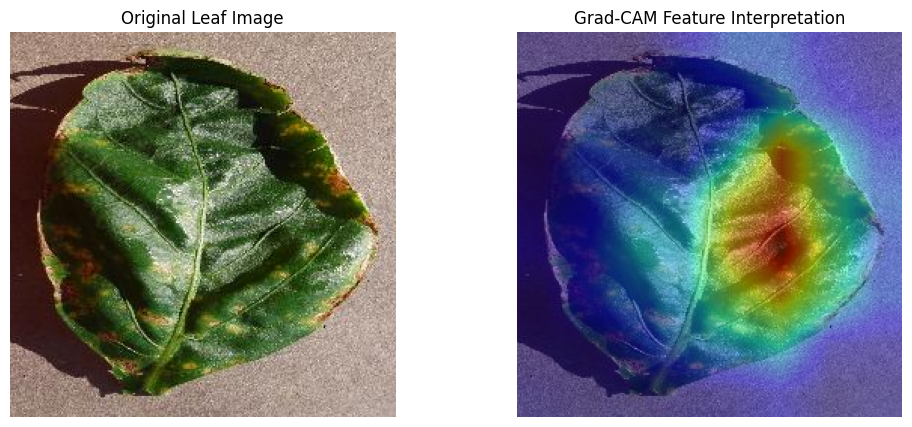

Predicted class index: 16
Grad-CAM generated successfully.


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Select a sample image
project = Path("/content/PlantCare-ML-Cycle")

sample_image = next(
    (project / "data").rglob("*.jpg")
)

# Load and preprocess image
image = Image.open(sample_image).convert("RGB").resize((256, 256))
image_array = np.array(image, dtype=np.float32) / 255.0
input_tensor = np.expand_dims(image_array, axis=0)

# Identify MobileNetV2 and its final convolutional layer
base_model = model.get_layer("mobilenetv2_1.00_224")
grad_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[
        base_model.get_layer("out_relu").output,
        base_model.output
    ]
)

# Build Grad-CAM model
with tf.GradientTape() as tape:
    # Apply preprocessing layers
    x = input_tensor

    for layer in model.layers[1:4]:
        x = layer(x, training=False)

    x = model.get_layer("rescaling")(x)

    # Extract convolutional features
    conv_outputs, base_outputs = grad_model(x, training=False)

    # Continue through classifier
    predictions = model.get_layer("global_average_pooling2d")(base_outputs)
    predictions = model.get_layer("dropout")(predictions, training=False)
    predictions = model.get_layer("dense")(predictions)

    class_index = tf.argmax(predictions[0])
    class_score = predictions[:, class_index]

# Calculate gradients
gradients = tape.gradient(class_score, conv_outputs)

# Generate heatmap
pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))

conv_outputs = conv_outputs[0]
heatmap = tf.reduce_sum(
    conv_outputs * pooled_gradients,
    axis=-1
)

heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

# Display original image and heatmap
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Leaf Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image)
plt.imshow(
    tf.image.resize(
        heatmap[..., tf.newaxis],
        (256, 256)
    ).numpy().squeeze(),
    cmap="jet",
    alpha=0.45
)
plt.title("Grad-CAM Feature Interpretation")
plt.axis("off")

plt.show()

print("Predicted class index:", int(class_index))
print("Grad-CAM generated successfully.")

In [ ]:
from pathlib import Path

p = Path("/content/PlantCare-ML-Cycle/dashboard/app.py")
lines = p.read_text().splitlines()

for start, end in [(1, 30), (60, 120), (150, 210)]:
    print(f"\n--- LINES {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


--- LINES 1-30 ---
1: 
2: import streamlit as st
3: import pandas as pd
4: import requests
5: import plotly.express as px
6: import json
7: from pathlib import Path
8: from datetime import datetime
9: 
10: PROJECT_DIR = Path(__file__).resolve().parent.parent
11: API_URL = "http://127.0.0.1:8000"
12: 
13: MONITORING_DIR = PROJECT_DIR / "reports" / "monitoring"
14: PREDICTIONS_FILE = MONITORING_DIR / "predictions.csv"
15: FEEDBACK_FILE = MONITORING_DIR / "feedback.csv"
16: CLASS_MAPPING_FILE = PROJECT_DIR / "data" / "processed" / "class_mapping.json"
17: 
18: st.set_page_config(
19:     page_title="PlantCare ML Dashboard",
20:     page_icon="🌿",
21:     layout="wide"
22: )
23: 
24: st.title("🌿 PlantCare ML Dashboard")
25: st.caption("Plant disease detection, model monitoring and performance tracking")
26: 
27: # Load class names
28: with open(CLASS_MAPPING_FILE, "r") as f:
29:     class_mapping = json.load(f)
30: 

--- LINES 60-120 ---
60: st.divider()
61: 
62: # Prediction interface
63

In [ ]:
from pathlib import Path
import shutil
import ast

dashboard = Path("/content/PlantCare-ML-Cycle/dashboard/app.py")
code = dashboard.read_text()

# Keep a backup
shutil.copy2(dashboard, "/tmp/plantcare_dashboard_before_gradcam.py")

# Add required imports
code = code.replace(
    "import json\nfrom pathlib import Path",
    "import json\nimport numpy as np\nimport tensorflow as tf\nimport matplotlib.pyplot as plt\nfrom PIL import Image\nfrom io import BytesIO\nfrom pathlib import Path"
)

# Add Grad-CAM function after class mapping is loaded
anchor = '    class_mapping = json.load(f)'

helper = '''

# Grad-CAM model interpretation
@st.cache_resource
def load_gradcam_model():
    model_path = PROJECT_DIR / "models" / "checkpoints" / "best_plantcare_mobilenetv2.keras"
    return tf.keras.models.load_model(model_path)


def generate_gradcam(image_bytes):
    image = Image.open(BytesIO(image_bytes)).convert("RGB").resize((256, 256))
    image_array = np.asarray(image, dtype=np.float32) / 255.0
    input_tensor = tf.convert_to_tensor(image_array[np.newaxis, ...])

    trained_model = load_gradcam_model()
    base_model = trained_model.get_layer("mobilenetv2_1.00_224")

    grad_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=[
            base_model.get_layer("out_relu").output,
            base_model.output
        ]
    )

    # Apply the model's rescaling layer
    x = trained_model.get_layer("rescaling")(input_tensor)

    with tf.GradientTape() as tape:
        conv_outputs, base_outputs = grad_model(x, training=False)
        predictions = trained_model.get_layer(
            "global_average_pooling2d"
        )(base_outputs)
        predictions = trained_model.get_layer("dropout")(
            predictions, training=False
        )
        predictions = trained_model.get_layer("dense")(predictions)

        class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients, axis=-1
    )
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return image, heatmap.numpy(), int(class_index)
'''

if anchor not in code:
    raise ValueError("Could not find class mapping insertion point.")

code = code.replace(anchor, anchor + helper, 1)

# Add heatmap to the successful prediction display
anchor2 = '                    st.dataframe(prediction_df, use_container_width=True)'

addition = '''

                    # Visual explanation of the prediction
                    st.subheader("🔬 Model Interpretation — Grad-CAM")
                    try:
                        original_image, heatmap, cam_class = generate_gradcam(
                            uploaded_file.getvalue()
                        )

                        resized_heatmap = tf.image.resize(
                            heatmap[..., np.newaxis],
                            (256, 256)
                        ).numpy().squeeze()

                        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
                        axes[0].imshow(original_image)
                        axes[0].set_title("Original Leaf Image")
                        axes[0].axis("off")

                        axes[1].imshow(original_image)
                        axes[1].imshow(
                            resized_heatmap, cmap="jet", alpha=0.45
                        )
                        axes[1].set_title("Grad-CAM Heatmap")
                        axes[1].axis("off")

                        plt.tight_layout()
                        st.pyplot(fig)
                        plt.close(fig)

                        st.caption(
                            "Warmer highlighted regions indicate areas that "
                            "contributed more strongly to the model's prediction."
                        )
                    except Exception as cam_error:
                        st.warning(
                            f"Grad-CAM explanation could not be generated: {cam_error}"
                        )
'''

if anchor2 not in code:
    raise ValueError("Could not find prediction display insertion point.")

code = code.replace(anchor2, anchor2 + addition, 1)

# Validate before saving
ast.parse(code)
dashboard.write_text(code)

print("SUCCESS: Grad-CAM added to the dashboard.")
print("Backup saved at /tmp/plantcare_dashboard_before_gradcam.py")
print("Python syntax: VALID")
print("Existing prediction, analytics and retraining sections preserved.")

SUCCESS: Grad-CAM added to the dashboard.
Backup saved at /tmp/plantcare_dashboard_before_gradcam.py
Python syntax: VALID
Existing prediction, analytics and retraining sections preserved.


In [ ]:
import requests
import time

dashboard_url = "http://127.0.0.1:8501"

try:
    response = requests.get(dashboard_url, timeout=10)
    print("Dashboard HTTP status:", response.status_code)
    print("Dashboard running:", response.status_code == 200)
except Exception as e:
    print("Dashboard check failed:", e)

Dashboard HTTP status: 200
Dashboard running: True


In [ ]:
import requests
import subprocess
import importlib.util

print("========== LOAD TEST ENVIRONMENT ==========")

# Check API
try:
    response = requests.get(
        "http://127.0.0.1:8000/health",
        timeout=10
    )
    print("\nAPI status:", response.status_code)
    print("API response:", response.json())
except Exception as e:
    print("\nAPI error:", e)

# Check Locust
print("\nLocust installed:", importlib.util.find_spec("locust") is not None)

# Check Docker
docker = subprocess.run(
    ["bash", "-lc", "docker --version"],
    capture_output=True,
    text=True
)
print("\nDocker CLI:", docker.stdout.strip() or docker.stderr.strip())

docker_info = subprocess.run(
    ["bash", "-lc", "docker info"],
    capture_output=True,
    text=True
)
print("Docker daemon available:", docker_info.returncode == 0)

if docker_info.returncode != 0:
    print("Docker status:", docker_info.stderr[:500])

========== LOAD TEST ENVIRONMENT ==========

API status: 200
API response: {'status': 'healthy', 'model_loaded': True, 'model_name': 'plantcare_mobilenetv2', 'number_of_classes': 27}

Locust installed: False

Docker CLI: bash: line 1: docker: command not found
Docker daemon available: False
Docker status: bash: line 1: docker: command not found



In [ ]:
%pip install locust

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 14.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 37.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 25.7 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [locust]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
from pathlib import Path
import importlib.util
import subprocess

print("========== RUNTIME RECOVERY ==========")

for path in [
    "/content/PlantCare-ML-Cycle",
    "/content/drive/MyDrive/PlantCare_ML_Cycle",
]:
    print(path, "EXISTS:", Path(path).exists())

print("\nLocust installed:", importlib.util.find_spec("locust") is not None)

print("\nGit:")
if Path("/content/PlantCare-ML-Cycle").exists():
    result = subprocess.run(
        ["git", "log", "-1", "--oneline"],
        cwd="/content/PlantCare-ML-Cycle",
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr)

========== RUNTIME RECOVERY ==========
/content/PlantCare-ML-Cycle EXISTS: True
/content/drive/MyDrive/PlantCare_ML_Cycle EXISTS: True

Locust installed: True

Git:
2190881 Update API, dashboard and retraining workflow



In [ ]:
import subprocess
import sys
import requests
import time
from pathlib import Path

project = Path("/content/PlantCare-ML-Cycle")
api_dir = project / "api"

api = subprocess.Popen([
    sys.executable, "-m", "uvicorn",
    "api:app",
    "--app-dir", str(api_dir),
    "--host", "127.0.0.1",
    "--port", "8000"
])

time.sleep(15)

response = requests.get("http://127.0.0.1:8000/health", timeout=20)

print("API status:", response.status_code)
print("API response:", response.json())

API status: 200
API response: {'status': 'healthy', 'model_loaded': True, 'model_name': 'plantcare_mobilenetv2', 'number_of_classes': 27}


In [ ]:
from pathlib import Path

search_roots = [
    Path("/content/PlantCare-ML-Cycle/data"),
    Path("/content/drive/MyDrive/PlantCare_ML_Cycle/data")
]

image_file = None

for root in search_roots:
    if root.exists():
        for extension in ("*.jpg", "*.jpeg", "*.png"):
            image_file = next(root.rglob(extension), None)
            if image_file:
                break
    if image_file:
        break

if image_file:
    print("Test image found:", image_file)
    print("File size (KB):", round(image_file.stat().st_size / 1024, 2))
else:
    print("No test image found in the project data folders.")

Test image found: /content/PlantCare-ML-Cycle/data/incoming_training/Pepper___Bacterial Spot/eec1c57b40b7401da7777586aae120f5.jpg
File size (KB): 20.24


In [ ]:
from pathlib import Path
import subprocess
import sys

project = Path("/content/PlantCare-ML-Cycle")
report_dir = project / "reports" / "load_testing"
report_dir.mkdir(parents=True, exist_ok=True)

image_path = "/content/PlantCare-ML-Cycle/data/incoming_training/Pepper___Bacterial Spot/eec1c57b40b7401da7777586aae120f5.jpg"

locust_file = report_dir / "locustfile.py"

locust_code = f'''
from locust import HttpUser, task, between

IMAGE_PATH = r"{image_path}"

class PlantCareUser(HttpUser):
    wait_time = between(1, 2)

    @task
    def predict_plant_disease(self):
        with open(IMAGE_PATH, "rb") as image:
            response = self.client.post(
                "/predict",
                files={{"file": ("test_leaf.jpg", image, "image/jpeg")}},
                name="/predict"
            )

        if response.status_code != 200:
            response.failure(f"Prediction failed: {{response.status_code}}")
'''

locust_file.write_text(locust_code)

command = [
    sys.executable, "-m", "locust",
    "-f", str(locust_file),
    "--host", "http://127.0.0.1:8000",
    "--headless",
    "-u", "5",
    "-r", "1",
    "-t", "30s",
    "--csv", str(report_dir / "locust"),
    "--csv-full-history"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True,
    timeout=120
)

print("LOCUST OUTPUT:")
print(result.stdout)
print("LOCUST ERRORS:")
print(result.stderr)
print("EXIT CODE:", result.returncode)
print("\nREPORT FILES:")
for f in report_dir.glob("locust*"):
    print(f.name, f.stat().st_size, "bytes")

LOCUST OUTPUT:

LOCUST ERRORS:
[2026-11-26 22:38:27,983] d90e303e3ab6/INFO/locust.main: Starting Locust 2.47.0
[2026-11-26 22:38:27,984] d90e303e3ab6/INFO/locust.main: Run time limit set to 30 seconds
Type     Name                                                                          # reqs      # fails |    Avg     Min     Max    Med |   req/s  failures/s
--------|----------------------------------------------------------------------------|-------|-------------|-------|-------|-------|-------|--------|-----------
--------|----------------------------------------------------------------------------|-------|-------------|-------|-------|-------|-------|--------|-----------
         Aggregated                                                                         0     0(0.00%) |      0       0       0      0 |    0.00        0.00

[2026-11-26 22:38:27,987] d90e303e3ab6/INFO/locust.runners: Ramping to 5 users at a rate of 1.00 per second
Type     Name                                 

In [ ]:
from pathlib import Path
import pandas as pd

project = Path("/content/PlantCare-ML-Cycle")
report_dir = project / "reports" / "load_testing"

print("========== DOCKER AND LOAD TEST INSPECTION ==========")

for name in [
    "Dockerfile",
    "docker-compose.yml",
    "docker-compose.yaml",
    "compose.yaml",
    "requirements.txt",
    "README.md"
]:
    matches = list(project.rglob(name))
    print(f"\n{name}:")
    for item in matches:
        print(" ", item.relative_to(project))

print("\n========== LOCUST RESULTS ==========")

stats_file = report_dir / "locust_stats.csv"

if stats_file.exists():
    df = pd.read_csv(stats_file)
    print(df.to_string(index=False))
else:
    print("Locust statistics CSV not found.")

print("\n========== LOAD TEST REPORT FILES ==========")
for file in sorted(report_dir.iterdir()):
    print(file.name)

========== DOCKER AND LOAD TEST INSPECTION ==========

Dockerfile:

docker-compose.yml:

docker-compose.yaml:

compose.yaml:

requirements.txt:
  requirements.txt

README.md:
  README.md

========== LOCUST RESULTS ==========
Type       Name  Request Count  Failure Count  Median Response Time  Average Response Time  Min Response Time  Max Response Time  Average Content Size  Requests/s  Failures/s  50%  66%  75%  80%  90%  95%  98%  99%  99.9%  99.99%  100%
POST   /predict             84              0                   130             164.504707          90.940918         1090.28382                 601.0    2.945437         0.0  130  160  190  210  240  310  390 1100   1100    1100  1100
 NaN Aggregated             84              0                   130             164.504707          90.940918         1090.28382                 601.0    2.945437         0.0  130  160  190  210  240  310  390 1100   1100    1100  1100

========== LOAD TEST REPORT FILES ==========
__pycache__
locust_ex

In [ ]:
from pathlib import Path

project = Path("/content/PlantCare-ML-Cycle")

print("========== REQUIREMENTS ==========")
requirements = project / "requirements.txt"
if requirements.exists():
    print(requirements.read_text())
else:
    print("requirements.txt not found")

for filename in ["api/api.py", "dashboard/app.py"]:
    path = project / filename
    print(f"\n========== {filename} ==========")
    if path.exists():
        lines = path.read_text().splitlines()
        print("\n".join(
            line for line in lines
            if line.startswith(("import ", "from "))
            or any(term in line.lower() for term in [
                "api_url", "base_url", "localhost", "127.0.0.1",
                "st.set_page_config", "uvicorn", "streamlit"
            ])
        ))
    else:
        print("File not found")

print("\n========== PROJECT ROOT ==========")
for item in sorted(project.iterdir()):
    print(("[DIR] " if item.is_dir() else "[FILE] ") + item.name)

========== REQUIREMENTS ==========
tensorflow==2.21.0
numpy
Pillow
fastapi==0.141.1
uvicorn[standard]==0.54.0
python-multipart
pydantic
streamlit==1.67.0
pandas
requests
plotly==5.24.1


========== api/api.py ==========
import csv
import io
import json
import os
import shutil
import time
import uuid
import zipfile
from datetime import datetime, timezone
import numpy as np
import tensorflow as tf
from PIL import Image, UnidentifiedImageError
from pydantic import BaseModel
from fastapi import FastAPI, File, HTTPException, UploadFile

========== dashboard/app.py ==========
import streamlit as st
import pandas as pd
import requests
import plotly.express as px
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from pathlib import Path
from datetime import datetime
API_URL = "http://127.0.0.1:8000"
st.set_page_config(
    health = requests.get(f"{API_URL}/health", timeout=5).json()
    metrics = requests.get(f"{

In [ ]:
from pathlib import Path

project = Path("/content/PlantCare-ML-Cycle")

# 1. Docker image
(project / "Dockerfile").write_text("""
FROM python:3.11-slim

WORKDIR /app

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY . .

EXPOSE 8000 8501
""".strip() + "\n")

# 2. Docker Compose
(project / "docker-compose.yml").write_text("""
services:
  api:
    build: .
    command: uvicorn api:app --app-dir /app/api --host 0.0.0.0 --port 8000
    environment:
      PYTHONUNBUFFERED: "1"
    volumes:
      - ./models:/app/models
      - ./reports/monitoring:/app/reports/monitoring
      - ./data/incoming_training:/app/data/incoming_training
    restart: unless-stopped

  load-balancer:
    image: haproxy:3.0
    ports:
      - "8000:8000"
    volumes:
      - ./haproxy.cfg:/usr/local/etc/haproxy/haproxy.cfg:ro
    depends_on:
      - api
    restart: unless-stopped

  dashboard:
    build: .
    command: streamlit run dashboard/app.py --server.address 0.0.0.0 --server.port 8501
    environment:
      API_URL: http://load-balancer:8000
    ports:
      - "8501:8501"
    volumes:
      - ./models:/app/models
      - ./reports/monitoring:/app/reports/monitoring
    depends_on:
      - load-balancer
    restart: unless-stopped
""".strip() + "\n")

# 3. Load balancer configuration
(project / "haproxy.cfg").write_text("""
global
    log stdout format raw local0

defaults
    log global
    mode http
    timeout connect 10s
    timeout client 120s
    timeout server 120s

resolvers docker
    nameserver dns 127.0.0.11:53
    resolve_retries 3
    timeout resolve 1s
    timeout retry 1s
    hold valid 10s

frontend plantcare_frontend
    bind *:8000
    default_backend plantcare_api

backend plantcare_api
    balance roundrobin
    server-template api 10 api:8000 check resolvers docker init-addr libc,none
""".strip() + "\n")

# 4. Ensure dashboard uses the container-network API address when deployed
dashboard_file = project / "dashboard" / "app.py"
dashboard_code = dashboard_file.read_text()

if 'import os' not in dashboard_code:
    dashboard_code = dashboard_code.replace(
        'import streamlit as st',
        'import os\nimport streamlit as st',
        1
    )

dashboard_code = dashboard_code.replace(
    'API_URL = "http://127.0.0.1:8000"',
    'API_URL = os.getenv("API_URL", "http://127.0.0.1:8000")'
)

dashboard_file.write_text(dashboard_code)

# 5. Exclude unnecessary large files from Docker build context
(project / ".dockerignore").write_text("""
.git
__pycache__
*.pyc
.ipynb_checkpoints
data/raw
data/train
data/valid
data/test
""".strip() + "\n")

print("Docker deployment files created:")
for name in ["Dockerfile", "docker-compose.yml", "haproxy.cfg", ".dockerignore"]:
    path = project / name
    print(f"{name}: {'EXISTS' if path.exists() else 'MISSING'} ({path.stat().st_size if path.exists() else 0} bytes)")

print("\nDashboard API configuration:")
for line in dashboard_code.splitlines():
    if "API_URL =" in line:
        print(line)

Docker deployment files created:
Dockerfile: EXISTS (194 bytes)
docker-compose.yml: EXISTS (900 bytes)
haproxy.cfg: EXISTS (491 bytes)
.dockerignore: EXISTS (83 bytes)

Dashboard API configuration:
API_URL = os.getenv("API_URL", "http://127.0.0.1:8000")


In [ ]:
from pathlib import Path

p = Path("/content/PlantCare-ML-Cycle/dashboard/app.py")

line = next(
    x for x in p.read_text().splitlines()
    if x.strip().startswith("API_URL =")
)

print("Line:", repr(line))
print("Character codes:", [ord(c) for c in line if c in "[]()"])
print("URL fallback:", repr(line.split(",", 1)[-1]))

Line: 'API_URL = os.getenv("API_URL", "http://127.0.0.1:8000")'
Character codes: [40, 41]
URL fallback: ' "http://127.0.0.1:8000")'


In [ ]:
import os

API_URL = os.getenv("API_URL", "http://127.0.0.1:8000")

print("Actual fallback:", repr(API_URL))
print("Starts with http://:", API_URL.startswith("http://"))
print("Contains Markdown link syntax:", "](" in API_URL)

Actual fallback: 'http://127.0.0.1:8000'
Starts with http://: True
Contains Markdown link syntax: False


In [ ]:
from pathlib import Path
import yaml

project = Path("/content/PlantCare-ML-Cycle")

print("========== MODEL FILES ==========")
for p in (project / "models").rglob("*.keras"):
    print(p.relative_to(project), f"{p.stat().st_size / 1024 / 1024:.2f} MB")

print("\n========== CLASS MAPPING ==========")
mapping = project / "data/processed/class_mapping.json"
print("Exists:", mapping.exists())

print("\n========== DOCKER COMPOSE ==========")
compose = yaml.safe_load((project / "docker-compose.yml").read_text())
for service, config in compose["services"].items():
    print(service, "->", config.get("command", config.get("image", "built image")))

print("\n========== REQUIREMENTS ==========")
print((project / "requirements.txt").read_text())

print("\n========== DOCKER IGNORE ==========")
print((project / ".dockerignore").read_text())

========== MODEL FILES ==========
models/checkpoints/best_plant_disease_model.keras 2.26 MB
models/checkpoints/best_plantcare_mobilenetv2.keras 9.57 MB
models/backups/plantcare_backup_20261126_211404.keras 9.58 MB
models/candidates/plantcare_candidate_20261126_211404.keras 9.57 MB

========== CLASS MAPPING ==========
Exists: True

========== DOCKER COMPOSE ==========
api -> uvicorn api:app --app-dir /app/api --host 0.0.0.0 --port 8000
load-balancer -> haproxy:3.0
dashboard -> streamlit run dashboard/app.py --server.address 0.0.0.0 --server.port 8501

========== REQUIREMENTS ==========
tensorflow==2.21.0
numpy
Pillow
fastapi==0.141.1
uvicorn[standard]==0.54.0
python-multipart
pydantic
streamlit==1.67.0
pandas
requests
plotly==5.24.1


========== DOCKER IGNORE ==========
.git
__pycache__
*.pyc
.ipynb_checkpoints
data/raw
data/train
data/valid
data/test



In [ ]:
from pathlib import Path
import yaml

project = Path("/content/PlantCare-ML-Cycle")

compose = yaml.safe_load(
    (project / "docker-compose.yml").read_text()
)

required_services = {"api", "load-balancer", "dashboard"}

assert required_services.issubset(compose["services"])
assert compose["services"]["api"]["build"] == "."
assert compose["services"]["load-balancer"]["image"] == "haproxy:3.0"
assert compose["services"]["dashboard"]["build"] == "."

print("Compose YAML: VALID")
print("Required services: PRESENT")
print("API port: 8000")
print("Dashboard port: 8501")
print("Load balancer: HAProxy")
print("\nDocker CLI available in Colab:")

import shutil
print(shutil.which("docker") or "No — Docker must be run on a machine with Docker installed.")

Compose YAML: VALID
Required services: PRESENT
API port: 8000
Dashboard port: 8501
Load balancer: HAProxy

Docker CLI available in Colab:
No — Docker must be run on a machine with Docker installed.


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")

requirements = """tensorflow==2.21.0
numpy
Pillow
fastapi==0.141.1
uvicorn[standard]==0.54.0
python-multipart
pydantic
streamlit==1.67.0
pandas
requests
plotly==5.24.1
"""

requirements_path = PROJECT_DIR / "requirements.txt"
requirements_path.write_text(requirements)

print("requirements.txt created successfully!")
print("\nCONTENTS:")
print(requirements_path.read_text())
print("File exists:", requirements_path.exists())

requirements.txt created successfully!

CONTENTS:
tensorflow==2.21.0
numpy
Pillow
fastapi==0.141.1
uvicorn[standard]==0.54.0
python-multipart
pydantic
streamlit==1.67.0
pandas
requests
plotly==5.24.1

File exists: True


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")

gitignore_content = """# Dataset files
data/raw/
data/train/
data/valid/
data/test/

# Credentials and secrets
.env
.env.*
kaggle.json
**/kaggle.json

# Python
__pycache__/
*.py[cod]
*.pyo
*.pyd
.Python
venv/
.venv/
env/

# Jupyter and Colab
.ipynb_checkpoints/
*/.ipynb_checkpoints/

# System files
.DS_Store
Thumbs.db

# Logs and temporary files
*.log
*.tmp
*.bak

# IDE settings
.vscode/
.idea/
"""

gitignore_path = PROJECT_DIR / ".gitignore"
gitignore_path.write_text(gitignore_content)

print(".gitignore created successfully!")
print(gitignore_path.read_text())

.gitignore created successfully!
# Dataset files
data/raw/
data/train/
data/valid/
data/test/

# Credentials and secrets
.env
.env.*
kaggle.json
**/kaggle.json

# Python
__pycache__/
*.py[cod]
*.pyo
*.pyd
.Python
venv/
.venv/
env/

# Jupyter and Colab
.ipynb_checkpoints/
*/.ipynb_checkpoints/

# System files
.DS_Store
Thumbs.db

# Logs and temporary files
*.log
*.tmp
*.bak

# IDE settings
.vscode/
.idea/



In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")

print("=" * 65)
print("PLANTCARE PROJECT FILE AUDIT")
print("=" * 65)

for path in sorted(PROJECT_DIR.rglob("*")):
    if any(part in {".ipynb_checkpoints", "__pycache__", ".git"} for part in path.parts):
        continue

    relative_path = path.relative_to(PROJECT_DIR)

    if path.is_file():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"FILE  | {relative_path} | {size_mb:.2f} MB")
    else:
        print(f"DIR   | {relative_path}/")

print("\n" + "=" * 65)
print("IMPORTANT FILE CHECK")
print("=" * 65)

required_files = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "api/api.py",
    "dashboard/app.py",
    "models/checkpoints/best_plantcare_mobilenetv2.keras",
    "data/processed/class_mapping.json",
]

for item in required_files:
    exists = (PROJECT_DIR / item).exists()
    print(f"{'✓' if exists else '✗'} {item}")

Streaming output truncated to the last 5000 lines.
FILE  | data/raw/valid/Pepper/Bacterial Spot/81d96896-2e99-4eaf-b86e-c2d8c6a3eabb___NREC_B.Spot 1818_flipTB.JPG | 0.02 MB
FILE  | data/raw/valid/Pepper/Bacterial Spot/8289c053-a0c4-4740-9fd8-fd316b6f5688___JR_B.Spot 3299_180deg.JPG | 0.02 MB
FILE  | data/raw/valid/Pepper/Bacterial Spot/8294cabb-990b-4e0b-9351-441c91fa9e28___NREC_B.Spot 1941_180deg.JPG | 0.02 MB
FILE  | data/raw/valid/Pepper/Bacterial Spot/8294cabb-990b-4e0b-9351-441c91fa9e28___NREC_B.Spot 1941_flipTB.JPG | 0.02 MB
FILE  | data/raw/valid/Pepper/Bacterial Spot/8295d0d3-a2b8-4f32-ac02-7e0ee8f75406___NREC_B.Spot 1790.JPG | 0.02 MB
FILE  | data/raw/valid/Pepper/Bacterial Spot/8295d0d3-a2b8-4f32-ac02-7e0ee8f75406___NREC_B.Spot 1790_flipTB.JPG | 0.02 MB
FILE  | data/raw/valid/Pepper/Bacterial Spot/836b4b9e-85d5-47bc-ad93-9ab31b07be3d___JR_B.Spot 3361_flipTB.JPG | 0.02 MB
FILE  | data/raw/valid/Pepper/Bacterial Spot/8485adde-4e43-4c10-a9b1-be320de27869___NREC_B.Spot 9164_180de

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")

print("PROJECT FOLDERS:")
for p in sorted(PROJECT_DIR.iterdir()):
    if p.is_dir():
        print("📁", p.name)

print("\nIMPORTANT FILES:")
required = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "api/api.py",
    "dashboard/app.py",
    "models/checkpoints/best_plantcare_mobilenetv2.keras",
    "data/processed/class_mapping.json",
]

for f in required:
    print(("✓ " if (PROJECT_DIR / f).exists() else "✗ ") + f)

print("\nREPORT FILES:")
reports = PROJECT_DIR / "reports"
if reports.exists():
    for f in reports.rglob("*"):
        if f.is_file():
            print(f.relative_to(PROJECT_DIR))

PROJECT FOLDERS:
📁 api
📁 app
📁 dashboard
📁 data
📁 deployment
📁 load_test
📁 models
📁 notebook
📁 reports
📁 src
📁 uploads

IMPORTANT FILES:
✗ README.md
✓ requirements.txt
✓ .gitignore
✓ api/api.py
✓ dashboard/app.py
✓ models/checkpoints/best_plantcare_mobilenetv2.keras
✓ data/processed/class_mapping.json

REPORT FILES:
reports/mobilenetv2/evaluation_metrics.json
reports/mobilenetv2/classification_report.csv
reports/mobilenetv2/confusion_matrix.csv
reports/mobilenetv2/misclassification_analysis.csv
reports/mobilenetv2/model_metadata.json
reports/monitoring/predictions.csv
reports/monitoring/feedback.csv
reports/monitoring/api_server.log
reports/monitoring/dashboard_server.log
reports/monitoring/retraining_requests.csv


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")

for folder in ["app", "deployment", "load_test", "src", "uploads", "notebook"]:
    path = PROJECT_DIR / folder
    files = [f for f in path.rglob("*") if f.is_file()]

    print(f"{folder}/: {len(files)} files")

    for f in files[:8]:
        print("  -", f.relative_to(PROJECT_DIR))

    if len(files) > 8:
        print(f"  ... and {len(files) - 8} more")

app/: 0 files
deployment/: 0 files
load_test/: 0 files
src/: 0 files
uploads/: 0 files
notebook/: 0 files


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")

print("ROOT FILES:")
for f in sorted(PROJECT_DIR.iterdir()):
    if f.is_file():
        print("-", f.name)

print("\nMODEL FILES:")
for f in (PROJECT_DIR / "models").rglob("*"):
    if f.is_file():
        print(f"- {f.relative_to(PROJECT_DIR)} ({f.stat().st_size / 1024 / 1024:.2f} MB)")

print("\nREPORTS (excluding logs):")
for f in (PROJECT_DIR / "reports").rglob("*"):
    if f.is_file() and f.suffix != ".log":
        print("-", f.relative_to(PROJECT_DIR))

print("\nNOTEBOOK FILES:")
for f in (PROJECT_DIR / "notebook").rglob("*"):
    if f.is_file():
        print("-", f.relative_to(PROJECT_DIR))

ROOT FILES:
- .gitignore
- requirements.txt

MODEL FILES:
- models/training_history.csv (0.00 MB)
- models/mobilenetv2_training_history.csv (0.00 MB)
- models/checkpoints/best_plant_disease_model.keras (2.26 MB)
- models/checkpoints/best_plantcare_mobilenetv2.keras (9.58 MB)

REPORTS (excluding logs):
- reports/mobilenetv2/evaluation_metrics.json
- reports/mobilenetv2/classification_report.csv
- reports/mobilenetv2/confusion_matrix.csv
- reports/mobilenetv2/misclassification_analysis.csv
- reports/mobilenetv2/model_metadata.json
- reports/monitoring/predictions.csv
- reports/monitoring/feedback.csv
- reports/monitoring/retraining_requests.csv

NOTEBOOK FILES:


In [ ]:
import os
from pathlib import Path

REPO_URL = "https://github.com/kylaochweri/PlantCare-ML-Cycle.git"
CLONE_DIR = Path("/content/PlantCare-ML-Cycle")

if not CLONE_DIR.exists():
    !git clone {REPO_URL} {CLONE_DIR}
else:
    print("Repository already cloned.")

print("\nRepository contents:")
for item in sorted(CLONE_DIR.iterdir()):
    print(item.name)

Cloning into '/content/PlantCare-ML-Cycle'...
remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 6 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (6/6), 4.66 KiB | 2.33 MiB/s, done.

Repository contents:
.git
README.md


In [ ]:

from google.colab import drive, files
import os
import zipfile

# Reconnect Google Drive
drive.mount('/content/drive')

project = '/content/drive/MyDrive/PlantCare_ML_Cycle'
sample_path = '/content/plantcare_sample.jpg'

# First, look for an already extracted image
image_extensions = ('.jpg', '.jpeg', '.png')
found_image = None

for current_dir, folders, filenames in os.walk(os.path.join(project, 'data')):
    for filename in filenames:
        if filename.lower().endswith(image_extensions):
            found_image = os.path.join(current_dir, filename)
            break
    if found_image:
        break

# If images are only inside the original ZIP, extract just one
if found_image:
    import shutil
    shutil.copy2(found_image, sample_path)
    print("Found extracted image:", found_image)
else:
    zip_path = os.path.join(
        project, 'data', 'raw',
        'plant-disease-detection-dataset.zip'
    )

    if not os.path.exists(zip_path):
        raise FileNotFoundError("Could not find the dataset ZIP in Google Drive.")

    with zipfile.ZipFile(zip_path) as archive:
        image_member = next(
            (name for name in archive.namelist()
             if name.lower().endswith(image_extensions)
             and name.split('/')[0].lower() in ('train', 'valid', 'test')),
            None
        )

        if image_member is None:
            raise FileNotFoundError("No plant images found inside the ZIP.")

        with archive.open(image_member) as source:
            with open(sample_path, 'wb') as destination:
                destination.write(source.read())

        print("Extracted one image from:", image_member)

print("Sample ready:", sample_path)
files.download(sample_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found extracted image: /content/drive/MyDrive/PlantCare_ML_Cycle/data/raw/test/AppleCedarRust1.JPG
Sample ready: /content/plantcare_sample.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for p in PROJECT.rglob("*.zip"):
    print(p, f"({p.stat().st_size / (1024**3):.2f} GB)")

/content/drive/MyDrive/PlantCare_ML_Cycle/data/raw/plant-disease-detection-dataset.zip (0.94 GB)


In [ ]:

import zipfile
from pathlib import Path
from collections import defaultdict
import random
import io

PROJECT = Path("/content/drive/MyDrive/PlantCare_ML_Cycle")
SOURCE_ZIP = PROJECT / "data/raw/plant-disease-detection-dataset.zip"
OUTPUT_DIR = PROJECT / "demo_assets"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
random.seed(42)

single_targets = [
    ("Apple", "Cedar Apple Rust"),
    ("Tomato", "Late Blight"),
    ("Potato", "Early Blight"),
]

with zipfile.ZipFile(SOURCE_ZIP, "r") as source:

    # Group training and validation images by crop/disease
    train_groups = defaultdict(list)
    valid_groups = defaultdict(list)

    for name in source.namelist():
        parts = name.split("/")

        if len(parts) < 4:
            continue

        split, crop, disease = parts[:3]

        if Path(name).suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        if split == "train":
            train_groups[(crop, disease)].append(name)
        elif split == "valid":
            valid_groups[(crop, disease)].append(name)

    print("TRAIN CLASSES FOUND:", len(train_groups))
    print("VALIDATION CLASSES FOUND:", len(valid_groups))

    if len(train_groups) != 27:
        print("\nDiscovered training classes:")
        for crop, disease in sorted(train_groups):
            print(crop, "___", disease)
        raise ValueError("Expected 27 training classes. Stopped safely.")

    # Create individual prediction images
    singles_dir = OUTPUT_DIR / "single_prediction_images"
    singles_dir.mkdir(exist_ok=True)

    for crop, target_disease in single_targets:
        matches = [
            key for key in train_groups
            if key[0].lower() == crop.lower()
            and key[1].lower() == target_disease.lower()
        ]

        if not matches:
            print("Could not find:", crop, target_disease)
            continue

        key = matches[0]
        candidates = valid_groups.get(key) or train_groups[key]
        image_name = candidates[0]

        output_name = f"{crop}_{target_disease.replace(' ', '_')}{Path(image_name).suffix}"
        (singles_dir / output_name).write_bytes(source.read(image_name))

        print("Created prediction image:", output_name)

    # Create bulk ZIP: 20 images per class
    bulk_path = OUTPUT_DIR / "bulk_training_demo.zip"

    with zipfile.ZipFile(bulk_path, "w", zipfile.ZIP_DEFLATED) as bulk:
        for (crop, disease), images in sorted(train_groups.items()):
            selected = random.sample(images, min(20, len(images)))

            class_label = f"{crop}___{disease.title()}"

            for image_name in selected:
                filename = Path(image_name).name
                archive_name = f"{class_label}/{filename}"
                bulk.writestr(archive_name, source.read(image_name))

    print("\nBulk ZIP created:", bulk_path)
    print("Bulk image count:", sum(
        min(20, len(images)) for images in train_groups.values()
    ))

# Create the outer package
bundle_path = PROJECT / "PlantCare_Demo_Assets.zip"

with zipfile.ZipFile(bundle_path, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in singles_dir.iterdir():
        bundle.write(file, f"single_prediction_images/{file.name}")

    bundle.write(bulk_path, "bulk_training_demo.zip")

    readme = """
PLANTCARE DEMO ASSETS

single_prediction_images:
Use these individual images in the dashboard prediction interface.

bulk_training_demo.zip:
Use this ZIP in the dashboard bulk-upload section.
It contains up to 20 original training images per class.

IMPORTANT:
These are images from the original dataset, not independent
real-world field images. Demo predictions demonstrate the
pipeline and are not proof of field performance.
"""
    bundle.writestr("README.txt", readme)

print("\nSUCCESS!")
print("FINAL PACKAGE:", bundle_path)
print("SIZE (MB):", round(bundle_path.stat().st_size / (1024 * 1024), 2))

from google.colab import files
files.download(str(bundle_path))


TRAIN CLASSES FOUND: 27
VALIDATION CLASSES FOUND: 27
Created prediction image: Apple_Cedar_Apple_Rust.JPG
Created prediction image: Tomato_Late_Blight.JPG
Created prediction image: Potato_Early_Blight.JPG

Bulk ZIP created: /content/drive/MyDrive/PlantCare_ML_Cycle/demo_assets/bulk_training_demo.zip
Bulk image count: 540

SUCCESS!
FINAL PACKAGE: /content/drive/MyDrive/PlantCare_ML_Cycle/PlantCare_Demo_Assets.zip
SIZE (MB): 8.35


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>